In [12]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"S:\data\latentseq\RM10\rm10_day11_20250815"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="Rat"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
try:
    # Try default loader
    epoch_df = loading.load_epoch(basepath)
except Exception as e:
    print(f"load_epoch failed with error: {e}")
    print("Falling back to manual .mat file load...")

    # Load the .mat file
    mat = sio.loadmat(os.path.join(basepath, "DayNight25.MergePoints.events.mat"), squeeze_me=True)

    # Extract the 'MergePoints' structure
    merge_points = mat['MergePoints']

    # Extract the timestamps array: shape (N, 2)
    timestamps = merge_points['timestamps']  # this is the field you're interested in
    # Unwrap the array inside
    timestamps = np.array(timestamps.tolist())

    # Now you should have shape (N, 2)
    epoch_df = pd.DataFrame(timestamps, columns=["startTime", "stopTime"])

sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")

Folder already exists: W:\data\PPP\PPP20\day5\complex_system
number of cells: 297


In [13]:
import os, re, numpy as np, pandas as pd
import glob  # <-- add this
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    # pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    pats = [f"*_{region}_D2_time_resolvedforplot.mat", f"*_{region}_D2_timeforplot.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Test the complete loading function
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

❌ Failed: No *_CA1_D2_time*.mat under W:\data\PPP\PPP20\day5\complex_system



Traceback (most recent call last):
  File "C:\Users\Cornell\AppData\Local\Temp\ipykernel_70220\39668419.py", line 210, in <module>
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
                                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Cornell\AppData\Local\Temp\ipykernel_70220\39668419.py", line 67, in load_d2_timeline_complete
    raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")
FileNotFoundError: No *_CA1_D2_time*.mat under W:\data\PPP\PPP20\day5\complex_system


In [16]:
ca1_complete_df

,center_s,d2,d2_err,state
0,54.0,0.161515,NaN,WAKE
1,56.0,0.168827,NaN,WAKE
2,58.0,0.168394,NaN,WAKE
3,60.0,0.176545,NaN,WAKE
4,62.0,0.179839,NaN,WAKE
...,...,...,...,...
10166,29527.0,0.117421,NaN,NREM
10167,29529.0,0.107635,NaN,NREM
10168,29531.0,0.107133,NaN,NREM
10169,29533.0,0.104928,NaN,NREM


In [17]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,presleep_pulseStim_230302_084139,0.0000,7270.22715,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23
1,presleep_230302_104425,7270.2272,17019.59035,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23
2,tmaze_training_230302_132911,17019.5904,18998.13755,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23
3,postsleep_230302_140330,18998.1376,29567.56475,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23


In [18]:
# from pathlib import Path
# import pandas as pd, numpy as np
# from pathlib import Path
# import numpy as np, pandas as pd
# from scipy.io import loadmat

# def load_behavior_trials(basepath, basename="day7"):
#     p = Path(basepath) / f"{basename}.animal.behavior.mat"
#     m = loadmat(str(p), squeeze_me=True, struct_as_record=False)  # classic .mat
#     beh = m.get("behavior", None)
#     if beh is None:
#         raise KeyError("No 'behavior' in MAT file")
#     tr = getattr(beh, "trials", None)
#     speed = getattr(beh, "speed_smooth", None)


#     return speed,tr
# speed,trials = load_behavior_trials(basepath, basename=basename)



In [14]:
import numpy as np
from scipy.signal import welch
import nelpy as nel

def _flatten_spike_times(spike_times):
    """Accepts list/tuple/array of arrays or a single 1D array, returns sorted 1D float array."""
    if isinstance(spike_times, (list, tuple)):
        # list of arrays or scalars
        if len(spike_times) == 0:
            return np.array([], dtype=float)
        if hasattr(spike_times[0], "__len__") and not np.isscalar(spike_times[0]):
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in spike_times if st is not None and len(st) > 0])
        else:
            times = np.asarray(spike_times, dtype=float).ravel()
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            times = np.concatenate([np.asarray(st, dtype=float).ravel()
                                    for st in arr if st is not None and len(st) > 0])
        else:
            times = arr.astype(float).ravel()

    times = times[np.isfinite(times)]
    if times.size == 0:
        raise ValueError("No valid spike times found after flattening.")
    return np.sort(times)

def bin_spikes(spike_times, bin_size=0.04, t_start=None, t_stop=None):
    st = _flatten_spike_times(spike_times)  # <-- key fix
    if t_start is None: t_start = float(np.floor(st.min()))
    if t_stop  is None: t_stop  = float(np.ceil(st.max()))
    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    counts, _ = np.histogram(st, bins=edges)
    rates = counts / bin_size
    t = edges[:-1] + bin_size/2
    return t, rates

# def segments_from_epochs(t, x, epochs):
#     arr = epochs.data if isinstance(epochs, nel.EpochArray) else np.asarray(epochs)
#     return [x[(t >= s) & (t < e)] for s, e in arr if np.any((t >= s) & (t < e))]


In [20]:
# nrem_epochs = nel.EpochArray(state_dict["NREMstate"])
# awake_epochs = nel.EpochArray(state_dict["WAKEstate"])
# # WAKE across the whole session
# # awake_all = nel.EpochArray(state_dict["WAKEstate"])

# # # Build an EpochArray from epoch_df rows 1 and 3
# # sel_idx = [1, 3]  # freeT1 and freeT2 in your screenshot
# # task_iv = epoch_df.loc[sel_idx, ['startTime','stopTime']].to_numpy()
# # task_epochs = nel.EpochArray(task_iv)

# # # Keep only the WAKE that falls inside those two epochs
# # awake_in_task = (awake_all & task_epochs)
# # awake_in_task = awake_in_task[awake_in_task.durations > 0]  # drop empty


# power_spectrum_results = state_power_spectra(
#     E_spikes,  # list/array of per-neuron spike arrays is fine now
#     {"NREMstate": nrem_epochs, "WAKEstate": awake_epochs, "REMstate": rem_epochs},
#     bin_size=0.04, fmin_target=0.1
# )


In [15]:
# Create plot for random 200 second segment containing all states
import matplotlib.pyplot as plt
import numpy as np
import random

# First compute MUA from spike times
print("Computing MUA firing rate from spike times...")
print("="*50)

# Compute MUA firing rate with 0.04 second bins
time_bins, firing_rate = bin_spikes(spike_times, bin_size=0.04)

Computing MUA firing rate from spike times...


In [5]:
import numpy as np
import pandas as pd

# --- Inputs assumed to exist ---
# spike_times  # used earlier to make MUA; not needed again here
# time_bins, firing_rate  # from bin_spikes(..., bin_size=0.04)
# ca1_complete_df          # has a 'center_s' column

# 1) Make sure we have bin *centers* that match firing_rate length
tb = np.asarray(time_bins, float).ravel()
fr = np.asarray(firing_rate, float).ravel()

if tb.size == fr.size + 1:            # looks like edges → make centers
    t = 0.5 * (tb[:-1] + tb[1:])
elif tb.size == fr.size:               # already centers
    t = tb
else:
    raise ValueError("time_bins length must equal firing_rate length or be exactly one longer (edges).")

# 2) Clean + sort
ok = np.isfinite(t) & np.isfinite(fr)
t, fr = t[ok], fr[ok]
ordr = np.argsort(t)
t, fr = t[ordr], fr[ordr]

# 3) 30 s centered moving average of MUA (Hz)
dt = float(np.median(np.diff(t)))
win_s = 30.0
win_n = max(int(round(win_s / dt)), 1)

# Use pandas rolling for a centered window; allow some tolerance near edges
fr_series = pd.Series(fr, index=pd.Index(t, name="t"))
fr_30s = fr_series.rolling(window=win_n, center=True, min_periods=max(1, win_n//4)).mean().to_numpy()

# 4) Interpolate the smoothed MUA onto your D² centers
centers = np.asarray(ca1_complete_df["center_s"], float)
mua_at_centers = np.interp(centers, t, fr_30s, left=np.nan, right=np.nan)

# 5) Save to dataframe (Hz)
ca1_complete_df["MUA"] = mua_at_centers



NameError: name 'ca1_complete_df' is not defined

SWR and barrage

In [17]:
import numpy as np
import scipy.io as sio      
import scipy
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    barrage_epochs=nrem_epochs&barrage_epochs
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
    # Extract start times


No barrage file: 'DataFrame' object has no attribute 'start'


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP20\day5


In [24]:
# import numpy as np
# import matplotlib.pyplot as plt

# # ---------- small helpers ----------
# def _to_array_epochs(epochs):
#     arr = np.asarray(epochs.data if hasattr(epochs, "data") else epochs, dtype=float)
#     if arr.size == 0: return np.empty((0,2), dtype=float)
#     arr = arr[arr[:,1] > arr[:,0]]
#     return arr[np.argsort(arr[:,0])]

# def _union_sorted(ep):
#     ep = _to_array_epochs(ep)
#     if ep.size == 0: return ep
#     merged = [ep[0].tolist()]
#     for s,e in ep[1:]:
#         if s <= merged[-1][1]:
#             merged[-1][1] = max(merged[-1][1], e)
#         else:
#             merged.append([s,e])
#     return np.asarray(merged, dtype=float)

# def _fully_within(win, containers, tol=1e-12):
#     """Is [ws,we] fully inside union(containers)?"""
#     ws, we = win
#     cont = _union_sorted(containers)
#     i = 0
#     while i < len(cont) and cont[i,1] <= ws: i += 1
#     if i == len(cont): return False
#     return cont[i,0] <= ws + tol and cont[i,1] >= we - tol

# def _nearest_idx(t, x):
#     i = np.searchsorted(t, x)
#     if i == 0: return 0
#     if i >= t.size: return t.size - 1
#     return i if abs(t[i] - x) < abs(t[i-1] - x) else i-1

# def _smooth1d(y, win_samp):
#     """Simple moving average; win_samp=0/1 -> no smoothing."""
#     w = int(max(1, round(win_samp)))
#     if w <= 1: return y
#     k = np.ones(w, dtype=float) / w
#     return np.convolve(y, k, mode="same")

# # ---------- PSTH core ----------
# def compute_psth(time_bins, firing_rate, event_epochs, nrem_epochs,
#                  t_pre=-2.0, t_post=2.0, smooth_win_sec=0.0):
#     """
#     Returns t_rel, mean, sem, n_events_used.
#     Aligns to event center; includes only events whose full window lies in NREM.
#     """
#     t = np.asarray(time_bins, dtype=float)
#     r = np.asarray(firing_rate, dtype=float)
#     events = _to_array_epochs(event_epochs)
#     nrem = _union_sorted(nrem_epochs)

#     if t.size < 2 or events.size == 0:
#         return np.array([]), np.array([]), np.array([]), 0

#     dt = float(np.median(np.diff(t)))
#     n_pre  = int(round(abs(t_pre) / dt))
#     n_post = int(round(abs(t_post) / dt))
#     win_len = n_pre + n_post + 1

#     mats = []
#     for s,e in events:
#         c = 0.5*(s+e)
#         w = (c + t_pre, c + t_post)
#         if not _fully_within(w, nrem):  # require full window inside NREM
#             continue

#         ci = _nearest_idx(t, c)
#         start = ci - n_pre
#         stop  = ci + n_post + 1
#         if start < 0 or stop > t.size:
#             continue
#         seg = r[start:stop]
#         if seg.size == win_len and np.all(np.isfinite(seg)):
#             mats.append(seg)

#     if len(mats) == 0:
#         return np.array([]), np.array([]), np.array([]), 0

#     M = np.vstack(mats)  # (n_events, win_len)
#     mean = np.nanmean(M, axis=0)
#     sem  = np.nanstd(M, axis=0, ddof=1) / np.sqrt(M.shape[0])
#     t_rel = (np.arange(win_len) - n_pre) * dt

#     # optional smoothing (applied equally to mean and sem)
#     if smooth_win_sec and smooth_win_sec > 0:
#         w = smooth_win_sec / dt
#         mean = _smooth1d(mean, w)
#         sem  = _smooth1d(sem,  w)

#     return t_rel, mean, sem, M.shape[0]

# # ---------- convenience plot ----------
# def plot_psth(time_bins, firing_rate, nrem_epochs,
#               ripple_epochs, barrage_epochs,
#               t_pre=-2.0, t_post=2.0,
#               baseline_win=(-2.0, -1.5),
#               event_halfwidth=0.25,
#               smooth_win_sec=0.1,
#               ripple_label="Ripple",
#               barrage_label="Barrage"):
#     """
#     Overlay Ripple vs Barrage PSTHs with SEM shading.
#     Shades baseline (e.g., -2..-1.5 s) and event window (±event_halfwidth).
#     """
#     tr, mr, er, nr = compute_psth(time_bins, firing_rate, ripple_epochs,  nrem_epochs,
#                                   t_pre=t_pre, t_post=t_post, smooth_win_sec=smooth_win_sec)
#     tb, mb, eb, nb = compute_psth(time_bins, firing_rate, barrage_epochs, nrem_epochs,
#                                   t_pre=t_pre, t_post=t_post, smooth_win_sec=smooth_win_sec)

#     plt.figure(figsize=(7.5, 4.6))
#     ax = plt.gca()

#     # Shaded regions for baseline and event
#     ax.axvspan(baseline_win[0], baseline_win[1], alpha=0.12)
#     ax.axvspan(-event_halfwidth, event_halfwidth, alpha=0.12)

#     # Ripple
#     if tr.size:
#         ax.plot(tr, mr, lw=2, label=f"{ripple_label} (n={nr})")
#         ax.fill_between(tr, mr-er, mr+er, alpha=0.2, linewidth=0)

#     # Barrage
#     if tb.size:
#         ax.plot(tb, mb, lw=2, label=f"{barrage_label} (n={nb})")
#         ax.fill_between(tb, mb-eb, mb+eb, alpha=0.2, linewidth=0)

#     # Style
#     ax.axvline(0, ls="--", lw=1)
#     ax.set_xlabel("Time from event center (s)")
#     ax.set_ylabel("Mean MUA (Hz/cell)")
#     ax.grid(False)
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)
#     ax.legend(frameon=False)
#     plt.tight_layout()
#     plt.show()
# plot_psth(
#     time_bins, firing_rate, nrem_epochs,
#     ripple_epochs, barrage_epochs,
#     t_pre=-4.0, t_post=4.0,
#     baseline_win=(-2.0, -1.5),
#     event_halfwidth=0.25,
#     smooth_win_sec=0.1  # set 0 for no smoothing
# )

In [25]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# # ---------- minimal helpers ----------
# def _to_array_epochs(epochs):
#     arr = np.asarray(epochs.data if hasattr(epochs, "data") else epochs, dtype=float)
#     if arr.size == 0: return np.empty((0,2), dtype=float)
#     arr = arr[arr[:,1] > arr[:,0]]
#     return arr[np.argsort(arr[:,0])]

# def _intersect_two_sets(a, b):
#     a = _to_array_epochs(a); b = _to_array_epochs(b)
#     out=[]; i=j=0
#     while i < len(a) and j < len(b):
#         s = max(a[i,0], b[j,0]); e = min(a[i,1], b[j,1])
#         if e > s: out.append([s,e])
#         if a[i,1] < b[j,1]: i += 1
#         else: j += 1
#     return np.asarray(out, dtype=float) if out else np.empty((0,2))

# def _union_sorted(ep):
#     ep = _to_array_epochs(ep)
#     if ep.size == 0: return ep
#     merged=[ep[0].tolist()]
#     for s,e in ep[1:]:
#         if s <= merged[-1][1]:
#             merged[-1][1] = max(merged[-1][1], e)
#         else:
#             merged.append([s,e])
#     return np.asarray(merged, dtype=float)

# def _dilate(ep, pad):
#     ep = _to_array_epochs(ep)
#     if ep.size == 0 or pad <= 0: return ep
#     d = np.column_stack([ep[:,0]-pad, ep[:,1]+pad])
#     return _union_sorted(d[d[:,1] > d[:,0]])

# def _interval_intersection_len(win, containers):
#     """Total length of overlap between [ws,we] and union(containers)."""
#     containers = _union_sorted(containers)
#     if containers.size == 0: return 0.0
#     ws, we = win
#     total = 0.0
#     for s,e in containers:
#         if e <= ws: continue
#         if s >= we: break
#         total += max(0.0, min(e, we) - max(s, ws))
#     return total

# def _fully_within(win, containers, tol=1e-12):
#     ws, we = win
#     L = we - ws
#     return _interval_intersection_len(win, containers) >= L - tol

# def _mean_over_window(time_bins, firing_rate, win, half_open=True):
#     t = np.asarray(time_bins, dtype=float)
#     r = np.asarray(firing_rate, dtype=float)
#     ws, we = win
#     mask = (t >= ws) & (t < we) if half_open else (t >= ws) & (t <= we)
#     return np.nanmean(r[mask]) if mask.any() else np.nan

# # ---------- PSTH-style computation ----------
# def compute_psth_boxdata(
#     time_bins, firing_rate,
#     nrem_epochs, ripple_epochs, barrage_epochs,
#     event_halfwidth=0.25,                  # 0.5 s window centered at 0
#     baseline_win=(-2.0, -1.5),             # per-event baseline
#     guardian_sec=1.0                        # baseline must be ≥ this far from ANY event
# ):
#     nrem    = _union_sorted(nrem_epochs)
#     ripple  = _to_array_epochs(ripple_epochs)
#     barrage = _to_array_epochs(barrage_epochs)

#     # keep events that occur within NREM (center inside NREM)
#     def _centers_in_nrem(events):
#         if events.size == 0: return np.empty((0,2))
#         centers = (events[:,0] + events[:,1]) * 0.5
#         keep = []
#         for (s,e), c in zip(events, centers):
#             # small epsilon window around center to test containment
#             if _fully_within((c-1e-6, c+1e-6), nrem):
#                 keep.append([s,e])
#         return np.asarray(keep, dtype=float) if keep else np.empty((0,2))

#     ripple = _centers_in_nrem(ripple)
#     barrage = _centers_in_nrem(barrage)

#     # windows relative to each event center
#     def _event_windows(events, all_events_union):
#         rows = []
#         if events.size == 0: return rows
#         centers = (events[:,0] + events[:,1]) * 0.5

#         dil_all = _dilate(all_events_union, guardian_sec)  # for baseline exclusion

#         for (s,e), c in zip(events, centers):
#             ev_win = (c, c + 2*event_halfwidth)   # allow overlap with the focal event
#             bl_win = (c + baseline_win[0], c + baseline_win[1])

#             # both windows must be fully within NREM
#             if not (_fully_within(ev_win, nrem) and _fully_within(bl_win, nrem)):
#                 continue

#             # # baseline must be ≥ guardian_sec away from ANY event
#             # if _interval_intersection_len(bl_win, dil_all) > 0:
#             #     continue

#             ev_mean = _mean_over_window(time_bins, firing_rate, ev_win, half_open=True)
#             bl_mean = _mean_over_window(time_bins, firing_rate, bl_win, half_open=True)
#             if np.isfinite(ev_mean) and np.isfinite(bl_mean):
#                 rows.append((bl_mean, ev_mean))
#         return rows

#     all_events_in_nrem = np.vstack([ripple, barrage]) if ripple.size and barrage.size else (ripple if ripple.size else barrage)
#     all_union = _union_sorted(all_events_in_nrem)

#     ripple_rows  = _event_windows(ripple,  all_union)
#     barrage_rows = _event_windows(barrage, all_union)

#     # tidy DF
#     data = []
#     for bl, ev in ripple_rows:
#         data += [("Ripple-Baseline", bl), ("Ripple-Event", ev)]
#     for bl, ev in barrage_rows:
#         data += [("Barrage-Baseline", bl), ("Barrage-Event", ev)]
#     df = pd.DataFrame(data, columns=["condition", "mean_rate"])

#     meta = dict(
#         n_ripple_events=len(ripple_rows),
#         n_barrage_events=len(barrage_rows),
#         event_window_s=2*event_halfwidth,
#         baseline_window_s=(baseline_win[1]-baseline_win[0]),
#         guardian_sec=float(guardian_sec),
#     )
#     return df, meta

# def plot_four_condition_box(df_box):
#     order = ["Ripple-Baseline","Ripple-Event","Barrage-Baseline","Barrage-Event"]
#     plt.figure(figsize=(7.2,4.6))
#     ax = sns.boxplot(data=df_box, x="condition", y="mean_rate",
#                      order=order, showcaps=True, showfliers=False, width=0.6)
#     ax.set_xlabel("")
#     ax.set_ylabel("Per-window mean firing rate (Hz/cell)")
#     ax.grid(False)
#     for s in ("top","right"): ax.spines[s].set_visible(False)
#     plt.tight_layout(); plt.show()

# df_box, meta = compute_psth_boxdata(
#     time_bins, firing_rate/n_cell, nrem_epochs, ripple_epochs, barrage_epochs,
#     event_halfwidth=0.5, baseline_win=(-3,-2), guardian_sec=1
# )
# plot_four_condition_box(df_box)
# import os, re, pickle
# from pathlib import Path

# def save_df_meta_pickle(df_box, meta, animal_name, day, save_dir="."):
#     """
#     Save {'df_box': DataFrame, 'meta': dict} to
#     {animal_name}_{day}_ripple_barr_MUA.pkl in save_dir.
#     """
#     # sanitize for filename
#     def _safe(s):
#         return re.sub(r"[^\w\-]+", "_", str(s)).strip("_")
#     animal_safe = _safe(animal_name)
#     day_safe    = _safe(day)

#     fname = f"{animal_safe}_{day_safe}_ripple_barr_MUA.pkl"
#     save_dir = Path(save_dir)
#     save_dir.mkdir(parents=True, exist_ok=True)
#     out_path = save_dir / fname

#     payload = {"df_box": df_box, "meta": meta}
#     with open(out_path, "wb") as f:
#         pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)

#     print(f"Saved: {out_path.as_posix()}")
#     return out_path

# # Example:
# out_path = save_df_meta_pickle(df_box, meta, animal_name=animal_name, day=day, save_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\MUA")

# print(f"Saved: {out_path}")

Plot example PPP20 day5

In [15]:
import numpy as np
import nelpy as nel

# ---------- interval helpers ----------
def _merge_intervals(iv, tol=0.0):
    iv = np.asarray(iv, float)
    if iv.size == 0:
        return np.empty((0, 2), float)
    iv = iv[np.isfinite(iv).all(axis=1)]
    iv = iv[iv[:, 1] > iv[:, 0]]
    if iv.size == 0:
        return np.empty((0, 2), float)

    iv = iv[np.argsort(iv[:, 0])]
    out = [iv[0].copy()]
    for s, e in iv[1:]:
        if s <= out[-1][1] + tol:
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return np.asarray(out, float)

def _subtract_intervals(iv, cut):
    iv = _merge_intervals(iv)
    cut = _merge_intervals(cut)
    if iv.size == 0 or cut.size == 0:
        return iv

    res = []
    j = 0
    for s, e in iv:
        cur_s, cur_e = s, e
        while j < len(cut) and cut[j, 1] <= cur_s:
            j += 1
        k = j
        while k < len(cut) and cut[k, 0] < cur_e:
            cs, ce = cut[k]
            if cs > cur_s:
                res.append([cur_s, min(cs, cur_e)])
            cur_s = max(cur_s, ce)
            if cur_s >= cur_e:
                break
            k += 1
        if cur_s < cur_e:
            res.append([cur_s, cur_e])
    return _merge_intervals(np.asarray(res, float))

def _union_intervals(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.size == 0: return _merge_intervals(b)
    if b.size == 0: return _merge_intervals(a)
    return _merge_intervals(np.vstack([a, b]))

def _gap_overlaps_any(gap_s, gap_e, other):
    """other must be merged & sorted."""
    other = np.asarray(other, float)
    if other.size == 0:
        return False
    # find first interval that could overlap: start < gap_e
    i = np.searchsorted(other[:, 0], gap_e, side="left")
    # candidates are i-1 and i
    for j in (i-1, i):
        if 0 <= j < len(other):
            s, e = other[j]
            if (s < gap_e) and (e > gap_s):
                return True
    return False

def _merge_with_bridge_no_conflict(iv, other_union, bridge_gap_sec=0.0):
    """
    Merge consecutive intervals in iv if the gap <= bridge_gap_sec AND
    the gap is not overlapped by other_union (other states).
    """
    iv = _merge_intervals(iv, tol=0.0)
    other_union = _merge_intervals(other_union, tol=0.0)
    if iv.size == 0:
        return iv
    out = [iv[0].copy()]
    for s, e in iv[1:]:
        gap_s = out[-1][1]
        gap_e = s
        gap = gap_e - gap_s
        if gap <= bridge_gap_sec and gap > 0:
            # only bridge if no other state occupies the gap
            if not _gap_overlaps_any(gap_s, gap_e, other_union):
                out[-1][1] = max(out[-1][1], e)
            else:
                out.append([s, e])
        elif gap <= 0:
            # overlapping/touching -> merge
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return np.asarray(out, float)

# ---------- main cleaning ----------
def clean_and_reassign_epochs(nrem_epochs, awake_epochs, rem_epochs,
                              corrections,
                              bridge_gap_sec=0.0):
    """
    corrections: list of (start, stop, target_state) target_state in {"NREM","WAKE","REM"}
    bridge_gap_sec: merge same-state epochs across small gaps IF the gap has no other state.
    Returns NEW nel.EpochArray objects.
    """
    nrem_iv  = np.asarray(nrem_epochs.data, float)
    awake_iv = np.asarray(awake_epochs.data, float)
    rem_iv   = np.asarray(rem_epochs.data, float)

    # 1) apply corrections: remove from all, add to target
    for (t0, t1, target) in corrections:
        cut = np.array([[float(t0), float(t1)]], float)

        nrem_iv  = _subtract_intervals(nrem_iv,  cut)
        awake_iv = _subtract_intervals(awake_iv, cut)
        rem_iv   = _subtract_intervals(rem_iv,   cut)

        target = target.upper()
        if target == "NREM":
            nrem_iv = _union_intervals(nrem_iv, cut)
        elif target == "WAKE":
            awake_iv = _union_intervals(awake_iv, cut)
        elif target == "REM":
            rem_iv = _union_intervals(rem_iv, cut)
        else:
            raise ValueError(f"Unknown target state: {target}")

    # 2) base merge (strict)
    nrem_iv  = _merge_intervals(nrem_iv,  tol=0.0)
    awake_iv = _merge_intervals(awake_iv, tol=0.0)
    rem_iv   = _merge_intervals(rem_iv,   tol=0.0)

    # 3) optional: bridge small gaps within the same state (no-conflict)
    if bridge_gap_sec and bridge_gap_sec > 0:
        # do 2 passes to reduce order-dependence
        for _ in range(2):
            nrem_iv  = _merge_with_bridge_no_conflict(nrem_iv,  _union_intervals(awake_iv, rem_iv), bridge_gap_sec)
            awake_iv = _merge_with_bridge_no_conflict(awake_iv, _union_intervals(nrem_iv,  rem_iv), bridge_gap_sec)
            rem_iv   = _merge_with_bridge_no_conflict(rem_iv,   _union_intervals(nrem_iv,  awake_iv), bridge_gap_sec)

    return nel.EpochArray(nrem_iv), nel.EpochArray(awake_iv), nel.EpochArray(rem_iv)

# ---------- usage ----------
corrections = [
    (5288.0, 5295.0, "NREM"),
    (5806.0, 5814.0, "WAKE"),
    (6039.0, 6063.0, "WAKE"),
    (6077.0, 6107.0, "WAKE"),
    (9756.0, 9769.0, "WAKE"),
]

# Example: bridge gaps up to 2 seconds if no other state occupies them
nrem_epochs, awake_epochs, rem_epochs = clean_and_reassign_epochs(
    nrem_epochs, awake_epochs, rem_epochs,
    corrections,
    bridge_gap_sec=2.0
)

print("Updated counts:")
print("NREM:",  nrem_epochs.data.shape[0])
print("WAKE:",  awake_epochs.data.shape[0])
print("REM:",   rem_epochs.data.shape[0])



Updated counts:
NREM: 132
WAKE: 134
REM: 13


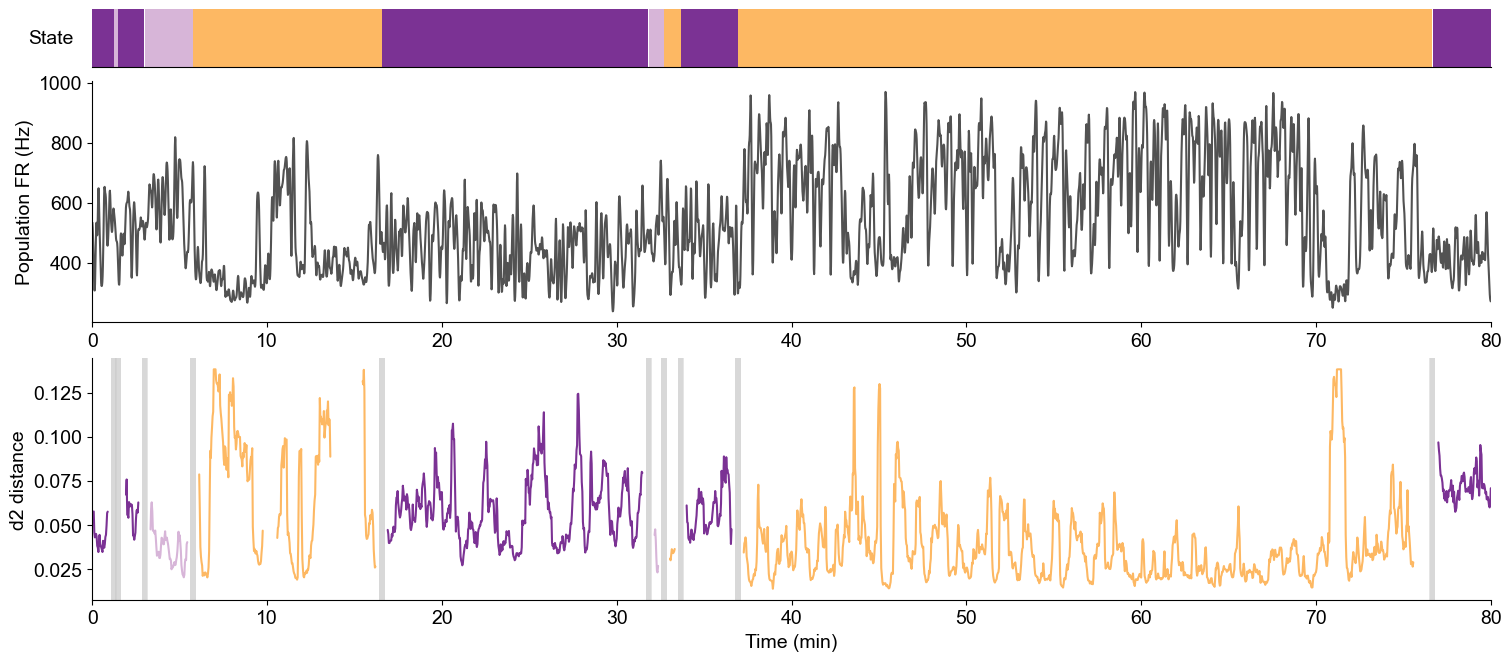

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match (works if those faces exist on your system)
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
def plot_mua_with_states_topbar(
    time_bins, firing_rate, nrem_epochs, awake_epochs, rem_epochs,
    *,
    bin_size=0.04,
    cap_pct=99.5, short_sec=0.5, long_sec=5.0,
    ds_sec=1.0, use_butter=False,
    start_time=5915.5, end_time=8915.5,
    # --- third subplot (D² timeline) ---
    d2_df=None,                # DataFrame with columns: center_s, d2 (and optional state)
    d2_cap_pct=99.5,
    d2_smooth_sec=0,
    d2_scatter_alpha=0.25,
    d2_color='k',
    d2_label='D²',
    # --- transition shading for D² ---
    shade_transitions=True,    # fill gray bands at each transition
    break_pad=1.0,             # seconds to treat as transition zone on each side (also used for gaps)
    shade_color='1',
    shade_alpha=0.35,
    break_make_gap=True,       # set D² to NaN in [edge ± break_pad] so lines visibly break
    save_path=None
):
    """
    Top: state bar; Middle: MUA; Bottom: D² timeline (linked by state).
    Shades transition zones in gray and (optionally) leaves small gaps in the D² trace there.
    """

    # segment
    mask = (time_bins >= start_time) & (time_bins <= end_time)
    t = np.asarray(time_bins)[mask]
    r = np.asarray(firing_rate)[mask]
    if t.size == 0:
        print("No data in specified time segment")
        return

    # state arrays as Nx2 arrays
    nrem_data  = (nrem_epochs.data  if hasattr(nrem_epochs, 'data')  else np.asarray(nrem_epochs)).reshape(-1,2)
    awake_data = (awake_epochs.data if hasattr(awake_epochs, 'data') else np.asarray(awake_epochs)).reshape(-1,2)
    rem_data   = (rem_epochs.data   if hasattr(rem_epochs, 'data')   else np.asarray(rem_epochs)).reshape(-1,2)

    # cap + smooth MUA
    cap_val = np.percentile(firing_rate, cap_pct)
    r_cap = np.clip(r, 0, cap_val)

    if use_butter:
        nyq = 0.5 / bin_size
        cutoff = 1.0 / max(long_sec, bin_size*2)   # Hz
        b, a = butter(2, cutoff/nyq, btype='low')
        long_sm  = filtfilt(b, a, r_cap)
    else:
        long_sm  = gaussian_filter1d(r_cap, sigma=max(long_sec/bin_size, 1))

    # downsample for display
    step = max(int(round(ds_sec / bin_size)), 1)
    nblk = (len(long_sm) // step)
    long_ds = long_sm[:nblk*step].reshape(nblk, step).mean(axis=1)
    t_ds    = t[:nblk*step].reshape(nlk:=nblk, step).mean(axis=1)  # noqa: F841 (keep nlk to avoid accidental typos)

    # layout
    have_d2 = d2_df is not None
    ratios = [0.12, 0.50, 0.50] if have_d2 else [0.12, 0.88]
    fig = plt.figure(figsize=(15, 6.5 if have_d2 else 5.0), constrained_layout=True)
    gs = fig.add_gridspec(nrows=3 if have_d2 else 2, ncols=1, height_ratios=ratios)
    ax_bar = fig.add_subplot(gs[0, 0])
    ax_mua = fig.add_subplot(gs[1, 0], sharex=ax_bar)
    ax_d2  = fig.add_subplot(gs[2, 0], sharex=ax_bar) if have_d2 else None

    # helpers
    def _clip_to_window(a, b):
        aa, bb = max(a, start_time), min(b, end_time)
        return (aa, bb) if bb > aa else None

    def draw_state_bar(intervals, color, label=None):
        drew = False
        if intervals is None or np.size(intervals) == 0:
            return
        for (a, b) in np.asarray(intervals).reshape(-1, 2):
            clip = _clip_to_window(a, b)
            if clip is None:
                continue
            aa, bb = clip
            ax_bar.axvspan(aa, bb, ymin=0, ymax=1, color=color, lw=0, label=(label if not drew else None))
            drew = True

    # top bar
    colors = {"Wake": "#fdb863", "NREM": "#7b3294", "REM": "#d7b5d8"}
    draw_state_bar(awake_data, colors["Wake"], "Wake")
    draw_state_bar(nrem_data,  colors["NREM"], "NREM")
    draw_state_bar(rem_data,   colors["REM"],  "REM")
    ax_bar.set_xticks([]); ax_bar.set_yticks([])
    ax_bar.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)
    ax_bar.set_ylabel("State", rotation=0, labelpad=30, va="center")
    ax_bar.set_xlim(start_time, end_time)
    for s in ["right", "top", "left"]:
        ax_bar.spines[s].set_visible(False)

    # middle MUA
    ax_mua.plot(t_ds, long_ds, lw=1.5, alpha=1, color="#525252", label=f"smoothed ~{long_sec:g}s (↓~{ds_sec:g}s)")
    ax_mua.set_ylabel("Population FR (Hz)")
    ax_mua.grid(False)
    for s in ("top", "right"):
        ax_mua.spines[s].set_visible(False)

    # bottom D²
    if have_d2:
        d2_filtered = d2_df[(d2_df["center_s"] >= start_time) & (d2_df["center_s"] <= end_time)].copy()
        d2_filtered = d2_filtered.rename(columns={"center_s": "t", "d2": "d2"}).loc[:, ["t", "d2"]].dropna()
        d2_filtered = d2_filtered.sort_values("t")

        t2 = d2_filtered["t"].to_numpy(float)
        y2 = d2_filtered["d2"].to_numpy(float)
        finite = np.isfinite(t2) & np.isfinite(y2)
        t2, y2 = t2[finite], y2[finite]

        if t2.size:
            y2c = y2.copy()
            if d2_cap_pct < 100:
                cap_val = np.nanpercentile(y2c, d2_cap_pct)
                y2c = np.clip(y2c, 0, cap_val)

            # per-point state (prefer d2_df column, else infer)
            def _in_any_interval(tt, intervals):
                tt = np.asarray(tt, float)
                iv = np.asarray(intervals, float).reshape(-1, 2)
                if tt.size == 0 or iv.size == 0:
                    return np.zeros_like(tt, dtype=bool)
                iv = iv[np.argsort(iv[:, 0])]
                starts, ends = iv[:, 0], iv[:, 1]
                n_started = np.searchsorted(starts, tt, side="right")
                n_ended   = np.searchsorted(ends,   tt, side="right")
                return (n_started - n_ended) > 0

            if "state" in d2_df.columns:
                s_raw = d2_df[(d2_df["center_s"] >= start_time) & (d2_df["center_s"] <= end_time)]["state"]\
                          .astype(str).str.upper().to_numpy()
                s2 = s_raw[finite]
            else:
                s2 = np.full(t2.shape, "UNKNOWN", dtype=object)
                if np.size(awake_data): s2[_in_any_interval(t2, awake_data)] = "WAKE"
                if np.size(nrem_data):  s2[_in_any_interval(t2, nrem_data)]  = "NREM"
                if np.size(rem_data):   s2[_in_any_interval(t2, rem_data)]   = "REM"

            # transition edges from state intervals (starts/ends)
            edges = []
            for iv in (awake_data, nrem_data, rem_data):
                if iv.size:
                    edges.append(iv[:, 0]); edges.append(iv[:, 1])
            edges = np.concatenate(edges) if edges else np.array([])
            edges = edges[(edges >= start_time) & (edges <= end_time)]
            edges = np.unique(edges)

            # 1) shade transition zones
            if shade_transitions and edges.size:
                for tt_edge in edges:
                    clip = _clip_to_window(tt_edge - break_pad, tt_edge + break_pad)
                    if clip is not None:
                        a, b = clip
                        ax_d2.axvspan(a, b, facecolor=shade_color, alpha=shade_alpha, lw=1, zorder=0)

            # 2) optionally create tiny gaps in the D² line around transitions
            y2c_plot = y2c.copy()
            if break_make_gap and edges.size:
                gap_mask = np.zeros_like(t2, dtype=bool)
                for tt_edge in edges:
                    gap_mask |= (t2 >= tt_edge - break_pad) & (t2 <= tt_edge + break_pad)
                y2c_plot[gap_mask] = np.nan  # NaNs force visible breaks

            # 3) draw state-colored segments (breaks also happen at NaNs)
            state_colors = {"WAKE": "#fdb863", "NREM": "#7b3294", "REM": "#d7b5d8", "REM4": "#d7b5d8"}
            dt2 = np.median(np.diff(t2)) if t2.size > 1 else 1.0
            gap_sec_for_state_change = 5 * dt2
            breaks = np.r_[True, (s2[1:] != s2[:-1]) | (np.diff(t2) > gap_sec_for_state_change)]
            starts = np.flatnonzero(breaks)
            ends   = np.r_[starts[1:], len(t2)]
            for a, b in zip(starts, ends):
                if b - a < 2:
                    continue
                col = state_colors.get(s2[a], "0.5")
                ax_d2.plot(t2[a:b], y2c_plot[a:b], lw=1.5, color=col, alpha=1, solid_capstyle="round")

            # raw scatter (dim)
            ax_d2.set_ylabel(d2_label)
            ax_d2.grid(False)
            for s in ("top", "right"):
                ax_d2.spines[s].set_visible(False)
        else:
            ax_d2.text(0.5, 0.5, "No D² in window", ha="center", va="center", transform=ax_d2.transAxes)
            ax_d2.set_ylabel(d2_label)

    # shared x formatting
    def _nice_step_minutes(span_min, max_ticks=8):
        for s in [0.5, 1, 2, 5, 10, 15, 30]:
            if span_min / s <= max_ticks:
                return s
        return 60

    span_min = (end_time - start_time) / 60.0
    step_min = _nice_step_minutes(span_min)
    base = step_min * 60
    tgt_ax = ax_d2 if have_d2 else ax_mua
    tgt_ax.xaxis.set_major_locator(MultipleLocator(base=base, offset=start_time))
    tgt_ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{(x - start_time)/60:.0f}" if step_min >= 1 else f"{(x - start_time)/60:.1f}")
    )
    tgt_ax.set_xlim(start_time, end_time)
    tgt_ax.set_xlabel("Time (min)")

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
save_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan"
save_path  = os.path.join(save_dir, f"{animal_name}_{day}_MUA_d2_example.svg")

plot_mua_with_states_topbar(
    time_bins, firing_rate,
    nrem_epochs, awake_epochs, rem_epochs,
    start_time=5200, end_time=10000,
    bin_size=0.04, cap_pct=99.5, long_sec=2.0, ds_sec=1.0,
    d2_df=ca1_complete_df, d2_label="d2 distance",
    shade_transitions=True,
    break_pad=10,        # width of the shaded gap on each side
    shade_color='0.8',
    shade_alpha=0.5,
    break_make_gap=True,
    save_path=save_path
)


     start     stop state     dur
0   5200.0   5273.0  NREM    73.0
1   5274.0   5287.0   REM    13.0
2   5288.0   5295.0  WAKE     7.0
3   5296.0   5379.0  NREM    83.0
4   5380.0   5546.0   REM   166.0
5   5547.0   5805.0  WAKE   258.0
6   5806.0   5814.0  NREM     8.0
7   5815.0   6038.0  WAKE   223.0
8   6039.0   6063.0  NREM    24.0
9   6064.0   6076.0  WAKE    12.0
10  6077.0   6107.0  NREM    30.0
11  6108.0   6193.0  WAKE    85.0
12  6194.0   7109.0  NREM   915.0
13  7110.0   7162.0   REM    52.0
14  7163.0   7219.0  WAKE    56.0
15  7220.0   7415.0  NREM   195.0
16  7416.0   9755.0  WAKE  2339.0
17  9756.0   9769.0  NREM    13.0
18  9770.0   9799.0  WAKE    29.0
19  9800.0  10000.0  NREM   200.0

Counts: {'NREM': 9, 'WAKE': 8, 'REM': 3}


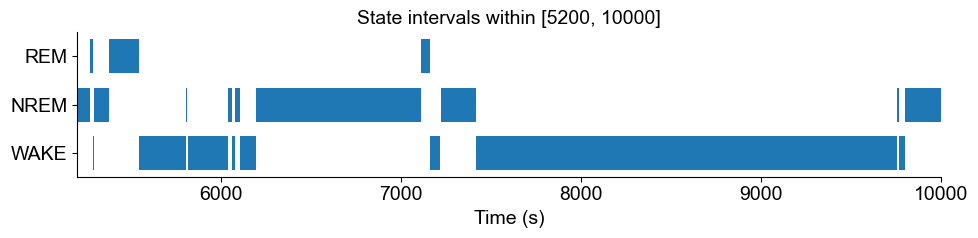

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

start_time = 5200
end_time   = 10000

def _clip_intervals(iv, t0, t1):
    """iv: (N,2) array; returns clipped intervals within [t0,t1]."""
    iv = np.asarray(iv, float)
    if iv.size == 0:
        return np.empty((0,2), float)
    a = np.maximum(iv[:, 0], t0)
    b = np.minimum(iv[:, 1], t1)
    out = np.column_stack([a, b])
    return out[out[:, 1] > out[:, 0]]

# --- 1) clip intervals ---
nrem_iv = _clip_intervals(nrem_epochs.data, start_time, end_time)
rem_iv  = _clip_intervals(rem_epochs.data,  start_time, end_time)
wake_iv = _clip_intervals(awake_epochs.data, start_time, end_time)

# --- 2) make a time-ordered table ---
rows = []
for state, iv in [("WAKE", wake_iv), ("NREM", nrem_iv), ("REM", rem_iv)]:
    for s, e in iv:
        rows.append((s, e, state))

df = pd.DataFrame(rows, columns=["start", "stop", "state"]).sort_values("start").reset_index(drop=True)
df["dur"] = df["stop"] - df["start"]

print(df.head(20))
print("\nCounts:", df["state"].value_counts().to_dict())

# NOTE: if your states overlap in time (shouldn't, but sometimes happens),
# you'll see overlapping bars in the plot.

# --- 3) plot as rows (one row per state) ---
state_order = ["WAKE", "NREM", "REM"]
ypos = {st:i for i, st in enumerate(state_order)}

fig, ax = plt.subplots(figsize=(10, 2.6))

for st in state_order:
    sub = df[df["state"] == st]
    xranges = [(r.start, r.stop - r.start) for r in sub.itertuples(index=False)]
    if xranges:
        ax.broken_barh(xranges, (ypos[st] - 0.35, 0.7))  # default color cycle

ax.set_xlim(start_time, end_time)
ax.set_yticks([ypos[s] for s in state_order])
ax.set_yticklabels(state_order)
ax.set_xlabel("Time (s)")
ax.set_title(f"State intervals within [{start_time}, {end_time}]")

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


MUA across state

In [28]:
# import numpy as np
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt
# import nelpy as nel
# from scipy import stats

# # --- helpers ---
# def erode_epocharray(ep, guard_s=0.0):
#     if guard_s <= 0: return ep
#     d = ep.data.copy()
#     d[:,0] += guard_s; d[:,1] -= guard_s
#     d = d[d[:,1] > d[:,0]]
#     return nel.EpochArray(d)

# def mask_bins(time_bins, epochs):
#     arr = epochs.data if hasattr(epochs, 'data') else np.asarray(epochs)
#     m = np.zeros_like(time_bins, dtype=bool)
#     for s,e in arr:
#         m |= (time_bins >= s) & (time_bins < e)
#     return m

# def window_means(x, bin_size=0.04, window_sec=0.5, overlap=0.0):
#     """
#     Non-overlapping by default. overlap in [0, 1): e.g., 0.5 = 50% overlap.
#     Returns per-window mean firing rates and the actual window_sec used.
#     """
#     bins_per_win = int(max(1, round(window_sec/bin_size)))   # nearest integer
#     window_used  = bins_per_win * bin_size
#     if overlap <= 0:
#         n_full = (len(x) // bins_per_win) * bins_per_win
#         if n_full == 0: 
#             return np.array([]), window_used
#         xx = x[:n_full].reshape(-1, bins_per_win)
#         return xx.mean(axis=1), window_used
#     else:
#         hop = max(1, int(round(bins_per_win * (1 - overlap))))
#         idx = np.arange(0, len(x) - bins_per_win + 1, hop, dtype=int)
#         if idx.size == 0: 
#             return np.array([]), window_used
#         means = [x[i:i+bins_per_win].mean() for i in idx]
#         return np.asarray(means), window_used

# # --- params ---
# BIN_SIZE   = 0.04
# WINDOW_SEC = 0.50       # request ~500 ms
# OVERLAP    = 0.0        # set to 0.5 if you want 50% overlap
# GUARD_S    = 0.0        # e.g., 5.0 to erode state boundaries

# # (optional) erode to avoid boundary contamination
# nrem_use  = erode_epocharray(nrem_epochs,  GUARD_S)
# wake_use  = erode_epocharray(awake_epochs, GUARD_S)
# rem_use   = erode_epocharray(rem_epochs,   GUARD_S)

# # collect windowed means per state (time-weighted because we use all bins)
# state_series = {}
# used_window_sec = None
# for name, ep in [('NREM', nrem_use), ('Wake', wake_use), ('REM', rem_use)]:
#     m = mask_bins(time_bins, ep)
#     x = firing_rate[m]  # Hz
#     wm, w_used = window_means(x, bin_size=BIN_SIZE, window_sec=WINDOW_SEC, overlap=OVERLAP)
#     used_window_sec = w_used if used_window_sec is None else used_window_sec
#     state_series[name] = wm

# print(f"Window length used: {used_window_sec*1000:.0f} ms "
#       f"({int(round(used_window_sec/BIN_SIZE))} bins of {BIN_SIZE*1000:.0f} ms).")

# # build dataframe
# df = pd.concat(
#     [pd.DataFrame({'state': k, 'win_mean_rate': v}) for k,v in state_series.items()],
#     ignore_index=True
# )

# # quick summary
# print(df.groupby('state')['win_mean_rate'].describe().round(3))

# # --- plot ---
# plt.figure(figsize=(8,5))
# sns.boxplot(data=df, x='state', y='win_mean_rate', showfliers=False,
#             order=['NREM','Wake','REM'])
# plt.title(f'Windowed MUA Firing Rate by State\n({used_window_sec*1000:.0f} ms windows)')
# plt.xlabel('State'); plt.ylabel('Mean firing rate per window (Hz)')
# plt.grid(True, axis='y', alpha=0.3)
# plt.tight_layout(); plt.show()

# # --- stats (non-parametric, windows are many & not independent) ---
# # Kruskal–Wallis across states:
# groups = [state_series[s] for s in ['NREM','Wake','REM'] if len(state_series[s])>1]
# names  = [s for s in ['NREM','Wake','REM'] if len(state_series[s])>1]
# if len(groups) >= 2:
#     H, p_kw = stats.kruskal(*groups)
#     print(f"Kruskal–Wallis across states: H={H:.3f}, p={p_kw:.3e}")
#     # pairwise Mann–Whitney with Bonferroni correction
#     from itertools import combinations
#     for a,b in combinations(names,2):
#         U, p = stats.mannwhitneyu(state_series[a], state_series[b], alternative='two-sided')
#         print(f"{a} vs {b}: U={U:.0f}, p={min(1.0, p*3):.3e} (Bonferroni)")
# import os, pickle, numpy as np, pandas as pd
# from datetime import datetime



# n_cell_val =n_cell

# # --- what we’re saving ---
# data_to_save = {
#     "windowed_rate_df": df,        # your DataFrame built above
#     "n_cell": n_cell_val,
#     "params": {
#         "bin_size": BIN_SIZE,
#         "window_sec_used": used_window_sec,
#         "overlap": OVERLAP,
#         "guard_s": GUARD_S,
#     },
#     "meta": {
#         "animal_name": animal_name,
#         "day": day,
#         "created": datetime.now().isoformat(timespec="seconds"),
#         "note": "Windowed MUA firing rate per state (per-window means) + n_cell",
#     },
# }

# # --- save ---
# save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\MUA"
# os.makedirs(save_dir, exist_ok=True)
# fname = f"{animal_name}_{day}_crossstate_MUAfiring.pkl"
# fpath = os.path.join(save_dir, fname)

# with open(fpath, "wb") as f:
#     pickle.dump(data_to_save, f, protocol=pickle.HIGHEST_PROTOCOL)

# # quick verify
# with open(fpath, "rb") as f:
#     chk = pickle.load(f)

# print(f"✅ Saved: {fpath}")
# print(f"   keys: {list(chk.keys())}")
# print(f"   windowed_rate_df shape: {chk['windowed_rate_df'].shape}")
# print(f"   n_cell: {chk['n_cell']}")


MUA for ripple rate and barrage rate

Compute d2 across states

In [29]:
# import os, re, numpy as np, pandas as pd
# import glob  # <-- add this
# def _to_1d_array(x):
#     """
#     Robustly coerce MATLAB-loaded field to a 1D numpy array.
#     - Scalars -> 1-length array
#     - Lists/tuples/ndarrays -> flattened 1D
#     - None / missing -> empty array
#     """
#     if x is None:
#         return np.array([], dtype=float)
#     arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
#     if arr.ndim == 0:
#         # scalar or unsized object
#         return np.atleast_1d(arr).astype(float, copy=False)
#     # flatten and try float cast (ignore non-numeric gracefully)
#     try:
#         return np.asarray(arr).ravel().astype(float, copy=False)
#     except (ValueError, TypeError):
#         # fallback: best-effort, convert elementwise
#         return np.array([float(v) for v in np.ravel(arr)], dtype=float)

# def _to_state_str(s):
#     # MATLAB char arrays sometimes come in as numpy arrays
#     try:
#         if isinstance(s, (bytes, bytearray)):
#             return s.decode('utf-8', 'ignore')
#         if isinstance(s, str):
#             return s
#         # arrays or weird containers -> join characters
#         arr = np.asarray(s)
#         if arr.ndim == 0:
#             return str(arr.item())
#         # e.g., array of characters
#         return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
#     except Exception:
#         return str(s)

# def load_d2_timeline_complete(basepath, region):
#     """Complete version that loads ALL sleep state data."""
#     region = region.upper()
#     search_dir = os.path.join(basepath, "complex_system")
#     pats = [f"*_{region}_D2_time_resolved*.mat", f"*_{region}_D2_time*.mat"]

#     files = []
#     for pat in pats:
#         files.extend(glob.glob(os.path.join(search_dir, pat)))
#     if not files:
#         raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

#     mat_path = max(files, key=os.path.getmtime)
#     print(f"Loading: {os.path.basename(mat_path)}")

#     mat = _load_mat_any(mat_path)
#     results = mat['results']
#     params = mat.get('params', {})

#     # Make results iterable no matter if it's a list, ndarray, or dict
#     if isinstance(results, dict):
#         iter_results = list(results.values())
#     else:
#         # ensure object array -> list of items
#         iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

#     print(f"📊 Found {len(iter_results)} result items (sleep states)")
#     print(f"📊 Parameters: {params}")

#     # Try to infer animal/day from filename if available
#     fname = os.path.basename(mat_path)
#     animal_name = None
#     day = None
#     m_day = re.search(r'day(\d+)', fname, flags=re.I)
#     if m_day:
#         day = int(m_day.group(1))
#     # very common pattern: <animal>_dayXX_<REGION>_...
#     m_animal = re.match(r'([^_]+)_day\d+_', fname)
#     if m_animal:
#         animal_name = m_animal.group(1)

#     all_centers, all_d2, all_states = [], [], []

#     for i, result_item in enumerate(iter_results):
#         # Access as dict-like regardless of MATLAB struct nuances
#         state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
#                 _to_state_str(result_item['state']) if isinstance(result_item, dict) or hasattr(result_item, '__getitem__') else 'UNKNOWN'

#         centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
#                       (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
#         d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
#                  (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])

#         centers = _to_1d_array(centers_raw)
#         d2_values = _to_1d_array(d2_raw)

#         n_pts = centers.size
#         print(f"   State {i}: {state} - {n_pts} data points")

#         if n_pts == 0:
#             print(f"     ⚠️ Empty state - no data points")
#             continue

#         # Length sanity check (some exports store misaligned shapes)
#         if d2_values.size != n_pts:
#             nmin = min(n_pts, d2_values.size)
#             print(f"     ⚠️ Length mismatch center({n_pts}) vs d2({d2_values.size}); truncating to {nmin}")
#             centers = centers[:nmin]
#             d2_values = d2_values[:nmin]
#             n_pts = nmin

#         # Safe ranges (all-NaN arrays would throw warnings)
#         try:
#             tmin, tmax = float(np.nanmin(centers)), float(np.nanmax(centers))
#             print(f"     Time range: {tmin:g} to {tmax:g}")
#         except ValueError:
#             print("     Time range: (all NaN)")

#         try:
#             dmin, dmax = float(np.nanmin(d2_values)), float(np.nanmax(d2_values))
#             print(f"     D2 range: {dmin:.4f} to {dmax:.4f}")
#         except ValueError:
#             print("     D2 range: (all NaN)")

#         all_centers.append(centers)
#         all_d2.append(d2_values)
#         all_states.append(np.array([state]*n_pts, dtype=object))

#     # Check if we have any data at all
#     if len(all_centers) == 0:
#         raise ValueError("No data found in any sleep state - all states are empty")

#     # Concatenate
#     all_centers = np.concatenate(all_centers)
#     all_d2      = np.concatenate(all_d2)
#     all_states  = np.concatenate(all_states)

#     # Create complete DataFrame
#     df = pd.DataFrame({
#         'center_s': all_centers.astype(float, copy=False),
#         'd2': all_d2.astype(float, copy=False),
#         'state': all_states.astype(str)
#     }).sort_values('center_s').reset_index(drop=True)

#     print(f"\n✅ Complete timeline created:")
#     print(f"📊 Total data points: {len(df)}")
#     print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
#     print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
#     print(f"📊 State distribution:")
#     print(df['state'].value_counts())

#     # Empty-state tracker (using safe size)
#     empty_states = []
#     for ri in iter_results:
#         st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
#              _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
#         csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
#               np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
#         if csz == 0:
#             empty_states.append(st)

#     meta = {
#         "animal_name": animal_name,
#         "day": day,
#         "region": region,
#         "path": mat_path,
#         "params": params,
#         "columns": list(df.columns),
#         "shape": df.shape,
#         "n_states": len(iter_results),
#         "empty_states": empty_states
#     }

#     return df, meta


# # Test the complete loading function
# try:
#     ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
#     # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
# except Exception as e:
#     print(f"❌ Failed: {e}")
#     import traceback
#     traceback.print_exc()

# print("\n" + "="*60)

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import butter, filtfilt
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match (works if those faces exist on your system)
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
def plot_mua_with_states_topbar(
    time_bins, firing_rate, nrem_epochs, awake_epochs, rem_epochs,
    *,
    bin_size=0.04,
    cap_pct=99.5, short_sec=0.5, long_sec=5.0,
    ds_sec=1.0, use_butter=False,
    start_time=5915.5, end_time=8915.5,
    # --- third subplot (D² timeline) ---
    d2_df=None,                # DataFrame with columns: center_s, d2 (and optional state)
    d2_cap_pct=99.5,
    d2_smooth_sec=0,
    d2_scatter_alpha=0.25,
    d2_color='k',
    d2_label='D²',
    # --- transition shading for D² ---
    shade_transitions=True,    # fill gray bands at each transition
    break_pad=1.0,             # seconds to treat as transition zone on each side (also used for gaps)
    shade_color='1',
    shade_alpha=0.35,
    break_make_gap=True,       # set D² to NaN in [edge ± break_pad] so lines visibly break
    save_path=None
):
    """
    Top: state bar; Middle: MUA; Bottom: D² timeline (linked by state).
    Shades transition zones in gray and (optionally) leaves small gaps in the D² trace there.
    """

    # segment
    mask = (time_bins >= start_time) & (time_bins <= end_time)
    t = np.asarray(time_bins)[mask]
    r = np.asarray(firing_rate)[mask]
    if t.size == 0:
        print("No data in specified time segment")
        return

    # state arrays as Nx2 arrays
    nrem_data  = (nrem_epochs.data  if hasattr(nrem_epochs, 'data')  else np.asarray(nrem_epochs)).reshape(-1,2)
    awake_data = (awake_epochs.data if hasattr(awake_epochs, 'data') else np.asarray(awake_epochs)).reshape(-1,2)
    rem_data   = (rem_epochs.data   if hasattr(rem_epochs, 'data')   else np.asarray(rem_epochs)).reshape(-1,2)

    # cap + smooth MUA
    cap_val = np.percentile(firing_rate, cap_pct)
    r_cap = np.clip(r, 0, cap_val)

    if use_butter:
        nyq = 0.5 / bin_size
        cutoff = 1.0 / max(long_sec, bin_size*2)   # Hz
        b, a = butter(2, cutoff/nyq, btype='low')
        long_sm  = filtfilt(b, a, r_cap)
    else:
        long_sm  = gaussian_filter1d(r_cap, sigma=max(long_sec/bin_size, 1))

    # downsample for display
    step = max(int(round(ds_sec / bin_size)), 1)
    nblk = (len(long_sm) // step)
    long_ds = long_sm[:nblk*step].reshape(nblk, step).mean(axis=1)
    t_ds    = t[:nblk*step].reshape(nlk:=nblk, step).mean(axis=1)  # noqa: F841 (keep nlk to avoid accidental typos)

    # layout
    have_d2 = d2_df is not None
    ratios = [0.12, 0.50, 0.50] if have_d2 else [0.12, 0.88]
    fig = plt.figure(figsize=(15, 6.5 if have_d2 else 5.0), constrained_layout=True)
    gs = fig.add_gridspec(nrows=3 if have_d2 else 2, ncols=1, height_ratios=ratios)
    ax_bar = fig.add_subplot(gs[0, 0])
    ax_mua = fig.add_subplot(gs[1, 0], sharex=ax_bar)
    ax_d2  = fig.add_subplot(gs[2, 0], sharex=ax_bar) if have_d2 else None

    # helpers
    def _clip_to_window(a, b):
        aa, bb = max(a, start_time), min(b, end_time)
        return (aa, bb) if bb > aa else None

    def draw_state_bar(intervals, color, label=None):
        drew = False
        if intervals is None or np.size(intervals) == 0:
            return
        for (a, b) in np.asarray(intervals).reshape(-1, 2):
            clip = _clip_to_window(a, b)
            if clip is None:
                continue
            aa, bb = clip
            ax_bar.axvspan(aa, bb, ymin=0, ymax=1, color=color, lw=0, label=(label if not drew else None))
            drew = True

    # top bar
    colors = {"Wake": "#fdb863", "NREM": "#7b3294", "REM": "#d7b5d8"}
    draw_state_bar(awake_data, colors["Wake"], "Wake")
    draw_state_bar(nrem_data,  colors["NREM"], "NREM")
    draw_state_bar(rem_data,   colors["REM"],  "REM")
    ax_bar.set_xticks([]); ax_bar.set_yticks([])
    ax_bar.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)
    ax_bar.set_ylabel("State", rotation=0, labelpad=30, va="center")
    ax_bar.set_xlim(start_time, end_time)
    for s in ["right", "top", "left"]:
        ax_bar.spines[s].set_visible(False)

    # middle MUA
    ax_mua.plot(t_ds, long_ds, lw=1.5, alpha=1, color="#525252", label=f"smoothed ~{long_sec:g}s (↓~{ds_sec:g}s)")
    ax_mua.set_ylabel("Population FR (Hz)")
    ax_mua.grid(False)
    for s in ("top", "right"):
        ax_mua.spines[s].set_visible(False)

    # bottom D²
    if have_d2:
        d2_filtered = d2_df[(d2_df["center_s"] >= start_time) & (d2_df["center_s"] <= end_time)].copy()
        d2_filtered = d2_filtered.rename(columns={"center_s": "t", "d2": "d2"}).loc[:, ["t", "d2"]].dropna()
        d2_filtered = d2_filtered.sort_values("t")

        t2 = d2_filtered["t"].to_numpy(float)
        y2 = d2_filtered["d2"].to_numpy(float)
        finite = np.isfinite(t2) & np.isfinite(y2)
        t2, y2 = t2[finite], y2[finite]

        if t2.size:
            y2c = y2.copy()
            if d2_cap_pct < 100:
                cap_val = np.nanpercentile(y2c, d2_cap_pct)
                y2c = np.clip(y2c, 0, cap_val)

            # per-point state (prefer d2_df column, else infer)
            def _in_any_interval(tt, intervals):
                tt = np.asarray(tt, float)
                iv = np.asarray(intervals, float).reshape(-1, 2)
                if tt.size == 0 or iv.size == 0:
                    return np.zeros_like(tt, dtype=bool)
                iv = iv[np.argsort(iv[:, 0])]
                starts, ends = iv[:, 0], iv[:, 1]
                n_started = np.searchsorted(starts, tt, side="right")
                n_ended   = np.searchsorted(ends,   tt, side="right")
                return (n_started - n_ended) > 0

            if "state" in d2_df.columns:
                s_raw = d2_df[(d2_df["center_s"] >= start_time) & (d2_df["center_s"] <= end_time)]["state"]\
                          .astype(str).str.upper().to_numpy()
                s2 = s_raw[finite]
            else:
                s2 = np.full(t2.shape, "UNKNOWN", dtype=object)
                if np.size(awake_data): s2[_in_any_interval(t2, awake_data)] = "WAKE"
                if np.size(nrem_data):  s2[_in_any_interval(t2, nrem_data)]  = "NREM"
                if np.size(rem_data):   s2[_in_any_interval(t2, rem_data)]   = "REM"

            # transition edges from state intervals (starts/ends)
            edges = []
            for iv in (awake_data, nrem_data, rem_data):
                if iv.size:
                    edges.append(iv[:, 0]); edges.append(iv[:, 1])
            edges = np.concatenate(edges) if edges else np.array([])
            edges = edges[(edges >= start_time) & (edges <= end_time)]
            edges = np.unique(edges)

            # 1) shade transition zones
            if shade_transitions and edges.size:
                for tt_edge in edges:
                    clip = _clip_to_window(tt_edge - break_pad, tt_edge + break_pad)
                    if clip is not None:
                        a, b = clip
                        ax_d2.axvspan(a, b, facecolor=shade_color, alpha=shade_alpha, lw=1, zorder=0)

            # 2) optionally create tiny gaps in the D² line around transitions
            y2c_plot = y2c.copy()
            if break_make_gap and edges.size:
                gap_mask = np.zeros_like(t2, dtype=bool)
                for tt_edge in edges:
                    gap_mask |= (t2 >= tt_edge - break_pad) & (t2 <= tt_edge + break_pad)
                y2c_plot[gap_mask] = np.nan  # NaNs force visible breaks

            # 3) draw state-colored segments (breaks also happen at NaNs)
            state_colors = {"WAKE": "#fdb863", "NREM": "#7b3294", "REM": "#d7b5d8", "REM4": "#d7b5d8"}
            dt2 = np.median(np.diff(t2)) if t2.size > 1 else 1.0
            gap_sec_for_state_change = 5 * dt2
            breaks = np.r_[True, (s2[1:] != s2[:-1]) | (np.diff(t2) > gap_sec_for_state_change)]
            starts = np.flatnonzero(breaks)
            ends   = np.r_[starts[1:], len(t2)]
            for a, b in zip(starts, ends):
                if b - a < 2:
                    continue
                col = state_colors.get(s2[a], "0.5")
                ax_d2.plot(t2[a:b], y2c_plot[a:b], lw=1.5, color=col, alpha=1, solid_capstyle="round")

            # raw scatter (dim)
            ax_d2.set_ylabel(d2_label)
            ax_d2.grid(False)
            for s in ("top", "right"):
                ax_d2.spines[s].set_visible(False)
        else:
            ax_d2.text(0.5, 0.5, "No D² in window", ha="center", va="center", transform=ax_d2.transAxes)
            ax_d2.set_ylabel(d2_label)

    # shared x formatting
    def _nice_step_minutes(span_min, max_ticks=8):
        for s in [0.5, 1, 2, 5, 10, 15, 30]:
            if span_min / s <= max_ticks:
                return s
        return 60

    span_min = (end_time - start_time) / 60.0
    step_min = _nice_step_minutes(span_min)
    base = step_min * 60
    tgt_ax = ax_d2 if have_d2 else ax_mua
    tgt_ax.xaxis.set_major_locator(MultipleLocator(base=base, offset=start_time))
    tgt_ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{(x - start_time)/60:.0f}" if step_min >= 1 else f"{(x - start_time)/60:.1f}")
    )
    tgt_ax.set_xlim(start_time, end_time)
    tgt_ax.set_xlabel("Time (min)")

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
save_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\figure_plan"
save_path  = os.path.join(save_dir, f"{animal_name}_{day}_MUA_d2_example.svg")

plot_mua_with_states_topbar(
    time_bins, firing_rate,
    nrem_epochs, awake_epochs, rem_epochs,
    start_time=5200, end_time=10000,
    bin_size=0.04, cap_pct=99.5, long_sec=2.0, ds_sec=1.0,
    d2_df=ca1_complete_df, d2_label="d2 distance",
    shade_transitions=True,
    break_pad=10,        # width of the shaded gap on each side
    shade_color='0.8',
    shade_alpha=0.5,
    break_make_gap=True,
    save_path=save_path
)


In [31]:
# import numpy as np
# import pandas as pd

# def filter_ca1_by_epochs(ca1_df, epoch_df, index_list, *,
#                          time_col='center_s',
#                          start_col='startTime', stop_col='stopTime',
#                          name_col='name', env_col='environment',
#                          guard_s=0.0):
#     """
#     Keep rows in ca1_df whose `time_col` falls inside any selected epochs.
#     `index_list` can be a list of integer row positions in epoch_df (iloc)
#     OR a list of epoch names matching epoch_df[name_col].

#     Returns a new DataFrame with added columns:
#       ['epoch_row', 'epoch_order', 'epoch_name', 'environment'].
#     """
#     if len(index_list) == 0:
#         return ca1_df.iloc[0:0].copy()

#     # allow selecting by integer row positions or by names
#     if np.issubdtype(np.array(index_list).dtype, np.integer):
#         sel = epoch_df.iloc[index_list].copy()
#     else:
#         sel = epoch_df[epoch_df[name_col].isin(index_list)].copy()

#     out_list = []
#     for order, (row_idx, row) in enumerate(sel.iterrows()):
#         s = float(row[start_col]) + guard_s
#         e = float(row[stop_col]) - guard_s
#         if s >= e:
#             continue
#         m = (ca1_df[time_col] >= s) & (ca1_df[time_col] < e)
#         part = ca1_df.loc[m].copy()
#         if part.empty:
#             continue
#         part['epoch_row']   = row_idx               # original row index in epoch_df
#         part['epoch_order'] = order                 # order in your index_list
#         part['epoch_name']  = row.get(name_col, '')
#         part['environment'] = row.get(env_col,  '')
#         out_list.append(part)

#     return pd.concat(out_list, ignore_index=True) if out_list else ca1_df.iloc[0:0].copy()
# # which epochs you want to keep (by row positions in epoch_df)
# index_list = [0, 1,2,3,4]    # or: ["presleep_230429_100556", "midsleep_230429_125937"]

# ca1_complete_df = filter_ca1_by_epochs(
#     ca1_complete_df, epoch_df, index_list,
#     time_col='center_s', start_col='startTime', stop_col='stopTime',
#     name_col='name', env_col='environment',
#     guard_s=0.0   # e.g., set to 2.0 to erode 2 s from each edge
# )

d2

In [32]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# def plot_d2_box_by_state_theta(
#     df,
#     theta_intervals,                  # e.g., theta_epochs.data (N x 2, seconds)
#     *,
#     time_col="center_s",
#     value_col="d2",
#     state_col="state",
#     region_name=None,
#     prefer_rem_label="REM4",          # if present use REM4, else falls back to REM
#     ax=None,
#     show=True,
#     return_data=False
# ):
#     """
#     Split WAKE into theta vs non-theta by intervals, then boxplot:
#     [Wake θ, Wake non-θ, NREM, REM/REM4].

#     Returns:
#       If return_data=True: (box_df, meta) where box_df has columns ['d2','group'].
#     """
#     def in_any_interval(t, intervals):
#         t = np.asarray(t, float)
#         iv = np.asarray(intervals, float)
#         if t.size == 0 or iv.size == 0:
#             return np.zeros(t.shape, dtype=bool)
#         iv = iv[np.argsort(iv[:, 0])]
#         starts, ends = iv[:, 0], iv[:, 1]
#         n_started = np.searchsorted(starts, t, side="right")
#         n_ended   = np.searchsorted(ends,   t, side="right")
#         return (n_started - n_ended) > 0

#     # Normalize/rename columns
#     _df = df[[time_col, value_col, state_col]].copy()
#     _df.columns = ["center_s", "d2", "state"]
#     _df["state_u"] = _df["state"].astype(str).str.upper()

#     # Masks
#     wake_mask = _df["state_u"].eq("WAKE")
#     nrem_mask = _df["state_u"].eq("NREM")
#     rem_lbl   = prefer_rem_label if _df["state_u"].eq(prefer_rem_label).any() else "REM"
#     rem_mask  = _df["state_u"].eq(rem_lbl)

#     # Split WAKE by theta intervals
#     wake_times     = _df.loc[wake_mask, "center_s"].to_numpy(float)
#     wake_in_theta  = in_any_interval(wake_times, theta_intervals)

#     # Collect arrays
#     d2_wake_theta    = _df.loc[wake_mask].loc[wake_in_theta,  "d2"].to_numpy(float)
#     d2_wake_nontheta = _df.loc[wake_mask].loc[~wake_in_theta, "d2"].to_numpy(float)
#     d2_nrem          = _df.loc[nrem_mask, "d2"].to_numpy(float)
#     d2_rem           = _df.loc[rem_mask,  "d2"].to_numpy(float)

#     # Tidy table for reuse/saving
#     box_df = pd.DataFrame({
#         "d2": np.concatenate([
#             d2_wake_theta, d2_wake_nontheta, d2_nrem, d2_rem
#         ]) if (d2_wake_theta.size + d2_wake_nontheta.size + d2_nrem.size + d2_rem.size) > 0 else np.array([]),
#         "group": (
#             ["Wake θ"]     * len(d2_wake_theta) +
#             ["Wake non-θ"] * len(d2_wake_nontheta) +
#             ["NREM"]       * len(d2_nrem) +
#             [rem_lbl]      * len(d2_rem)
#         )
#     })

#     # Prepare data for plotting (drop empty groups)
#     groups = ["Wake θ", "Wake non-θ", "NREM", rem_lbl]
#     data   = [box_df.loc[box_df.group.eq(g), "d2"].to_numpy() for g in groups]
#     labels, data_nonempty = [], []
#     for g, arr in zip(groups, data):
#         if arr.size:
#             labels.append(f"{g}\n(n={arr.size})")
#             data_nonempty.append(arr)

#     # Plot
#     if ax is None:
#         fig, ax = plt.subplots(figsize=(7.5, 4.5))
#     ax.boxplot(data_nonempty, labels=labels, showmeans=True, notch=False)
#     ax.set_ylabel("D²")
#     title = f"{region_name} D²: Wake θ vs non-θ, NREM, {rem_lbl}" if region_name else f"D² by state (REM: {rem_lbl})"
#     ax.set_title(title)
#     plt.tight_layout()
#     if show:
#         plt.show()

#     if return_data:
#         meta = {
#             "counts": {g: int(arr.size) for g, arr in zip(groups, data)},
#             "rem_label": rem_lbl
#         }
#         return box_df, meta
# # CA1
# box_df_ca1, meta_ca1 = plot_d2_box_by_state_theta(
#     ca1_complete_df,
#     theta_epochs.data,
#     region_name="CA1",
#     return_data=True
# )

# # PFC
# box_df_pfc, meta_pfc = plot_d2_box_by_state_theta(
#     pfc_complete_df,
#     theta_epochs.data,
#     region_name="PFC",
#     return_data=True
# )

d2 vs MUA

In [33]:
# import numpy as np
# import pandas as pd
# from scipy import stats
# import matplotlib.pyplot as plt
# import pickle
# WIN_SEC = 30.0
# HOP_SEC = 2.0
# HALFWIN = WIN_SEC/2

# # ---------- interval helpers ----------
# def erode(iv, margin):
#     iv = np.asarray(iv, float)
#     if iv.size == 0: return iv.reshape(0,2)
#     out = iv.copy(); out[:,0]+=margin; out[:,1]-=margin
#     return out[out[:,1] > out[:,0]]

# def dilate(iv, margin):
#     iv = np.asarray(iv, float)
#     if iv.size == 0: return iv.reshape(0,2)
#     out = iv.copy(); out[:,0]-=margin; out[:,1]+=margin
#     return out

# def in_any_interval(t, iv):
#     t = np.asarray(t, float)
#     iv = np.asarray(iv, float)
#     if t.size == 0 or iv.size == 0: return np.zeros(t.shape, bool)
#     iv = iv[np.argsort(iv[:,0])]
#     s, e = iv[:,0], iv[:,1]
#     return (np.searchsorted(s, t, 'right') - np.searchsorted(e, t, 'right')) > 0

# def mask_full_window_inside_state(df, state_name, halfwin=HALFWIN,
#                                   time_col="center_s", state_col="state"):
#     d = df.sort_values(time_col).copy()
#     st = d[state_col].astype(str).str.upper().values
#     t  = d[time_col].to_numpy(float)
#     run_start = np.r_[0, np.where(st[1:] != st[:-1])[0] + 1]
#     run_end   = np.r_[run_start[1:], len(d)]
#     keep = np.zeros(len(d), bool)
#     target = state_name.upper()
#     for s, e in zip(run_start, run_end):
#         if st[s] != target: 
#             continue
#         t0, t1 = t[s], t[e-1]
#         keep[s:e] = (t[s:e] >= t0 + halfwin) & (t[s:e] <= t1 - halfwin)
#     return keep

# # ---------- MUA 30 s centered moving average on 0.04 s bins ----------
# def moving_mean_centered(time_bins, firing_rate, win_sec=WIN_SEC):
#     time_bins = np.asarray(time_bins, float)
#     fr = np.asarray(firing_rate, float)
#     dt = float(np.median(np.diff(time_bins)))
#     L = int(round(win_sec / dt))           # kernel length in samples
#     if L % 2 == 0: L += 1                  # use odd length for perfect centering
#     k = np.ones(L, dtype=float)
#     # handle NaNs/missing bins robustly
#     x = fr.copy()
#     w = np.isfinite(x).astype(float)
#     x[~np.isfinite(x)] = 0.0
#     num = np.convolve(x, k, mode="same")
#     den = np.convolve(w, k, mode="same")
#     mavg = np.where(den > 0, num/den, np.nan)
#     valid = den >= L                        # full 30 s coverage only
#     return mavg, valid, dt

# # ---------- sample MUA mean at D² times ----------
# def sample_at_times(source_t, source_y, target_t):
#     source_t = np.asarray(source_t, float)
#     target_t = np.asarray(target_t, float)
#     idx = np.searchsorted(source_t, target_t)
#     idx = np.clip(idx, 1, len(source_t)-1)
#     left = idx-1
#     right = idx
#     # nearest neighbor to avoid smoothing
#     nearer_left = np.abs(source_t[left] - target_t) <= np.abs(source_t[right] - target_t)
#     nn_idx = np.where(nearer_left, left, right)
#     return source_y[nn_idx]

# # ---------- main: correlate per group ----------
# def correlate_d2_mua_by_state_theta(
#     ca_df,                       # has ['center_s','d2','state'] at 2 s steps
#     time_bins, firing_rate,      # MUA at ~0.04 s bins
#     theta_epochs,                # nel.EpochArray or (N,2) seconds
#     *, prefer_rem_label="REM4",   # fall back to REM if REM4 not present
#     make_scatter=False
# ):
#     df = ca_df[["center_s","d2","state"]].copy()
#     df["state_u"] = df["state"].astype(str).str.upper()
#     rem_lbl = prefer_rem_label if (df["state_u"]==prefer_rem_label).any() else "REM"

#     # 1) MUA 30 s moving average; sample at D² times
#     mua30, mua_valid, dt = moving_mean_centered(time_bins, firing_rate, win_sec=WIN_SEC)
#     mua_at_d2 = sample_at_times(time_bins, mua30, df["center_s"].to_numpy(float))
#     valid_at_d2 = sample_at_times(time_bins, mua_valid.astype(float), df["center_s"].to_numpy(float)).astype(bool)

#     # 2) full-window guards by state
#     keep_wake = mask_full_window_inside_state(df, "WAKE")
#     keep_nrem = mask_full_window_inside_state(df, "NREM")
#     keep_rem  = mask_full_window_inside_state(df, rem_lbl)

#     # 3) Wake θ vs non-θ (θ windows must fully contain the 30 s box; non-θ excludes any touch)
#     theta_iv  = theta_epochs.data if hasattr(theta_epochs, "data") else np.asarray(theta_epochs, float)
#     theta_ero = erode(theta_iv, HALFWIN)
#     theta_dil = dilate(theta_iv, HALFWIN)

#     wake_df = df[keep_wake & df["state_u"].eq("WAKE")].copy()
#     t_wake  = wake_df["center_s"].to_numpy(float)
#     in_theta_full = in_any_interval(t_wake, theta_ero)
#     in_nontheta   = ~in_any_interval(t_wake, theta_dil)

#     # assemble groups with indices in the original df
#     idx_wake = df.index[keep_wake & df["state_u"].eq("WAKE")]
#     idx_wake_theta    = idx_wake[in_theta_full]
#     idx_wake_nontheta = idx_wake[in_nontheta]
#     idx_nrem = df.index[keep_nrem & df["state_u"].eq("NREM")]
#     idx_rem  = df.index[keep_rem  & df["state_u"].eq(rem_lbl)]

#     groups = {
#         "Wake θ": idx_wake_theta,
#         "Wake non-θ": idx_wake_nontheta,
#         "NREM": idx_nrem,
#         rem_lbl: idx_rem,
#     }

#     # 4) compute correlations (Pearson & Spearman) within each group
#     rows = []
#     pairs_df_list = []
#     for name, idx in groups.items():
#         # also require MUA window validity
#         idx = [i for i in idx if valid_at_d2[i]]
#         if len(idx) < 3:
#             rows.append({"group": name, "n": len(idx),
#                         "pearson_r": np.nan, "pearson_p": np.nan,
#                         "spearman_rho": np.nan, "spearman_p": np.nan})
#             continue
#         d2_vals  = df.loc[idx, "d2"].to_numpy(float)
#         mua_vals = mua_at_d2[idx].astype(float)

#         # drop NaNs
#         ok = np.isfinite(d2_vals) & np.isfinite(mua_vals)
#         d2_vals  = d2_vals[ok]
#         mua_vals = mua_vals[ok]
#         n = d2_vals.size

#         if n < 3:
#             rows.append({"group": name, "n": n,
#                         "pearson_r": np.nan, "pearson_p": np.nan,
#                         "spearman_rho": np.nan, "spearman_p": np.nan})
#             continue

#         r,  p  = stats.pearsonr(d2_vals, mua_vals)
#         rho,sp = stats.spearmanr(d2_vals, mua_vals)
#         rows.append({"group": name, "n": n,
#                     "pearson_r": r, "pearson_p": p,
#                     "spearman_rho": rho, "spearman_p": sp})

#         pairs_df_list.append(pd.DataFrame({
#             "time": df.loc[idx, "center_s"].to_numpy(float)[ok],
#             "d2": d2_vals,
#             "mua30": mua_vals,
#             "group": name
#         }))

#         if make_scatter:
#             plt.figure(figsize=(4.2,3.6))
#             plt.scatter(d2_vals, mua_vals, s=6, alpha=0.35)
#             ax = plt.gca()
#             ax.grid(False)
#             ax.spines["top"].set_visible(False)
#             ax.spines["right"].set_visible(False)
#             plt.xlabel("D² (30 s, 2 s hop)")
#             plt.ylabel("MUA mean (30 s centered)")
#             plt.title(f"{name}: r={r:.2f} (p={p:.2g}) | ρ={rho:.2f} (p={sp:.2g})")
#             plt.tight_layout(); plt.show()

#     corr_results = pd.DataFrame(rows)
#     pairs_df = pd.concat(pairs_df_list, ignore_index=True) if pairs_df_list else pd.DataFrame(columns=["time","d2","mua30","group"])
#     return corr_results.sort_values("group"), pairs_df

# # -------- run (CA1 example) --------
# corr_df, pairs_df = correlate_d2_mua_by_state_theta(
#     ca1_complete_df,         # has center_s, d2, state (2 s step)
#     time_bins, firing_rate/n_cell,  # MUA at 0.04 s bins
#     theta_epochs,            # nel.EpochArray with theta intervals
#     prefer_rem_label="REM",
#     make_scatter=False
# )
# def save_pairs_df(pairs_df, out_dir, animal, day, region="CA1"):
#     pairs_df = pairs_df.copy()
#     pairs_df["animal"] = str(animal)
#     pairs_df["day"]    = str(day)
#     pairs_df["region"] = str(region)
#     pairs_df["animal_day"] = pairs_df["animal"] + "_" + pairs_df["day"]

#     os.makedirs(out_dir, exist_ok=True)
#     fname = f"{animal}_{day}_{region}_d2_mua_pairs.pkl"
#     fpath = os.path.join(out_dir, fname)

#     # Save as pickle
#     pairs_df.to_pickle(fpath, protocol=pickle.HIGHEST_PROTOCOL)
#     print(f"✅ saved pairs (pickle): {fpath}  (n={len(pairs_df)})")

# # Example:
# save_pairs_df(pairs_df, r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\pairs", animal_name, day, region="CA1")
# print(corr_df.to_string(index=False, float_format=lambda x: f"{x:.3g}"))


In [34]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy import stats

# # --- collapse groups to Wake vs Sleep ---
# def collapse_to_wake_sleep(pairs_df):
#     pairs = pairs_df.copy()
#     wake_set  = {"Wake θ", "Wake non-θ", "Wake", "WAKE"}
#     sleep_set = {"NREM", "REM", "REM4", "Sleep", "SLEEP"}
#     pairs["group2"] = pairs["group"].map(lambda g:
#         "Wake"  if g in wake_set else ("Sleep" if g in sleep_set else g)
#     )
#     return pairs[pairs["group2"].isin(["Wake", "Sleep"])]

# def corr_by_group(pairs_ws):
#     rows = []
#     for g, sub in pairs_ws.groupby("group2"):
#         x = sub["d2"].to_numpy(float)
#         y = sub["mua30"].to_numpy(float)
#         ok = np.isfinite(x) & np.isfinite(y)
#         x, y = x[ok], y[ok]
#         if x.size >= 3:
#             r,  p  = stats.pearsonr(x, y)
#             rho,sp = stats.spearmanr(x, y)
#             m, b   = np.polyfit(x, y, 1)
#         else:
#             r = p = rho = sp = m = b = np.nan
#         rows.append({"group": g, "n": x.size,
#                      "pearson_r": r, "pearson_p": p,
#                      "spearman_rho": rho, "spearman_p": sp,
#                      "slope": m, "intercept": b})
#     return pd.DataFrame(rows).sort_values("group")

# def plot_d2_mua_wake_sleep(pairs_ws, corr_ws=None):
#     order = [g for g in ["Wake", "Sleep"] if g in pairs_ws["group2"].unique()]
#     # shared limits
#     x_all = pairs_ws["d2"].to_numpy(float)
#     y_all = pairs_ws["mua30"].to_numpy(float)
#     x_min, x_max = np.nanmin(x_all), np.nanmax(x_all)
#     y_min, y_max = np.nanmin(y_all), np.nanmax(y_all)
#     x_pad = 0.02 * (x_max - x_min + 1e-12)
#     y_pad = 0.02 * (y_max - y_min + 1e-12)

#     fig, axes = plt.subplots(1, len(order), figsize=(8.8, 3.6), sharex=True, sharey=True)
#     if len(order) == 1:
#         axes = [axes]

#     for ax, g in zip(axes, order):
#         sub = pairs_ws[pairs_ws["group2"] == g]
#         x = sub["d2"].to_numpy(float)
#         y = sub["mua30"].to_numpy(float)
#         ax.scatter(x, y, s=6, alpha=0.35)

#         # regression line if enough points
#         ok = np.isfinite(x) & np.isfinite(y)
#         if ok.sum() >= 3:
#             m, b = np.polyfit(x[ok], y[ok], 1)
#             xs = np.linspace(x_min - x_pad, x_max + x_pad, 100)
#             ax.plot(xs, m*xs + b, linewidth=1.2)

#         # annotation
#         if corr_ws is not None and g in corr_ws["group"].values:
#             row = corr_ws[corr_ws["group"] == g].iloc[0]
#             r, p = row["pearson_r"], row["pearson_p"]
#         else:
#             r = p = np.nan
#             if ok.sum() >= 3:
#                 r, p = stats.pearsonr(x[ok], y[ok])
#         ax.set_title(f"{g} (n={ok.sum()})\nr={r:.2f}, p={p:.2g}", fontsize=10)

#         # style
#         ax.grid(False)
#         ax.spines["top"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.set_xlim(x_min - x_pad, x_max + x_pad)
#         ax.set_ylim(y_min - y_pad, y_max + y_pad)

#     fig.suptitle("D² vs 30 s–mean MUA (Wake vs Sleep)", y=0.98, fontsize=12)
#     fig.supxlabel("D²")
#     fig.supylabel("MUA (Hz), 30 s centered mean")
#     plt.tight_layout(rect=[0, 0, 1, 0.96])
#     plt.show()

# # ---- run on your existing pairs_df ----
# pairs_ws = collapse_to_wake_sleep(pairs_df)
# corr_ws  = corr_by_group(pairs_ws)
# print(corr_ws.to_string(index=False, float_format=lambda x: f"{x:.3g}"))
# plot_d2_mua_wake_sleep(pairs_ws, corr_ws)



d2 vs ripple and barrage

In [35]:
# import numpy as np
# import pandas as pd

# def _to_epochs_array(epochs):
#     """Return sorted float64 array of shape (n,2) or (0,2)."""
#     arr = getattr(epochs, "data", epochs)
#     arr = np.asarray(arr, dtype=float)
#     if arr.size == 0:
#         return np.empty((0, 2), dtype=float)
#     if arr.ndim != 2 or arr.shape[1] != 2:
#         raise ValueError("epochs must be (n,2) [start, stop]")
#     # keep only proper intervals
#     arr = arr[arr[:,1] > arr[:,0]]
#     if arr.size == 0:
#         return np.empty((0, 2), dtype=float)
#     # sort by start
#     idx = np.argsort(arr[:,0])
#     return arr[idx]

# def _count_overlaps_per_window(centers, half_w, starts, stops):
#     """
#     Count events that overlap each window [c-half_w, c+half_w].
#     Two-pointer sweep; O(n + m) once arrays are sorted.
#     """
#     n = len(centers)
#     counts = np.zeros(n, dtype=int)
#     i = 0  # index over events

#     # For convenience ensure arrays are numpy and sorted
#     centers = np.asarray(centers, dtype=float)
#     starts  = np.asarray(starts,  dtype=float)
#     stops   = np.asarray(stops,   dtype=float)

#     # advance i to first event that could possibly overlap the first window
#     first_start_needed = centers[0] - half_w
#     while i < len(starts) and stops[i] <= first_start_needed:
#         i += 1

#     j = i
#     for k, c in enumerate(centers):
#         w0 = c - half_w
#         w1 = c + half_w

#         # move i up until events stop strictly before window
#         while i < len(starts) and stops[i] <= w0:
#             i += 1
#         # advance j to include all events that start before window end
#         if j < i:
#             j = i
#         while j < len(starts) and starts[j] < w1:
#             j += 1

#         # events that possibly overlap are in [i, j)
#         # filter by actual overlap: start < w1 and stop > w0 (already enforced by i/j logic)
#         counts[k] = max(0, j - i)

#     return counts

# def sliding_event_rate(df, event_epochs, window_size_s, center_col="center_s", rate_col_name="rate_hz"):
#     """
#     Compute event rate per D2 window.
#       - df: DataFrame with a column of centers (seconds)
#       - event_epochs: (n,2) [start, stop] in seconds (e.g., ripple_epochs.data)
#       - window_size_s: float (e.g., 30.0)
#       - returns a numpy array of rates aligned to df rows
#     """
#     ep = _to_epochs_array(event_epochs)
#     if ep.shape[0] == 0 or len(df) == 0:
#         return np.zeros(len(df), dtype=float)

#     half_w = float(window_size_s) / 2.0
#     starts, stops = ep[:,0], ep[:,1]

#     # Safety: ensure starts/stops are sorted together
#     order = np.argsort(starts)
#     starts = starts[order]
#     stops  = stops[order]

#     centers = df[center_col].to_numpy(dtype=float)
#     counts = _count_overlaps_per_window(centers, half_w, starts, stops)

#     # rate in Hz (events per second)
#     return counts / float(window_size_s)

# # ---------- Usage with your variables ----------
# # Assumptions:
# # - ca1_complete_df is your D2 timeline DataFrame with columns: ['center_s','d2','state', ...]
# # - ripple_epochs.data and barrage_epochs.data are (n,2) arrays in seconds
# # - window_size = 30.0  (seconds)
# # - step_size   = 2.0   (seconds)  # not needed explicitly for the calculation

# window_size = 4.0

# # Compute ripple and barrage rates aligned to each D2 center
# ca1_complete_df["ripple_rate_hz"]  = sliding_event_rate(
#     ca1_complete_df, ripple_epochs.data, window_size, center_col="center_s", rate_col_name="ripple_rate_hz"
# )
# # ca1_complete_df["barrage_rate_hz"] = sliding_event_rate(
# #     ca1_complete_df, barrage_epochs.data, window_size, center_col="center_s", rate_col_name="barrage_rate_hz"
# # )

# # print(ca1_complete_df[["center_s","d2","ripple_rate_hz","barrage_rate_hz"]].head())


MUA no ripple_rate

In [36]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# # --- helper: 6-tile stats of D² vs MUA for a given (already-filtered) DataFrame ---
# def mua_tile_stats(d: pd.DataFrame, mua_col="MUA", d2_col="d2", n_tiles=6):
#     x = d[[mua_col, d2_col]].dropna().copy()
#     x = x[np.isfinite(x[mua_col]) & np.isfinite(x[d2_col])]
#     if x.empty:
#         return pd.DataFrame(columns=["tile","mua_lo","mua_hi","mua_mid","n","d2_mean","d2_median","d2_sem"])

#     # quantile edges and tile labels
#     q = np.linspace(0, 1, n_tiles + 1)
#     edges = np.quantile(x[mua_col], q)
#     # ensure strictly increasing edges (handles ties)
#     edges = np.unique(edges)
#     # if too many ties collapse tiles, fall back to rank-based cut
#     if edges.size < 2:
#         return pd.DataFrame(columns=["tile","mua_lo","mua_hi","mua_mid","n","d2_mean","d2_median","d2_sem"])

#     x["tile"] = pd.cut(x[mua_col], bins=edges, include_lowest=True, right=True, labels=False)
#     # some bins may be empty; groupby handles that
#     g = x.groupby("tile", observed=True)

#     def sem(v):
#         v = np.asarray(v, float)
#         return float(np.nanstd(v, ddof=1) / np.sqrt(max(np.sum(np.isfinite(v)), 1)))

#     out = []
#     for k, grp in g:
#         if grp.empty: 
#             continue
#         lo, hi = grp[mua_col].min(), grp[mua_col].max()
#         out.append({
#             "tile": int(k) + 1,
#             "mua_lo": float(lo),
#             "mua_hi": float(hi),
#             "mua_mid": float(0.5*(lo+hi)),
#             "n": int(len(grp)),
#             "d2_mean": float(grp[d2_col].mean()),
#             "d2_median": float(grp[d2_col].median()),
#             "d2_sem": sem(grp[d2_col]),
#         })
#     res = pd.DataFrame(out).sort_values("tile")
#     return res

# # --- filter to NREM once ---
# base = ca1_complete_df.copy()
# base["state"] = base["state"].astype(str).str.upper()
# nrem = base[base["state"] == "NREM"].copy()

# # --- three conditions ---
# tbl_all      = mua_tile_stats(nrem, mua_col="MUA", d2_col="d2", n_tiles=6)
# tbl_rip0     = mua_tile_stats(nrem[nrem["ripple_rate_hz"] == 0], mua_col="MUA", d2_col="d2", n_tiles=6)
# # tbl_barr0    = mua_tile_stats(nrem[nrem["barrage_rate_hz"] == 0], mua_col="MUA", d2_col="d2", n_tiles=6)

# # (optional) inspect tables
# print("All NREM:\n", tbl_all)
# print("\nNREM with ripple_rate_hz == 0:\n", tbl_rip0)
# # print("\nNREM with barrage_rate_hz == 0:\n", tbl_barr0)

# # --- plot: D² (mean ± SEM) vs MUA tile midpoint for the three conditions ---
# plt.figure(figsize=(6.2, 4.6))
# for lab, t in [("All", tbl_all), ("Ripple==0", tbl_rip0)]:
#     if t.empty: 
#         continue
#     x = t["mua_mid"].to_numpy()
#     y = t["d2_mean"].to_numpy()
#     e = t["d2_sem"].to_numpy()
#     plt.errorbar(x, y, yerr=e, marker="o", capsize=3, label=lab)

# plt.xlabel("MUA (Hz), 6-tile midpoints")
# plt.ylabel("D² (mean ± SEM)")
# plt.title("NREM: D² vs MUA (6-tiles)\nAll vs ripple==0 vs barrage==0")
# plt.legend()
# plt.tight_layout()
# plt.show()


In [37]:
# import numpy as np
# import pandas as pd

# WINDOW = 30.0
# HALF   = WINDOW / 2.0

# # --- 1. Prepare data arrays ---

# tb = np.asarray(time_bins, float)      # time bins (sec)
# fr = np.asarray(firing_rate, float)    # firing rate per bin

# r_st = np.asarray(ripple_epochs.data[:, 0], float)
# r_sp = np.asarray(ripple_epochs.data[:, 1], float)

# # Build a boolean mask: for each time bin, is it inside a ripple
# # (including a 50 ms guard zone before/after each ripple)?
# guard = 0.05  # seconds

# in_ripple = np.zeros_like(tb, dtype=bool)

# for s, e in zip(r_st, r_sp):
#     s_guard = s - guard
#     e_guard = e + guard

#     i0 = np.searchsorted(tb, s_guard, side='left')
#     i1 = np.searchsorted(tb, e_guard, side='right')

#     in_ripple[i0:i1] = True

# # --- 2. Assign sleep_epoch to each center_s from epoch_df ---

# sleep_epochs = epoch_df[epoch_df["environment"] == "sleep"].copy()

# def _label_epoch_name(name):
#     if isinstance(name, str):
#         low = name.lower()   # case-insensitive
#         if "presleep"  in low: return "presleep"
#         if "midsleep"  in low: return "midsleep"
#         if "postsleep" in low: return "postsleep"
#     return np.nan

# sleep_epochs["sleep_epoch"] = sleep_epochs["name"].apply(_label_epoch_name)

# def find_epoch_for_time(t):
#     rows = sleep_epochs[(sleep_epochs["startTime"] <= t) &
#                         (sleep_epochs["stopTime"]  > t)]
#     if rows.empty:
#         return np.nan
#     return rows["sleep_epoch"].iloc[0]

# ca1_complete_df["sleep_epoch"] = ca1_complete_df["center_s"].apply(find_epoch_for_time)

# # --- 3. For each center_s in NREM: mean MUA outside/inside ripples + ripple rate ---

# mean_mua_out  = np.full(len(ca1_complete_df), np.nan)
# mean_mua_in   = np.full(len(ca1_complete_df), np.nan)   # 👈 NEW: inside ripple
# ripple_rate_30s = np.full(len(ca1_complete_df), np.nan)

# # indices of NREM rows
# idx_nrem = ca1_complete_df["state"] == "NREM"

# # loop only over NREM rows
# for i, c in zip(np.where(idx_nrem)[0],
#                 ca1_complete_df.loc[idx_nrem, "center_s"].values):

#     w0 = c - HALF
#     w1 = c + HALF

#     # bins inside the 30 s window
#     mask_window = (tb >= w0) & (tb < w1)

#     # outside and inside ripple bins within that window
#     mask_out = mask_window & (~in_ripple)
#     mask_in  = mask_window & in_ripple   # 👈 NEW

#     if mask_out.any():
#         mean_mua_out[i] = np.nanmedian(fr[mask_out])

#     if mask_in.any():                    # 👈 NEW
#         mean_mua_in[i] = np.nanmedian(fr[mask_in])

#     # count ripple events overlapping this window
#     n_events = np.sum((r_st < w1) & (r_sp > w0))
#     ripple_rate_30s[i] = n_events / WINDOW    # events per second in 30 s window

# ca1_complete_df["mean_mua_out_ripple"] = mean_mua_out
# ca1_complete_df["mean_mua_in_ripple"]  = mean_mua_in    # 👈 NEW column
# ca1_complete_df["ripple_rate_30s"]     = ripple_rate_30s



In [38]:
# from pathlib import Path
# import pandas as pd

# # Inputs you already have:
# # ca1_complete_df : pandas DataFrame
# # animal_name     : str
# # day             : int | str
# # brain_region    : str

# out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\pre_post\outside_ripple_mua")
# out_dir.mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = out_dir / fname

# ca1_complete_df.to_pickle(save_path)
# print(f"Saved to: {save_path}")

# # Later, to load:
# df = pd.read_pickle(save_path)


pre_mid_post MUA

In [39]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# df = ca1_complete_df.copy()

# # Only NREM
# df = df[df["state"] == "NREM"].copy()

# # Ordered sleep epochs
# epoch_order = ["presleep", "midsleep", "postsleep"]
# df["sleep_epoch"] = pd.Categorical(df["sleep_epoch"],
#                                    categories=epoch_order,
#                                    ordered=True)

# # ----- Add 6 tiles of ripple_rate INSIDE each epoch -----

# def add_tiles(group, col="ripple_rate_30s", ntiles=6):
#     g = group.copy()
#     try:
#         g[f"{col}_tile"] = pd.qcut(
#             g[col], q=ntiles, labels=False, duplicates="drop"
#         )
#     except ValueError:
#         g[f"{col}_tile"] = np.nan
#     return g

# df = df.groupby("sleep_epoch", group_keys=False).apply(
#     lambda g: add_tiles(g, "ripple_rate_30s", 6)
# )
# summary = (
#     df
#     .groupby(["sleep_epoch", "ripple_rate_30s_tile"])
#     .agg(
#         mean_mua=("mean_mua_out_ripple", "mean"),
#         sem_mua=("mean_mua_out_ripple", lambda x: x.std() / np.sqrt(len(x)))
#     )
#     .reset_index()
# )
# fig, ax = plt.subplots(figsize=(6, 4))

# for epoch in epoch_order:
#     sub = summary[summary["sleep_epoch"] == epoch]

#     ax.plot(
#         sub["ripple_rate_30s_tile"],
#         sub["mean_mua"],
#         marker="o",
#         label=epoch
#     )

#     ax.fill_between(
#         sub["ripple_rate_30s_tile"],
#         sub["mean_mua"] - sub["sem_mua"],
#         sub["mean_mua"] + sub["sem_mua"],
#         alpha=0.25
#     )

# ax.set_xlabel("Ripple rate tile (0 = lowest, 5 = highest)")
# ax.set_ylabel("Mean MUA (outside ripples)")
# ax.set_title("Mean MUA outside ripples vs. ripple-rate tiles (NREM)")
# ax.legend(title="Sleep epoch")

# # Aesthetics
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)
# ax.grid(False)

# plt.tight_layout()
# plt.show()


load d2 and error

In [40]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA
0,54.0,0.161515,NaN,WAKE,17.033333
1,56.0,0.168827,NaN,WAKE,17.466667
2,58.0,0.168394,NaN,WAKE,17.433333
3,60.0,0.176545,NaN,WAKE,17.533333
4,62.0,0.179839,NaN,WAKE,17.166667
...,...,...,...,...,...
10166,29527.0,0.117421,NaN,NREM,6.200000
10167,29529.0,0.107635,NaN,NREM,5.900000
10168,29531.0,0.107133,NaN,NREM,5.816667
10169,29533.0,0.104928,NaN,NREM,6.233333


In [41]:
# import os, re, numpy as np, pandas as pd
# import glob  # <-- add this
# def _load_mat_any(mat_path):
#     from scipy.io import loadmat
#     try:
#         return loadmat(
#             mat_path,
#             squeeze_me=True,
#             struct_as_record=False,
#             simplify_cells=True
#         )
#     except TypeError:
#         return loadmat(
#             mat_path,
#             squeeze_me=True,
#             struct_as_record=False
#         )
#     except NotImplementedError:
#         import mat73
#         return mat73.loadmat(mat_path)
# def _to_1d_array(x):
#     """
#     Robustly coerce MATLAB-loaded field to a 1D numpy array.
#     - Scalars -> 1-length array
#     - Lists/tuples/ndarrays -> flattened 1D
#     - None / missing -> empty array
#     """
#     if x is None:
#         return np.array([], dtype=float)
#     arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
#     if arr.ndim == 0:
#         # scalar or unsized object
#         return np.atleast_1d(arr).astype(float, copy=False)
#     # flatten and try float cast (ignore non-numeric gracefully)
#     try:
#         return np.asarray(arr).ravel().astype(float, copy=False)
#     except (ValueError, TypeError):
#         # fallback: best-effort, convert elementwise
#         return np.array([float(v) for v in np.ravel(arr)], dtype=float)

# def _to_state_str(s):
#     # MATLAB char arrays sometimes come in as numpy arrays
#     try:
#         if isinstance(s, (bytes, bytearray)):
#             return s.decode('utf-8', 'ignore')
#         if isinstance(s, str):
#             return s
#         # arrays or weird containers -> join characters
#         arr = np.asarray(s)
#         if arr.ndim == 0:
#             return str(arr.item())
#         # e.g., array of characters
#         return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
#     except Exception:
#         return str(s)

# def load_d2_timeline_complete(basepath, region):
#     """Complete version that loads ALL sleep-state data, including d2_err."""
#     region = region.upper()
#     search_dir = os.path.join(basepath, "complex_system")
#     pats = [f"*_{region}_D2_time_resolved_error_bar.mat", f"*_{region}_D2_time_error_bar.mat"]

#     files = []
#     for pat in pats:
#         files.extend(glob.glob(os.path.join(search_dir, pat)))
#     if not files:
#         raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

#     mat_path = max(files, key=os.path.getmtime)
#     print(f"Loading: {os.path.basename(mat_path)}")

#     mat = _load_mat_any(mat_path)
#     results = mat['results']
#     params = mat.get('params', {})

#     # Make results iterable no matter if it's a list, ndarray, or dict
#     if isinstance(results, dict):
#         iter_results = list(results.values())
#     else:
#         iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

#     print(f"📊 Found {len(iter_results)} result items (sleep states)")
#     print(f"📊 Parameters: {params}")

#     # Try to infer animal/day from filename if available
#     fname = os.path.basename(mat_path)
#     animal_name = None
#     day = None
#     m_day = re.search(r'day(\d+)', fname, flags=re.I)
#     if m_day:
#         day = int(m_day.group(1))
#     m_animal = re.match(r'([^_]+)_day\d+_', fname)
#     if m_animal:
#         animal_name = m_animal.group(1)

#     all_centers, all_d2, all_d2err, all_states = [], [], [], []
#     n_states_with_err = 0

#     for i, result_item in enumerate(iter_results):
#         # Access as dict-like regardless of MATLAB struct quirks
#         state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
#                 _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

#         centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
#                       (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
#         d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
#                  (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
#         d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
#                     (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

#         centers  = _to_1d_array(centers_raw)
#         d2_vals  = _to_1d_array(d2_raw)
#         d2_err   = _to_1d_array(d2err_raw)

#         # Presence flag (some states may not have d2_err)
#         has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
#         n_states_with_err += int(has_err)

#         # Harmonize lengths: truncate all to the common min
#         sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
#         n_pts = min(sizes) if min(sizes) > 0 else 0
#         print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

#         if n_pts == 0:
#             print("     ⚠️ Empty state - no data points")
#             continue

#         centers = centers[:n_pts]
#         d2_vals = d2_vals[:n_pts]
#         d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

#         # Ranges
#         try:
#             print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
#         except ValueError:
#             print("     Time range: (all NaN)")

#         try:
#             print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
#         except ValueError:
#             print("     D2 range: (all NaN)")

#         if np.any(np.isfinite(d2_err)):
#             try:
#                 dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
#                 print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
#             except ValueError:
#                 print("     D2_ERR range: (all NaN)")
#         else:
#             print("     D2_ERR: missing → filled with NaN")

#         all_centers.append(centers)
#         all_d2.append(d2_vals)
#         all_d2err.append(d2_err)
#         all_states.append(np.array([state]*n_pts, dtype=object))

#     if len(all_centers) == 0:
#         raise ValueError("No data found in any sleep state - all states are empty")

#     # Concatenate
#     all_centers = np.concatenate(all_centers)
#     all_d2      = np.concatenate(all_d2)
#     all_d2err   = np.concatenate(all_d2err)
#     all_states  = np.concatenate(all_states)

#     # DataFrame (include d2_err)
#     df = pd.DataFrame({
#         'center_s': all_centers.astype(float, copy=False),
#         'd2':       all_d2.astype(float, copy=False),
#         'd2_err':   all_d2err.astype(float, copy=False),
#         'state':    all_states.astype(str)
#     }).sort_values('center_s').reset_index(drop=True)

#     print(f"\n✅ Complete timeline created:")
#     print(f"📊 Total data points: {len(df)}")
#     print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
#     print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
#     print(f"📊 State distribution:")
#     print(df['state'].value_counts())

#     # Empty-state tracker
#     empty_states = []
#     for ri in iter_results:
#         st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
#              _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
#         csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
#               np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
#         if csz == 0:
#             empty_states.append(st)

#     meta = {
#         "animal_name": animal_name,
#         "day": day,
#         "region": region,
#         "path": mat_path,
#         "params": params,
#         "columns": list(df.columns),
#         "shape": df.shape,
#         "n_states": len(iter_results),
#         "states_with_d2_err": n_states_with_err,
#         "empty_states": empty_states
#     }

#     return df, meta



# # Test the complete loading function
# try:
#     ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
#     # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
# except Exception as e:
#     print(f"❌ Failed: {e}")
#     import traceback
#     traceback.print_exc()

# print("\n" + "="*60)

In [42]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA
0,54.0,0.161515,NaN,WAKE,17.033333
1,56.0,0.168827,NaN,WAKE,17.466667
2,58.0,0.168394,NaN,WAKE,17.433333
3,60.0,0.176545,NaN,WAKE,17.533333
4,62.0,0.179839,NaN,WAKE,17.166667
...,...,...,...,...,...
10166,29527.0,0.117421,NaN,NREM,6.200000
10167,29529.0,0.107635,NaN,NREM,5.900000
10168,29531.0,0.107133,NaN,NREM,5.816667
10169,29533.0,0.104928,NaN,NREM,6.233333


In [43]:
# import numpy as np
# import pandas as pd

# def _to_epochs_array(epochs):
#     """Return sorted float64 array of shape (n,2) or (0,2)."""
#     arr = getattr(epochs, "data", epochs)
#     arr = np.asarray(arr, dtype=float)
#     if arr.size == 0:
#         return np.empty((0, 2), dtype=float)
#     if arr.ndim != 2 or arr.shape[1] != 2:
#         raise ValueError("epochs must be (n,2) [start, stop]")
#     # keep only proper intervals
#     arr = arr[arr[:,1] > arr[:,0]]
#     if arr.size == 0:
#         return np.empty((0, 2), dtype=float)
#     # sort by start
#     idx = np.argsort(arr[:,0])
#     return arr[idx]

# def _count_overlaps_per_window(centers, half_w, starts, stops):
#     """
#     Count events that overlap each window [c-half_w, c+half_w].
#     Two-pointer sweep; O(n + m) once arrays are sorted.
#     """
#     n = len(centers)
#     counts = np.zeros(n, dtype=int)
#     i = 0  # index over events

#     # For convenience ensure arrays are numpy and sorted
#     centers = np.asarray(centers, dtype=float)
#     starts  = np.asarray(starts,  dtype=float)
#     stops   = np.asarray(stops,   dtype=float)

#     # advance i to first event that could possibly overlap the first window
#     first_start_needed = centers[0] - half_w
#     while i < len(starts) and stops[i] <= first_start_needed:
#         i += 1

#     j = i
#     for k, c in enumerate(centers):
#         w0 = c - half_w
#         w1 = c + half_w

#         # move i up until events stop strictly before window
#         while i < len(starts) and stops[i] <= w0:
#             i += 1
#         # advance j to include all events that start before window end
#         if j < i:
#             j = i
#         while j < len(starts) and starts[j] < w1:
#             j += 1

#         # events that possibly overlap are in [i, j)
#         # filter by actual overlap: start < w1 and stop > w0 (already enforced by i/j logic)
#         counts[k] = max(0, j - i)

#     return counts

# def sliding_event_rate(df, event_epochs, window_size_s, center_col="center_s", rate_col_name="rate_hz"):
#     """
#     Compute event rate per D2 window.
#       - df: DataFrame with a column of centers (seconds)
#       - event_epochs: (n,2) [start, stop] in seconds (e.g., ripple_epochs.data)
#       - window_size_s: float (e.g., 30.0)
#       - returns a numpy array of rates aligned to df rows
#     """
#     ep = _to_epochs_array(event_epochs)
#     if ep.shape[0] == 0 or len(df) == 0:
#         return np.zeros(len(df), dtype=float)

#     half_w = float(window_size_s) / 2.0
#     starts, stops = ep[:,0], ep[:,1]

#     # Safety: ensure starts/stops are sorted together
#     order = np.argsort(starts)
#     starts = starts[order]
#     stops  = stops[order]

#     centers = df[center_col].to_numpy(dtype=float)
#     counts = _count_overlaps_per_window(centers, half_w, starts, stops)

#     # rate in Hz (events per second)
#     return counts / float(window_size_s)

# # ---------- Usage with your variables ----------
# # Assumptions:
# # - ca1_complete_df is your D2 timeline DataFrame with columns: ['center_s','d2','state', ...]
# # - ripple_epochs.data and barrage_epochs.data are (n,2) arrays in seconds
# # - window_size = 30.0  (seconds)
# # - step_size   = 2.0   (seconds)  # not needed explicitly for the calculation

# window_size = 30.0

# # Compute ripple and barrage rates aligned to each D2 center
# ca1_complete_df["ripple_rate_hz"]  = sliding_event_rate(
#     ca1_complete_df, ripple_epochs.data, window_size, center_col="center_s", rate_col_name="ripple_rate_hz"
# )
# ca1_complete_df["barrage_rate_hz"] = sliding_event_rate(
#     ca1_complete_df, barrage_epochs.data, window_size, center_col="center_s", rate_col_name="barrage_rate_hz"
# )

# print(ca1_complete_df[["center_s","d2","ripple_rate_hz","barrage_rate_hz"]].head())

In [44]:
# from pathlib import Path
# import pandas as pd

# # Inputs you already have:
# # ca1_complete_df : pandas DataFrame
# # animal_name     : str
# # day             : int | str
# # brain_region    : str

# out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\d2_uncertainty")
# out_dir.mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = out_dir / fname

# ca1_complete_df.to_pickle(save_path)
# print(f"Saved to: {save_path}")

# # Later, to load:
# # df = pd.read_pickle(save_path)


In [45]:
# import os
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy import stats

# def plot_nrem_d2_vs_rate_binned(
#     df, *,
#     state_col="state",
#     d2_col="d2",
#     d2err_col="d2_err",          # column with per-sample d2 uncertainty
#     rate_cols=("ripple_rate_hz","barrage_rate_hz"),
#     n_bins=6,
#     bin_mode="quantile",         # "quantile" or "equal"
#     band_stat="median",          # how to aggregate d2_err per bin: "median" or "mean"
#     savepath=None,
# ):
#     # --- NREM only ---
#     d = df.copy()
#     d[state_col] = d[state_col].astype(str).str.upper()
#     nrem = d[d[state_col] == "NREM"].copy()
#     if nrem.empty:
#         raise ValueError("No rows with state == 'NREM'.")

#     required = [d2_col, *rate_cols]
#     for c in required:
#         if c not in nrem.columns:
#             raise KeyError(f"Column '{c}' not found")
#     has_d2err = (d2err_col in nrem.columns)

#     def binned_stats(df_col_rate, title, ax, color=None, add_legend=True):
#         ok = np.isfinite(nrem[df_col_rate]) & np.isfinite(nrem[d2_col])
#         x = nrem.loc[ok, df_col_rate].to_numpy(float)
#         y = nrem.loc[ok, d2_col].to_numpy(float)

#         yerr_vec = None
#         if has_d2err:
#             yerr_vec = nrem.loc[ok, d2err_col].to_numpy(float)

#         # correlation
#         r = p = np.nan
#         if len(x) >= 3:
#             r, p = stats.pearsonr(x, y)

#         # binning
#         if bin_mode == "quantile":
#             cats, edges = pd.qcut(x, q=n_bins, retbins=True, labels=False, duplicates="drop")
#         else:
#             edges = np.linspace(np.nanmin(x), np.nanmax(x), n_bins+1)
#             cats = pd.cut(x, bins=edges, labels=False, include_lowest=True)

#         # assemble binned dataframe
#         data = {"bin": cats, "d2": y}
#         if yerr_vec is not None:
#             data["d2_err"] = yerr_vec
#         df_b = pd.DataFrame(data)

#         grp = df_b.groupby("bin", dropna=True)

#         # mean ± SEM from variability (whiskers)
#         means = grp["d2"].mean().to_numpy()
#         sems  = grp["d2"].sem().to_numpy()  # from variance across samples
#         ns    = grp["d2"].size().to_numpy()

#         # PROPAGATED uncertainty in the mean (from individual d2_err)
#         if d2err_col in df_b:
#             # Proper error propagation: σ_mean = sqrt(Σ σ_i²) / n
#             propagated_err = grp[d2err_col].apply(
#                 lambda x: np.sqrt(np.sum(x**2)) / len(x) if len(x) > 0 else np.nan
#             ).to_numpy()
            
#             # Alternative: median for comparison (your current approach)
#             median_err = grp[d2err_col].median().to_numpy()
#         else:
#             propagated_err = np.full_like(means, np.nan)
#             median_err = np.full_like(means, np.nan)

#         # x positions & labels
#         centers = 0.5*(edges[:-1] + edges[1:])
#         centers = centers[:len(means)]
#         xpos = np.arange(len(means))
#         labels = [f"[{edges[i]:.3g}, {edges[i+1]:.3g})" for i in range(len(means))]

#         # Option 1: Use propagated uncertainty (recommended)
#         if np.any(np.isfinite(propagated_err)):
#             lower = np.maximum(means - propagated_err, 0.0)
#             upper = means + propagated_err
#             ax.fill_between(xpos, lower, upper, alpha=0.25, color=color, 
#                             label="propagated d₂_err in mean")

#         # Option 2: Compare with median (optional)
#         # if np.any(np.isfinite(median_err)):
#         #     lower = np.maximum(means - median_err, 0.0)
#         #     upper = means + median_err
#         #     ax.fill_between(xpos, lower, upper, alpha=0.15, color='gray', 
#         #                     label="median d₂_err")

#         # mean + SEM whiskers (from variability)
#         ax.errorbar(xpos, means, yerr=sems, fmt='o-', lw=1.5, ms=4, color=color, 
#                     capsize=3, label="SEM (across-sample variability)")

#         ax.set_xticks(xpos)
#         ax.set_xticklabels(labels, rotation=30, ha='right')
#         ax.set_xlabel(f"{title} (binned)")
#         ax.set_ylabel("D²")
#         ax.spines["top"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.set_title(f"{title}: r={r:.2f}, p={p:.3e}")
#         if add_legend:
#             ax.legend(frameon=False, fontsize=8)

#         # annotate n per bin
#         for xi, yi, ni in zip(xpos, means, ns):
#             ax.text(xi, yi, f" n={ni}", va='bottom', ha='center', fontsize=8, alpha=0.7)

#     # --- figure with two panels ---
#     fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=False)

#     binned_stats(rate_cols[0], "Ripple rate (Hz)",  axes[0], color=None, add_legend=True)
#     binned_stats(rate_cols[1], "Barrage rate (Hz)", axes[1], color=None, add_legend=False)

#     fig.suptitle(f"NREM: D² with shaded within-window uncertainty (d2_err) "
#                  f"and whiskers = across-sample SEM — {n_bins} {bin_mode} bins", y=0.98)
#     plt.tight_layout()

#     if savepath:
#         os.makedirs(os.path.dirname(savepath), exist_ok=True)
#         plt.savefig(savepath, dpi=300)
#     plt.show()
# plot_nrem_d2_vs_rate_binned(ca1_complete_df, n_bins=6, bin_mode="equal",
#                             savepath=None)


In [46]:
# import os
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy import stats

# def plot_nrem_d2_vs_rate_binned(
#     df, *,
#     state_col="state",
#     d2_col="d2",
#     d2err_col="d2_err",            # per-sample d2 uncertainty (1-σ)
#     rate_cols=("ripple_rate_hz","barrage_rate_hz"),
#     n_bins=6,
#     bin_mode="quantile",           # "quantile" or "equal"
#     band_stat="median",            # how to aggregate d2_err per bin: "median" or "mean"
#     sem_mode="combined",           # "across", "meas_only", or "combined"
#     savepath=None,
# ):
#     # --- NREM only ---
#     d = df.copy()
#     d[state_col] = d[state_col].astype(str).str.upper()
#     nrem = d[d[state_col] == "NREM"].copy()
#     if nrem.empty:
#         raise ValueError("No rows with state == 'NREM'.")

#     for c in (d2_col, *rate_cols):
#         if c not in nrem.columns:
#             raise KeyError(f"Column '{c}' not found")
#     has_d2err = (d2err_col in nrem.columns)

#     def binned_stats(df_col_rate, title, ax, color=None, add_legend=True):
#         ok = np.isfinite(nrem[df_col_rate]) & np.isfinite(nrem[d2_col])
#         x = nrem.loc[ok, df_col_rate].to_numpy(float)
#         y = nrem.loc[ok, d2_col].to_numpy(float)
#         e = nrem.loc[ok, d2err_col].to_numpy(float) if has_d2err else None

#         r = p = np.nan
#         if len(x) >= 3 and np.isfinite([x.min(), x.max(), y.min(), y.max()]).all():
#             r, p = stats.pearsonr(x, y)

#         # bins
#         if bin_mode == "quantile":
#             cats, edges = pd.qcut(x, q=n_bins, retbins=True, labels=False, duplicates="drop")
#         else:
#             edges = np.linspace(np.nanmin(x), np.nanmax(x), n_bins+1)
#             cats  = pd.cut(x, bins=edges, labels=False, include_lowest=True)

#         data = {"bin": cats, "d2": y}
#         if e is not None:
#             data["d2_err"] = e
#         df_b = pd.DataFrame(data)
#         grp = df_b.groupby("bin", dropna=True)

#         # mean d2 per bin
#         means = grp["d2"].mean().to_numpy()
#         ns    = grp["d2"].size().to_numpy()

#         # shaded band from typical within-window uncertainty
#         if e is not None:
#             if band_stat == "mean":
#                 band = grp["d2_err"].mean().to_numpy()
#             else:  # "median" (robust)
#                 band = grp["d2_err"].median().to_numpy()
#         else:
#             band = np.full_like(means, np.nan)

#         # error bars (SEM choice)
#         if sem_mode == "across" or e is None:
#             sems = grp["d2"].sem().to_numpy()              # classic across-sample SEM
#         elif sem_mode == "meas_only":
#             # SEM_meas = sqrt(sum(e_i^2))/n per bin
#             sems = grp["d2_err"].apply(lambda v: np.sqrt(np.nansum(np.asarray(v, float)**2)) /
#                                                  max(np.sum(np.isfinite(v)), 1)).to_numpy()
#         elif sem_mode == "combined":
#             # SEM_combined = sqrt( sigma_between^2/n + sum(e_i^2)/n^2 )
#             sems = []
#             for _, g in grp:
#                 yb = np.asarray(g["d2"], float)
#                 eb = np.asarray(g["d2_err"], float)
#                 finite = np.isfinite(yb) & np.isfinite(eb)
#                 yb, eb = yb[finite], eb[finite]
#                 n = len(yb)
#                 if n <= 1:
#                     sems.append(np.nan); continue
#                 s2_sample   = np.nanvar(yb, ddof=1)
#                 mean_e2     = np.nanmean(eb**2) if n>0 else 0.0
#                 s2_between  = max(0.0, s2_sample - mean_e2)     # method-of-moments
#                 meas_term   = np.nansum(eb**2) / (n**2)
#                 sems.append(np.sqrt(s2_between/n + meas_term))
#             sems = np.asarray(sems, float)
#         else:
#             raise ValueError("sem_mode must be 'across', 'meas_only', or 'combined'.")

#         # x tick positions & labels
#         centers = 0.5*(edges[:-1] + edges[1:])
#         centers = centers[:len(means)]
#         xpos = np.arange(len(means))
#         labels = [f"[{edges[i]:.3g}, {edges[i+1]:.3g})" for i in range(len(means))]

#         # shaded band: mean ± band (clip at 0)
#         if np.any(np.isfinite(band)):
#             lower = np.maximum(means - band, 0.0)
#             upper = means + band
#             ax.fill_between(xpos, lower, upper, alpha=0.25, color=color, label="within-window d₂_err")

#         # SEM whiskers
#         ax.errorbar(xpos, means, yerr=sems, fmt='o-', lw=1.5, ms=4, color=color, capsize=3,
#                     label=f"{sem_mode} SEM")

#         ax.set_xticks(xpos)
#         ax.set_xticklabels(labels, rotation=30, ha='right')
#         ax.set_xlabel(f"{title} (binned into {len(means)} tiles)")
#         ax.set_ylabel("D²")
#         ax.spines["top"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.set_title(f"{title}: r={r:.2f}, p={p:.3e}")
#         if add_legend:
#             ax.legend(frameon=False)
#         for xi, yi, ni in zip(xpos, means, ns):
#             ax.text(xi, yi, f" n={ni}", va='bottom', ha='center', fontsize=8, alpha=0.7)

#     # figure
#     fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=False)
#     col1, col2 = None, None  # let Matplotlib pick defaults or set your own colors
#     binned_stats(rate_cols[0], "Ripple rate (Hz)",  axes[0], color=col1, add_legend=True)
#     binned_stats(rate_cols[1], "Barrage rate (Hz)", axes[1], color=col2, add_legend=False)

#     fig.suptitle(
#         f"NREM: D² with shaded within-window uncertainty (d2_err) "
#         f"and whiskers = {sem_mode} SEM — {n_bins} {bin_mode} bins", y=0.98
#     )
#     plt.tight_layout()
#     if savepath:
#         os.makedirs(os.path.dirname(savepath), exist_ok=True)
#         plt.savefig(savepath, dpi=300)
#     plt.show()
# plot_nrem_d2_vs_rate_binned(
#     ca1_complete_df,
#     n_bins=6,
#     bin_mode="equal",        # or "quantile"
#     sem_mode="combined",     # "across" | "meas_only" | "combined"
#     band_stat="median",      # "median" (robust) or "mean"
#     rate_cols=("ripple_rate_hz","barrage_rate_hz"),
#     savepath=None            # or a filepath to save
# )


Dwelling time each d2

In [47]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# df = ca1_complete_df.copy()   # needs: center_s, d2, state

# # 1) per-state dwell (median Δcenter_s)
# step_per_state = (
#     df.groupby("state", observed=True)["center_s"]
#       .apply(lambda s: s.sort_values().diff().median())
#       .to_dict()
# )
# global_step = df["center_s"].sort_values().diff().median()
# for st in list(step_per_state):
#     v = step_per_state[st]
#     step_per_state[st] = v if np.isfinite(v) and v > 0 else global_step

# df["dwell_sec"] = df["state"].map(step_per_state)

# # 2) equal-width bins per state (6 bins on each state's own [min(d2), max(d2)])
# def cut_equal_width_per_state(s, q=10):
#     dmin, dmax = np.nanmin(s), np.nanmax(s)
#     if not np.isfinite(dmin) or not np.isfinite(dmax) or dmin == dmax:
#         # collapse to a single bin if degenerate
#         bins = np.array([dmin-1e-12, dmax+1e-12])
#         labels = [1]
#     else:
#         bins = np.linspace(dmin, dmax, q+1)
#         labels = list(range(1, q+1))
#     return pd.cut(s, bins=bins, labels=labels, include_lowest=True)

# df["d2_bin_state"] = (
#     df.groupby("state", observed=True)["d2"]
#       .transform(lambda s: cut_equal_width_per_state(s, q=20))
# )

# # 3) aggregate dwell time
# summary_state = (
#     df.dropna(subset=["d2_bin_state"])
#       .groupby(["state","d2_bin_state"], observed=True)["dwell_sec"]
#       .sum()
#       .rename("dwell_sec_total")
#       .reset_index()
# )

# # 4) plot: one subplot per state
# states = sorted(df["state"].dropna().unique().tolist())
# fig, axes = plt.subplots(1, len(states), figsize=(5*len(states), 4), sharey=False)
# if len(states) == 1: axes = [axes]

# for ax, st in zip(axes, states):
#     sub = summary_state[summary_state["state"] == st]
#     x = sub["d2_bin_state"].astype(int)
#     y = sub["dwell_sec_total"]
#     ax.bar(x, y, edgecolor="black", width=0.7)
#     ax.set_title(st, fontweight="bold")
#     ax.set_xlabel("D² equal-width bin (within state)")
#     ax.set_xticks(range(1, 7))
#     if ax is axes[0]:
#         ax.set_ylabel("Total dwell time (s)")
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)

# plt.suptitle("Dwell time per D² equal-width bin (per state ranges)", fontweight="bold")
# plt.tight_layout(rect=[0,0,1,0.95])
# plt.show()
# import os
# from pathlib import Path

# # --- Inputs you should already have set somewhere ---
# # summary_state: DataFrame to save
# # animal_name, day, brain_region: strings for filename, e.g. "RAT01", "day3", "CA1"

# out_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\residential_time"
# Path(out_dir).mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = os.path.join(out_dir, fname)

# summary_state.to_pickle(save_path)
# print(f"Saved: {save_path}")


In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy import stats

# def plot_nrem_d2_vs_rate_binned(df, *,
#                                 state_col="state",
#                                 d2_col="d2",
#                                 rate_cols=("ripple_rate_hz","barrage_rate_hz"),
#                                 n_bins=6,
#                                 bin_mode="quantile",     # "quantile" or "equal"
#                                 random_state=0):
#     # --- NREM only ---
#     d = df.copy()
#     d[state_col] = d[state_col].astype(str).str.upper()
#     nrem = d[d[state_col] == "NREM"].copy()
#     if nrem.empty:
#         raise ValueError("No rows with state == 'NREM'.")

#     for c in (d2_col, *rate_cols):
#         if c not in nrem.columns:
#             raise KeyError(f"Column '{c}' not found")

#     def mean_sem(x):
#         x = np.asarray(x, float)
#         n = np.sum(np.isfinite(x))
#         if n <= 1: 
#             return np.nan, np.nan, n
#         m = np.nanmean(x)
#         s = np.nanstd(x, ddof=1) / np.sqrt(n)
#         return m, s, n

#     def binned_stats(df_col_rate, title, ax, color="tab:blue"):
#         # keep finite pairs
#         ok = np.isfinite(nrem[df_col_rate]) & np.isfinite(nrem[d2_col])
#         x = nrem.loc[ok, df_col_rate].to_numpy(float)
#         y = nrem.loc[ok, d2_col].to_numpy(float)

#         # correlation (for reference)
#         if len(x) >= 3:
#             r, p = stats.pearsonr(x, y)
#         else:
#             r, p = np.nan, np.nan

#         # binning
#         if bin_mode == "quantile":
#             # equal-count tiles; drop duplicate edges if data are discrete
#             cats, edges = pd.qcut(x, q=n_bins, retbins=True, labels=False, duplicates="drop")
#             n_used = int(np.nanmax(cats)+1) if len(x) else 0
#         else:  # equal width
#             edges = np.linspace(np.nanmin(x), np.nanmax(x), n_bins+1)
#             cats = pd.cut(x, bins=edges, labels=False, include_lowest=True)
#             n_used = n_bins

#         # aggregate mean ± SEM of D² per tile
#         df_b = pd.DataFrame({"bin": cats, "d2": y})
#         grp = df_b.groupby("bin", dropna=True)
#         means = grp["d2"].mean().to_numpy()
#         sems  = grp["d2"].sem().to_numpy()
#         ns    = grp["d2"].size().to_numpy()

#         # x positions and labels
#         centers = 0.5*(edges[:-1] + edges[1:])
#         centers = centers[:len(means)]
#         xpos = np.arange(len(means))
#         labels = [f"[{edges[i]:.3g}, {edges[i+1]:.3g})" for i in range(len(means))]

#         # plot
#         ax.errorbar(xpos, means, yerr=sems, fmt='o-', lw=1.5, ms=4, color=color, capsize=3)
#         ax.set_xticks(xpos)
#         ax.set_xticklabels(labels, rotation=30, ha='right')
#         ax.set_xlabel(f"{title} (binned into {len(means)} tiles)")
#         ax.set_ylabel("D² (mean ± SEM)")
#         ax.grid(False)
#         ax.spines["top"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.set_title(f"{title}: r={r:.2f}, p={p:.3e}")

#         # annotate n per bin on top
#         for xi, yi, ni in zip(xpos, means, ns):
#             ax.text(xi, yi, f" n={ni}", va='bottom', ha='center', fontsize=8, alpha=0.7)

#     # --- figure with two panels ---
#     fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharey=False)
#     colors = ["tab:green", "tab:purple"]  # ripple, barrage

#     binned_stats(rate_cols[0], "Ripple rate (Hz)",  axes[0], color=colors[0])
#     binned_stats(rate_cols[1], "Barrage rate (Hz)", axes[1], color=colors[1])

#     fig.suptitle(f"NREM: mean ± SEM of D² across {n_bins} tiles of rate ({bin_mode} bins)", y=0.98)
#     plt.tight_layout()
#     savepath = os.path.join(new_folder_path, f"{animal_name}_{day}_CA1_d2_vs_ripple_binned.png")
#     plt.savefig(savepath, dpi=300)
#     plt.show()

# # ---- run on your dataframe ----
# # pool all NREM, use 6 tiles (quantile-based)
# plot_nrem_d2_vs_rate_binned(ca1_complete_df, n_bins=6, bin_mode="equal")


d2 vs barrage

In [ ]:
import os
import pandas as pd

import os
import pickle
import pandas as pd

def save_pairs_df(pairs_df, out_dir, animal, day, region="CA1"):
    pairs_df = pairs_df.copy()
    pairs_df["animal"] = str(animal)
    pairs_df["day"]    = str(day)
    pairs_df["region"] = str(region)
    pairs_df["animal_day"] = pairs_df["animal"] + "_" + pairs_df["day"]

    os.makedirs(out_dir, exist_ok=True)
    fname = f"{animal}_{day}_{region}_d2_mua_pairs.pkl"
    fpath = os.path.join(out_dir, fname)

    # Save as pickle
    pairs_df.to_pickle(fpath, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"✅ saved pairs (pickle): {fpath}  (n={len(pairs_df)})")

# Example:
save_pairs_df(pairs_df, r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\pairs", animal_name, day, region="CA1")




cross state d2

In [50]:
# # Save all data to pickle file
# import pickle
# import os

# # Create save directory if it doesn't exist
# save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\mice_d2_barr_ripple"
# os.makedirs(save_path, exist_ok=True)

# # Extract animal name and day from metadata
# animal_name = ca1_complete_meta.get('animal_name', 'unknown')
# day = ca1_complete_meta.get('day', 'unknown')

# # Create filename
# filename = f"{animal_name}_{day}.pkl"
# full_path = os.path.join(save_path, filename)

# # Prepare data dictionary to save
# data_to_save = {
#     # 'box_df_pfc': box_df_pfc,
#     # 'meta_pfc': meta_pfc,
#     'ca1_complete_meta': ca1_complete_meta,
#     # 'pfc_complete_meta': pfc_complete_meta,
#     'ca1_complete_df': ca1_complete_df,  # Also save the complete dataframes
#     # 'pfc_complete_df': pfc_complete_df,
#     'save_info': {
#         'created_date': pd.Timestamp.now().isoformat(),
#         'notebook': 'MUA_sleepstage.ipynb',
#         'description': 'd2 and ripple/barrage rates, box plots by state, correlations',
#     }
# }

# # # Save to pickle file
# try:
#     with open(full_path, 'wb') as f:
#         pickle.dump(data_to_save, f, protocol=pickle.HIGHEST_PROTOCOL)
    
#     print(f"✅ Successfully saved data to:")
#     print(f"   📁 {full_path}")
#     print(f"   📊 File size: {os.path.getsize(full_path) / 1024:.1f} KB")
    
#     # Print summary of saved data
#     print(f"\n📊 Saved data summary:")
#     for key, value in data_to_save.items():
#         if isinstance(value, pd.DataFrame):
#             print(f"   {key}: DataFrame ({value.shape[0]} rows, {value.shape[1]} cols)")
#         elif isinstance(value, dict):
#             print(f"   {key}: Dict ({len(value)} keys)")
#         else:
#             print(f"   {key}: {type(value).__name__}")
    
#     # Verify the file was saved correctly
#     print(f"\n🔍 Verification:")
#     if os.path.exists(full_path):
#         print(f"   ✅ File exists and is readable")
        
#         # Quick test load
#         with open(full_path, 'rb') as f:
#             test_data = pickle.load(f)
#         print(f"   ✅ File loads successfully")
#         print(f"   📊 Contains {len(test_data)} data objects")
        
#         # Check data integrity
#         if 'box_df_ca1' in test_data and len(test_data['box_df_ca1']) > 0:
#             print(f"   ✅ CA1 box data: {len(test_data['box_df_ca1'])} rows")
#         if 'box_df_pfc' in test_data and len(test_data['box_df_pfc']) > 0:
#             print(f"   ✅ PFC box data: {len(test_data['box_df_pfc'])} rows")
            
#     else:
#         print(f"   ❌ File was not created properly")
        
# except Exception as e:
#     print(f"❌ Error saving data: {e}")
#     import traceback
#     traceback.print_exc()


# print(f"\n" + "="*60)
# print(f"DATA SAVE SUMMARY")
# print(f"="*60)
# print(f"Animal: {animal_name}")
# print(f"Day: {day}")
# print(f"Main file: {filename}")
# print(f"Directory: {save_path}")
# print(f"Total objects saved: {len(data_to_save)}")
# print(f"="*60)

d2 vs replay rate

In [ ]:
# import scipy.io
# import numpy as np
# from scipy.ndimage import zoom
# from scipy.interpolate import interp1d
# import umap
# import matplotlib.pyplot as plt

# # Load data
# mat_path = f'D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/replay_results/{animal_name}_{day}_replay_sequences.mat'
# data = scipy.io.loadmat(mat_path)

# # Define epochs and templates
# epochs = ['epoch1','epoch3','epoch5']
# template = 'template04'  # only use template02
# bin_size = 0.01  # 10 ms
# target_bins = 30  # fixed number of bins for all events

# # Assume these are already loaded:
# # E_spikes: list of spike times (one per unit)
# # E_CellID: list of unit IDs corresponding to E_spikes

# binned_firing_rates = []
# avg_pos = []
# epoch_labels = []
# left_replay = []
# right_replay = []
# left_replay = []
# left_times  = []

# right_replay = []
# right_times  = []
# left_intervals=[]
# right_intervals=[]
# left_replay_goodfit=[]
# right_replay_goodfit=[]
# left_replay_slope=[]
# right_replay_slope=[]
# left_all_bestseq = []
# right_all_bestseq = []
# left_replay_matrix=[]
# right_replay_matrix=[]
# for e in epochs:
#     key_event = f'{e}_{template}_eventtimes'
#     key_seq   = f'{e}_{template}'
#     key_pval  = f'{e}_{template}_pvalue'
#     key_Goodfit  = f'{e}_{template}_Goodfit'
#     key_slope  = f'{e}_{template}_slope'
#     key_best_seq  = f'{e}_{template}_all_best_seq'
#     if key_event not in data or key_seq not in data:
#         continue

#     events = data[key_event].squeeze()
#     seqs   = data[key_seq][0]
#     pvals  = data[key_pval].squeeze()
#     Goodfit  = data[key_Goodfit].squeeze()
#     slope  = data[key_slope].squeeze()
#     best_seq   = data[key_best_seq].squeeze()
#     if events.ndim == 1:
#         events = np.expand_dims(events, axis=0)

#     for i, event in enumerate(events):
#         if i >= len(seqs):
#             continue

#         pval = np.squeeze(pvals[i])   # [left_pval, right_pval]
#         s = np.squeeze(seqs[i])       # decoded sequence, shape (T,)
#         all_bestseq = np.squeeze(best_seq[i])       # decoded sequence, shape (T,)

#         s_half = s.shape[1] // 2
#         event_time = np.mean(event)  # use midpoint time

#         # Left significant
#         if pval[0] < 0.05:
#             left_replay.append(np.argmax(s[:.,:s_half], axis=0) )
#             left_times.append(event_time)
#             left_intervals.append(event)
#             left_replay_goodfit.append(Goodfit[i,0])
#             left_replay_slope.append(slope[i][0, 0])
#             left_all_bestseq.append(all_bestseq[:s_half])
#             left_replay_matrix.append(s[:, :s_half])
#         # Right significant
#         if pval[1] < 0.05:
#             right_replay.append(np.argmax(s[:,s_half:], axis=0))
#             right_times.append(event_time)
#             right_intervals.append(event)
#             right_replay_goodfit.append(Goodfit[i,1])
#             right_replay_slope.append(slope[i][0, 1])
#             right_all_bestseq.append(all_bestseq[s_half:])
#             right_replay_matrix.append(s[:, s_half:]) 

SyntaxError: invalid decimal literal (809950681.py, line 1)

In [ ]:
# # === D2 vs Replay Rate Analysis ===
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from scipy import stats
# from scipy.stats import pearsonr, spearmanr

# print("=== D2 vs Replay Rate Analysis ===")

# # --- 1. Combine left and right intervals ---
# print("Step 1: Combining left and right intervals...")

# # Combine all intervals from both left and right
# all_intervals = []

# if 'left_intervals' in locals() and left_intervals is not None:
#     all_intervals.extend(left_intervals)
#     print(f"Added {len(left_intervals)} left intervals")

# if 'right_intervals' in locals() and right_intervals is not None:
#     all_intervals.extend(right_intervals)
#     print(f"Added {len(right_intervals)} right intervals")

# if len(all_intervals) == 0:
#     print("Warning: No intervals found. Make sure left_intervals and right_intervals are defined.")
#     # Create dummy intervals for demonstration
#     all_intervals = [[1000, 1030], [2000, 2030], [3000, 3030]]
#     print("Using dummy intervals for demonstration")

# print(f"Total combined intervals: {len(all_intervals)}")

# # Convert to numpy array for easier handling
# combined_intervals = np.array(all_intervals)
# print(f"Combined intervals shape: {combined_intervals.shape}")

# # --- 2. Filter CA1 data to NREM periods ---
# print("\nStep 2: Filtering D2 data to NREM periods...")

# # Filter to NREM state
# nrem_df = ca1_complete_df[ca1_complete_df["state"] == "NREM"].copy()
# print(f"NREM data points: {len(nrem_df)}")

# # Extract center times and d2 values
# centers = nrem_df["center_s"].values
# d2_values = nrem_df["d2"].values
# d2_error=nrem_df[]

# print(f"NREM time range: {centers.min():.1f} - {centers.max():.1f} seconds")
# print(f"D2 value range: {d2_values.min():.4f} - {d2_values.max():.4f}")

# # --- 3. Calculate replay rates for D2 windows ---
# print("\nStep 3: Calculating replay rates for D2 time windows...")

# # D2 parameters (from your description)
# d2_window_size = 30.0  # 30 second windows
# d2_step_size = 2.0     # 2 second sliding window

# # Calculate replay rate for each D2 measurement
# replay_rates = []
# valid_indices = []

# for i, (center_time, d2_val) in enumerate(zip(centers, d2_values)):
#     # Define the 30-second window around this D2 measurement
#     window_start = center_time - d2_window_size / 2
#     window_end = center_time + d2_window_size / 2
    
#     # Count replay events (intervals) that overlap with this window
#     replay_count = 0
#     for interval_start, interval_end in combined_intervals:
#         # Check if interval overlaps with D2 window
#         if (interval_start < window_end) and (interval_end > window_start):
#             replay_count += 1
    
#     # Calculate replay rate (events per second)
#     replay_rate = replay_count / d2_window_size
#     replay_rates.append(replay_rate)
#     valid_indices.append(i)

# replay_rates = np.array(replay_rates)
# print(f"Calculated replay rates for {len(replay_rates)} D2 measurements")
# print(f"Replay rate range: {replay_rates.min():.4f} - {replay_rates.max():.4f} events/sec")

# # --- 4. Create analysis dataframe ---
# analysis_df = pd.DataFrame({
#     'center_time': centers[valid_indices],
#     'd2_value': d2_values[valid_indices],
#     'replay_rate': replay_rates,
#     'd2_6tile': d2_values[valid_indices],  # Assuming this is the 6-tile D2
# })

# print(f"\nAnalysis dataframe shape: {analysis_df.shape}")
# print("Sample data:")
# print(analysis_df.head())

# # --- 5. Statistical Analysis ---
# print("\nStep 4: Statistical Analysis...")

# # Remove any NaN values
# clean_df = analysis_df.dropna()
# print(f"Clean data points: {len(clean_df)}")

# if len(clean_df) > 3:  # Need at least 3 points for correlation
#     # Pearson correlation
#     r_pearson, p_pearson = pearsonr(clean_df['d2_6tile'], clean_df['replay_rate'])
    
#     # Spearman correlation (rank-based, more robust)
#     r_spearman, p_spearman = spearmanr(clean_df['d2_6tile'], clean_df['replay_rate'])
    
#     print(f"Pearson correlation: r = {r_pearson:.4f}, p = {p_pearson:.4f}")
#     print(f"Spearman correlation: rho = {r_spearman:.4f}, p = {p_spearman:.4f}")
    
#     # --- 6. Visualization ---
#     print("\nStep 5: Creating visualizations...")
    
#     fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
#     # Plot 1: Scatter plot with regression line
#     ax1 = axes[0, 0]
#     sns.scatterplot(data=clean_df, x='d2_6tile', y='replay_rate', ax=ax1, alpha=0.6)
#     sns.regplot(data=clean_df, x='d2_6tile', y='replay_rate', ax=ax1, scatter=False, color='red')
#     ax1.set_xlabel('D2 Value (6-tile)')
#     ax1.set_ylabel('Replay Rate (events/sec)')
#     ax1.set_title(f'D2 vs Replay Rate (NREM)\nr = {r_pearson:.3f}, p = {p_pearson:.3f}')
#     ax1.grid(True, alpha=0.3)
    
#     # Plot 2: Hexbin plot for density
#     ax2 = axes[0, 1]
#     hb = ax2.hexbin(clean_df['d2_6tile'], clean_df['replay_rate'], gridsize=20, cmap='Blues')
#     ax2.set_xlabel('D2 Value (6-tile)')
#     ax2.set_ylabel('Replay Rate (events/sec)')
#     ax2.set_title('D2 vs Replay Rate (Density)')
#     plt.colorbar(hb, ax=ax2, label='Count')
    
#     # Plot 3: Time series of D2
#     ax3 = axes[1, 0]
#     ax3.plot(clean_df['center_time'], clean_df['d2_6tile'], alpha=0.7, linewidth=0.8)
#     ax3.set_xlabel('Time (seconds)')
#     ax3.set_ylabel('D2 Value')
#     ax3.set_title('D2 Time Series (NREM)')
#     ax3.grid(True, alpha=0.3)
    
#     # Plot 4: Time series of replay rate
#     ax4 = axes[1, 1]
#     ax4.plot(clean_df['center_time'], clean_df['replay_rate'], alpha=0.7, linewidth=0.8, color='orange')
#     ax4.set_xlabel('Time (seconds)')
#     ax4.set_ylabel('Replay Rate (events/sec)')
#     ax4.set_title('Replay Rate Time Series (NREM)')
#     ax4.grid(True, alpha=0.3)
    
#     plt.tight_layout()
#     plt.show()
    
#     # --- 7. Binned Analysis ---
#     print("\nStep 6: Binned Analysis...")
    
#     # Create D2 bins (quartiles)
#     n_bins = 6
#     clean_df['d2_bin'] = pd.qcut(clean_df['d2_6tile'], q=n_bins, labels=[f'Q{i+1}' for i in range(n_bins)])
    
#     # Calculate summary statistics per bin
#     bin_summary = clean_df.groupby('d2_bin').agg({
#         'replay_rate': ['mean', 'std', 'count'],
#         'd2_6tile': ['mean', 'std']
#     }).round(4)
    
#     print("Replay rate by D2 quartiles:")
#     print(bin_summary)
    
#     # Plot binned results
#     plt.figure(figsize=(10, 6))
#     sns.boxplot(data=clean_df, x='d2_bin', y='replay_rate')
#     sns.stripplot(data=clean_df, x='d2_bin', y='replay_rate', color='red', alpha=0.5)
#     plt.xlabel('D2 Quartile')
#     plt.ylabel('Replay Rate (events/sec)')
#     plt.title('Replay Rate by D2 Quartiles (NREM)')
#     plt.grid(True, alpha=0.3)
#     plt.show()
    
#     # ANOVA test across bins
#     from scipy.stats import f_oneway
#     groups = [group['replay_rate'].values for name, group in clean_df.groupby('d2_bin')]
#     f_stat, p_anova = f_oneway(*groups)
#     print(f"\nANOVA across D2 quartiles: F = {f_stat:.3f}, p = {p_anova:.4f}")
    
# else:
#     print("Insufficient data for correlation analysis")

# # --- 8. Summary ---
# print("\n" + "="*60)
# print("ANALYSIS SUMMARY")
# print("="*60)
# print(f"Total NREM D2 measurements: {len(clean_df)}")
# print(f"Total replay intervals: {len(combined_intervals)}")
# print(f"D2 window size: {d2_window_size} seconds")
# print(f"D2 sliding step: {d2_step_size} seconds")
# if len(clean_df) > 3:
#     print(f"Correlation (Pearson): r = {r_pearson:.4f}, p = {p_pearson:.4f}")
#     print(f"Correlation (Spearman): rho = {r_spearman:.4f}, p = {p_spearman:.4f}")
    
#     if p_pearson < 0.05:
#         direction = "positive" if r_pearson > 0 else "negative"
#         print(f"*** Significant {direction} correlation detected! ***")
#     else:
#         print("No significant correlation detected.")
        
# print("\nNote: D2 values represent neural criticality from 6-tile analysis")
# print("Replay rates calculated as events per second in 30s windows around each D2 measurement")

replay ripple non-replay ripple

In [53]:
# # === D2 vs Replay Rate Analysis ===
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from scipy import stats
# from scipy.stats import pearsonr, spearmanr, f_oneway

# print("=== D2 vs Replay Rate Analysis ===")

# # --- 1. Combine left and right intervals ---
# print("Step 1: Combining left and right intervals...")
# # (Assuming left_intervals, right_intervals, and ca1_complete_df are pre-loaded)

# # Combine all intervals from both left and right
# all_intervals = []

# if 'left_intervals' in locals() and left_intervals is not None:
#     all_intervals.extend(left_intervals)
#     print(f"Added {len(left_intervals)} left intervals")

# if 'right_intervals' in locals() and right_intervals is not None:
#     all_intervals.extend(right_intervals)
#     print(f"Added {len(right_intervals)} right intervals")

# if len(all_intervals) == 0:
#     print("Warning: No intervals found. Make sure left_intervals and right_intervals are defined.")
#     all_intervals = [[1000, 1030], [2000, 2030], [3000, 3030]]
#     print("Using dummy intervals for demonstration")

# print(f"Total combined intervals: {len(all_intervals)}")
# combined_intervals = np.array(all_intervals)
# print(f"Combined intervals shape: {combined_intervals.shape}")

# # --- 2. Filter CA1 data to NREM periods ---
# print("\nStep 2: Filtering D2 data to NREM periods...")

# # Filter to NREM state
# nrem_df = ca1_complete_df[ca1_complete_df["state"] == "NREM"].copy()
# print(f"NREM data points: {len(nrem_df)}")

# # Extract center times and d2 values
# centers = nrem_df["center_s"].values
# d2_values = nrem_df["d2"].values

# # === MODIFICATION: Check for d2_err column ===
# if "d2_err" in nrem_df.columns:
#     d2_errors = nrem_df["d2_err"].values
#     has_d2err = True
#     print("Found 'd2_err' column for error propagation.")
# else:
#     d2_errors = np.full_like(d2_values, np.nan) # Fill with NaN
#     has_d2err = False
#     print("Warning: 'd2_err' column not found. Shaded band will not be plotted.")
# # === END MODIFICATION ===

# print(f"NREM time range: {centers.min():.1f} - {centers.max():.1f} seconds")
# print(f"D2 value range: {d2_values.min():.4f} - {d2_values.max():.4f}")

# # --- 3. Calculate replay rates for D2 windows ---
# print("\nStep 3: Calculating replay rates for D2 time windows...")

# d2_window_size = 30.0  # 30 second windows
# d2_step_size = 2.0     # 2 second sliding window

# replay_rates = []

# # Simplified loop
# for i, center_time in enumerate(centers):
#     # Define the 30-second window around this D2 measurement
#     window_start = center_time - d2_window_size / 2
#     window_end = center_time + d2_window_size / 2
    
#     # Count replay events (intervals) that overlap with this window
#     replay_count = 0
#     for interval_start, interval_end in combined_intervals:
#         # Check if interval overlaps with D2 window
#         if (interval_start < window_end) and (interval_end > window_start):
#             replay_count += 1
    
#     # Calculate replay rate (events per second)
#     replay_rate = replay_count / d2_window_size
#     replay_rates.append(replay_rate)

# replay_rates = np.array(replay_rates)
# print(f"Calculated replay rates for {len(replay_rates)} D2 measurements")
# print(f"Replay rate range: {replay_rates.min():.4f} - {replay_rates.max():.4f} events/sec")

# # --- 4. Create analysis dataframe ---
# # Using 'd2_6tile' as the column name to match your original script
# analysis_df = pd.DataFrame({
#     'center_time': centers,
#     'd2_6tile': d2_values, 
#     'replay_rate': replay_rates,
#     'd2_err': d2_errors  # <-- ADDED D2_ERR COLUMN
# })

# print(f"\nAnalysis dataframe shape: {analysis_df.shape}")
# print("Sample data:")
# print(analysis_df.head())

# # --- 5. Statistical Analysis ---
# print("\nStep 4: Statistical Analysis...")

# # Remove any NaN values
# clean_df = analysis_df.dropna(subset=['d2_6tile', 'replay_rate'])
# print(f"Clean data points (for correlation): {len(clean_df)}")

# if len(clean_df) > 3:  # Need at least 3 points for correlation
#     # Pearson correlation
#     r_pearson, p_pearson = pearsonr(clean_df['d2_6tile'], clean_df['replay_rate'])
    
#     # Spearman correlation (rank-based, more robust)
#     r_spearman, p_spearman = spearmanr(clean_df['d2_6tile'], clean_df['replay_rate'])
    
#     print(f"Pearson correlation: r = {r_pearson:.4f}, p = {p_pearson:.4f}")
#     print(f"Spearman correlation: rho = {r_spearman:.4f}, p = {p_spearman:.4f}")
    
#     # --- 6. Visualization (Original Plots) ---
#     print("\nStep 5: Creating visualizations...")
    
#     fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
#     # Plot 1: Scatter plot with regression line
#     ax1 = axes[0, 0]
#     sns.scatterplot(data=clean_df, x='d2_6tile', y='replay_rate', ax=ax1, alpha=0.6)
#     sns.regplot(data=clean_df, x='d2_6tile', y='replay_rate', ax=ax1, scatter=False, color='red')
#     ax1.set_xlabel('D2 Value') # Modified label
#     ax1.set_ylabel('Replay Rate (events/sec)')
#     ax1.set_title(f'D2 vs Replay Rate (NREM)\nr = {r_pearson:.3f}, p = {p_pearson:.3f}')
#     ax1.grid(True, alpha=0.3)
    
#     # Plot 2: Hexbin plot for density
#     ax2 = axes[0, 1]
#     hb = ax2.hexbin(clean_df['d2_6tile'], clean_df['replay_rate'], gridsize=20, cmap='Blues')
#     ax2.set_xlabel('D2 Value') # Modified label
#     ax2.set_ylabel('Replay Rate (events/sec)')
#     ax2.set_title('D2 vs Replay Rate (Density)')
#     plt.colorbar(hb, ax=ax2, label='Count')
    
#     # Plot 3: Time series of D2
#     ax3 = axes[1, 0]
#     ax3.plot(clean_df['center_time'], clean_df['d2_6tile'], alpha=0.7, linewidth=0.8)
#     ax3.set_xlabel('Time (seconds)')
#     ax3.set_ylabel('D2 Value')
#     ax3.set_title('D2 Time Series (NREM)')
#     ax3.grid(True, alpha=0.3)
    
#     # Plot 4: Time series of replay rate
#     ax4 = axes[1, 1]
#     ax4.plot(clean_df['center_time'], clean_df['replay_rate'], alpha=0.7, linewidth=0.8, color='orange')
#     ax4.set_xlabel('Time (seconds)')
#     ax4.set_ylabel('Replay Rate (events/sec)')
#     ax4.set_title('Replay Rate Time Series (NREM)')
#     ax4.grid(True, alpha=0.3)
    
#     plt.tight_layout()
#     plt.show()
    
#     # === 7. BINNED ANALYSIS (D2 vs. Rate) - REPLACED ===
#     print("\nStep 7: Binned Analysis (D2 vs. Rate)...")
    
#     n_bins = 6
#     # Use the 'clean_df' from Step 5
#     binned_df = clean_df.copy()
    
#     # Bin the REPLAY RATE (x-axis)
#     try:
#         binned_df['rate_bin'], edges = pd.qcut(
#             binned_df['replay_rate'], 
#             q=n_bins, 
#             labels=False, 
#             retbins=True, 
#             duplicates="drop"
#         )
        
#         # Get bin labels
#         unique_bins = sorted(binned_df['rate_bin'].dropna().unique())
#         xpos = np.arange(len(unique_bins))
#         labels = [f"[{edges[i]:.2f}, {edges[i+1]:.2f})" for i in unique_bins]
        
#         # Group by the new rate bins
#         grp = binned_df.groupby('rate_bin')
        
#         # Calculate stats for D2 (y-axis)
#         means = grp['d2_6tile'].mean()
#         sems = grp['d2_6tile'].sem() # SEM (across-sample variability)
#         ns = grp['d2_6tile'].size()
        
#         # Calculate propagated error for the shaded band
#         if has_d2err:
#             propagated_err = grp['d2_err'].apply(
#                 lambda x_err: np.sqrt(np.nansum(x_err**2)) / len(x_err) if len(x_err) > 0 else np.nan
#             )
#         else:
#             propagated_err = pd.Series(np.nan, index=means.index)

#         # --- Plot the binned results ---
#         plt.figure(figsize=(10, 6))
#         ax = plt.gca()

#         # Plot 1: Shaded band (Propagated Measurement Error)
#         if has_d2err:
#             ax.fill_between(xpos, 
#                             means - propagated_err, 
#                             means + propagated_err, 
#                             alpha=0.25, 
#                             color='C0',
#                             label="Propagated d₂_err in mean")

#         # Plot 2: Error bars (Across-Sample SEM)
#         ax.errorbar(xpos, means, yerr=sems, fmt='o-', lw=1.5, ms=4, 
#                     capsize=3, color='C0', label="SEM (across-sample variability)")

#         ax.set_xticks(xpos)
#         ax.set_xticklabels(labels, rotation=30, ha='right')
#         ax.set_xlabel('Replay Rate Quantiles (events/sec)')
#         ax.set_ylabel('Mean D² Value')
#         ax.set_title('Mean D² by Replay Rate Quantiles (NREM)')
#         ax.spines["top"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.legend(frameon=False)
#         ax.grid(True, alpha=0.3)

#         # Annotate n per bin
#         for xi, yi, ni in zip(xpos, means, ns):
#             ax.text(xi, yi, f" n={ni}", va='bottom', ha='center', fontsize=9, alpha=0.7)
            
#         plt.tight_layout()
#         plt.show()

#         # ANOVA test across bins
#         groups = [group['d2_6tile'].values for name, group in binned_df.groupby('rate_bin')]
#         f_stat, p_anova = f_oneway(*groups)
#         print(f"\nANOVA across Replay Rate quantiles: F = {f_stat:.3f}, p = {p_anova:.4f}")
    
#     except ValueError as e:
#         print(f"Could not perform binned analysis (not enough unique data points?): {e}")
#         f_stat, p_anova = np.nan, np.nan
        
# else:
#     print("Insufficient data for correlation or binned analysis")
#     r_pearson, p_pearson = np.nan, np.nan
#     r_spearman, p_spearman = np.nan, np.nan
#     f_stat, p_anova = np.nan, np.nan

# # --- 8. Summary ---
# print("\n" + "="*60)
# print("ANALYSIS SUMMARY")
# print("="*60)
# print(f"Total NREM D2 measurements: {len(nrem_df)}")
# print(f"Total replay intervals: {len(combined_intervals)}")
# print(f"D2 window size: {d2_window_size} seconds")
# print(f"D2 sliding step: {d2_step_size} seconds")
# print(f"Correlation (Pearson): r = {r_pearson:.4f}, p = {p_pearson:.4f}")
# print(f"Correlation (Spearman): rho = {r_spearman:.4f}, p = {p_spearman:.4f}")
# # print(f"Binned ANOVA (D2 vs Rate Bins): F = {f_stat:.3f}, p = {p_anova:.4f}")
    
# if p_pearson < 0.05:
#     direction = "positive" if r_pearson > 0 else "negative"
#     print(f"*** Significant {direction} correlation detected! ***")
# else:
#     print("No significant correlation detected.")
    
# print("\nNote: D2 values represent neural criticality")
# print("Replay rates calculated as events per second in 30s windows around each D2 measurement")

In [ ]:
# # === Separate equal-width 6-bin tiling per group (no pooling, no normalization) ===
# # --- 3b. Ripple epochs: overlap vs non-overlap with replay intervals ---
# print("\nStep 3b: Processing ripple epochs...")

# def _to_intervals(obj):
#     """
#     Accepts a variety of 'ripple_epoch' formats and returns float ndarray (N,2)
#     Accepts:
#       - numpy array shape (N,2)
#       - dict-like with key 'data'
#       - pandas DataFrame with ['start','end'] or first two columns
#     """
#     import numpy as _np
#     import pandas as _pd

#     if obj is None:
#         return _np.empty((0, 2), float)

#     if isinstance(obj, _np.ndarray):
#         arr = obj
#     elif isinstance(obj, dict) and 'data' in obj:
#         arr = _np.asarray(obj['data'])
#     elif isinstance(obj, _pd.DataFrame):
#         if {'start','end'}.issubset(set(obj.columns)):
#             arr = obj[['start','end']].to_numpy()
#         else:
#             arr = obj.iloc[:, :2].to_numpy()
#     else:
#         # last resort: try to numpy-ify
#         arr = _np.asarray(obj)

#     arr = arr.astype(float)
#     arr = arr[_np.isfinite(arr).all(1)]
#     arr = arr[arr[:,0] < arr[:,1]]
#     return arr

# # Try a few common variable names for ripple epochs
# ripple_intervals = None
# for candidate in ('ripple_epoch', 'ripple_epochs', 'ripple_epoch_data', 'ripples'):
#     if candidate in locals():
#         ripple_intervals = locals()[candidate]
#         break

# ripples = ripple_epochs.data
# print(f"Total ripple intervals: {len(ripples)}")

# # Utility: interval overlap (vectorized)
# def overlaps_any(interval, others):
#     a0, a1 = interval
#     if others.size == 0:
#         return False
#     # (start < other_end) & (end > other_start)
#     return np.any((a0 < others[:,1]) & (a1 > others[:,0]))

# # Build masks for ripples that overlap ANY replay interval vs not
# if combined_intervals.size == 0:
#     print("Warning: No replay intervals available; treating all ripples as non-overlap.")
#     ripples_overlap_mask = np.zeros(len(ripples), dtype=bool)
# else:
#     ripples_overlap_mask = np.fromiter(
#         (overlaps_any(r, combined_intervals) for r in ripples),
#         dtype=bool, count=len(ripples)
#     )

# ripples_in_replay     = ripples[ripples_overlap_mask]
# ripples_outside_replay = ripples[~ripples_overlap_mask]

# print(f"Ripples overlapping replay intervals: {len(ripples_in_replay)}")
# print(f"Ripples outside replay intervals:   {len(ripples_outside_replay)}")

# # --- 3c. Compute per-D²-window rates for:
# #         (i) replay intervals (as you had)
# #         (ii) ALL ripples
# #         (iii) ripples overlapping replay
# #         (iv) ripples outside replay
# def count_overlaps_in_window(intervals, w0, w1):
#     if intervals.size == 0:
#         return 0
#     return int(np.sum((intervals[:,0] < w1) & (intervals[:,1] > w0)))

# replay_rates = []
# ripple_rate_all = []
# ripple_rate_in  = []
# ripple_rate_out = []
# valid_indices   = []

# for i, (center_time, d2_val) in enumerate(zip(centers, d2_values)):
#     w0 = center_time - d2_window_size/2.0
#     w1 = center_time + d2_window_size/2.0

#     # Counts
#     replay_cnt = count_overlaps_in_window(combined_intervals, w0, w1)
#     r_all_cnt  = count_overlaps_in_window(ripples,               w0, w1)
#     r_in_cnt   = count_overlaps_in_window(ripples_in_replay,     w0, w1)
#     r_out_cnt  = count_overlaps_in_window(ripples_outside_replay,w0, w1)

#     # Rates (events/sec)
#     replay_rates.append(replay_cnt / d2_window_size)
#     ripple_rate_all.append(r_all_cnt / d2_window_size)
#     ripple_rate_in.append(r_in_cnt / d2_window_size)
#     ripple_rate_out.append(r_out_cnt / d2_window_size)
#     valid_indices.append(i)

# replay_rates     = np.asarray(replay_rates, float)
# ripple_rate_all  = np.asarray(ripple_rate_all, float)
# ripple_rate_in   = np.asarray(ripple_rate_in,  float)
# ripple_rate_out  = np.asarray(ripple_rate_out, float)

# print(f"Replay rate range: {replay_rates.min():.4f} - {replay_rates.max():.4f} events/sec")
# print(f"Ripple(all) rate range: {ripple_rate_all.min():.4f} - {ripple_rate_all.max():.4f}")
# print(f"Ripple(in)  rate range: {ripple_rate_in.min():.4f}  - {ripple_rate_in.max():.4f}")
# print(f"Ripple(out) rate range: {ripple_rate_out.min():.4f} - {ripple_rate_out.max():.4f}")

# # --- 4. Extend analysis_df with ripple rates ---
# analysis_df = pd.DataFrame({
#     'center_time':      centers[valid_indices],
#     'd2_value':         d2_values[valid_indices],
#     'd2_6tile':         d2_values[valid_indices],   # keep your naming
#     'd2_err':           d2_errors[valid_indices],   # <-- add this line
#     'replay_rate':      replay_rates,
#     'ripple_rate_all':  ripple_rate_all,
#     'ripple_rate_in':   ripple_rate_in,
#     'ripple_rate_out':  ripple_rate_out,
# })
# print(f"\nExtended analysis dataframe shape: {analysis_df.shape}")
# print(analysis_df.head(3))
# print("\nStep 6: 6-tile binned analysis for replay & ripple rates...")

# clean_df = analysis_df.dropna(subset=['d2_6tile', 'replay_rate', 'ripple_rate_all', 'ripple_rate_in', 'ripple_rate_out']).copy()

# df = clean_df.dropna(subset=['d2_6tile','ripple_rate_in','ripple_rate_out']).copy()
# ycol = 'd2_6tile'
# n_bins = 6
# labels6 = [f'Q{i}' for i in range(1, n_bins+1)]

# def build_equal_edges(series, n_bins=6):
#     vals = np.asarray(series, float)
#     vals = vals[np.isfinite(vals)]
#     if vals.size == 0:
#         return None
#     vmin, vmax = np.min(vals), np.max(vals)
#     if vmin == vmax:
#         # expand slightly so pd.cut gets 2 distinct edges
#         eps = 1e-9 if vmin == 0 else 1e-6 * abs(vmin)
#         vmin -= eps; vmax += eps
#     return np.linspace(vmin, vmax, n_bins + 1)

# def summarize_by_edges(df_in, rate_col, edges, ycol='d2_6tile', labels=None):
#     if edges is None:
#         return pd.DataFrame(columns=['mean','sem','count'])
#     d = df_in[[rate_col, ycol]].dropna().copy()
#     d['_tile'] = pd.cut(d[rate_col], bins=edges, labels=labels, include_lowest=True, right=True)
#     g = d.groupby('_tile', observed=True)[ycol]
#     out = pd.DataFrame({'mean': g.mean(), 'sem': g.sem(), 'count': g.count()})
#     return out.reindex(labels) if labels is not None else out

# # Build edges per group (SEPARATELY)
# edges_in  = build_equal_edges(df['ripple_rate_in'],  n_bins=n_bins)
# edges_out = build_equal_edges(df['ripple_rate_out'], n_bins=n_bins)

# # Summaries (each uses its own edges)
# summ_in  = summarize_by_edges(df, 'ripple_rate_in',  edges_in,  ycol=ycol, labels=labels6)
# summ_out = summarize_by_edges(df, 'ripple_rate_out', edges_out, ycol=ycol, labels=labels6)

# # --- Plot both on the same axes: x = 1..6 (tile index within group) ---
# fig, ax = plt.subplots(figsize=(8, 5))
# x = np.arange(1, n_bins + 1)

# ax.errorbar(x, summ_in['mean'].values,  yerr=summ_in['sem'].values,
#             fmt='o-', capsize=3, label='Ripple rate (IN-replay intervals)')
# ax.errorbar(x, summ_out['mean'].values, yerr=summ_out['sem'].values,
#             fmt='s--', capsize=3, label='Ripple rate (OUT-of-replay intervals)')

# ax.set_xticks(x)
# ax.set_xticklabels([f'Q{i}' for i in x])
# ax.set_xlabel('Ripple-rate tiles (per-group equal-width, 6 bins)')
# ax.set_ylabel('D² (mean ± SEM)')
# ax.set_title('D² vs ripple-rate tiles (IN vs OUT; separate bin edges)')

# # clean look
# for spine in ('top','right'):
#     ax.spines[spine].set_visible(False)
# ax.legend(frameon=False)
# plt.tight_layout()
# plt.show()

# # For reproducibility/debug: print the separate edges
# print("IN  ripple-rate bin edges:", edges_in)
# print("OUT ripple-rate bin edges:", edges_out)
# print("IN counts per tile:",  summ_in['count'].fillna(0).astype(int).tolist())
# print("OUT counts per tile:", summ_out['count'].fillna(0).astype(int).tolist())


In [55]:

# from pathlib import Path
# import pandas as pd

# # Inputs you already have:
# # ca1_complete_df : pandas DataFrame
# # animal_name     : str
# # day             : int | str
# # brain_region    : str

# out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\replay_non_replay")
# out_dir.mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = out_dir / fname

# analysis_df.to_pickle(save_path)
# print(f"Saved to: {save_path}")

# # Later, to load:
# # df = pd.read_pickle(save_path)


In [56]:
# import pickle
# import os

# # Create save directory if it doesn't exist
# save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\replay_rate"
# os.makedirs(save_path, exist_ok=True)

# # Extract animal name and day from metadata
# animal_name = ca1_complete_meta.get('animal_name', 'unknown')
# day = ca1_complete_meta.get('day', 'unknown')

# # Create filename
# filename = f"{animal_name}_{day}.pkl"
# full_path = os.path.join(save_path, filename)

# # Prepare data dictionary to save
# data_to_save = {
#     # 'box_df_pfc': box_df_pfc,
#     # 'meta_pfc': meta_pfc,
#     'ca1_complete_meta': ca1_complete_meta,
#     # 'pfc_complete_meta': pfc_complete_meta,
#     'ca1_complete_df': clean_df,  # Also save the complete dataframes
#     # 'pfc_complete_df': pfc_complete_df,
#     'save_info': {
#         'created_date': pd.Timestamp.now().isoformat(),
#         'notebook': 'MUA_sleepstage.ipynb',
#         'description': 'd2 and ripple/barrage rates, box plots by state, correlations',
#     }
# }

# # # Save to pickle file
# try:
#     with open(full_path, 'wb') as f:
#         pickle.dump(data_to_save, f, protocol=pickle.HIGHEST_PROTOCOL)
    
#     print(f"✅ Successfully saved data to:")
#     print(f"   📁 {full_path}")
#     print(f"   📊 File size: {os.path.getsize(full_path) / 1024:.1f} KB")
    
#     # Print summary of saved data
#     print(f"\n📊 Saved data summary:")
#     for key, value in data_to_save.items():
#         if isinstance(value, pd.DataFrame):
#             print(f"   {key}: DataFrame ({value.shape[0]} rows, {value.shape[1]} cols)")
#         elif isinstance(value, dict):
#             print(f"   {key}: Dict ({len(value)} keys)")
#         else:
#             print(f"   {key}: {type(value).__name__}")
    
#     # Verify the file was saved correctly
#     print(f"\n🔍 Verification:")
#     if os.path.exists(full_path):
#         print(f"   ✅ File exists and is readable")
        
#         # Quick test load
#         with open(full_path, 'rb') as f:
#             test_data = pickle.load(f)
#         print(f"   ✅ File loads successfully")
#         print(f"   📊 Contains {len(test_data)} data objects")
        
#         # Check data integrity
#         if 'box_df_ca1' in test_data and len(test_data['box_df_ca1']) > 0:
#             print(f"   ✅ CA1 box data: {len(test_data['box_df_ca1'])} rows")
#         if 'box_df_pfc' in test_data and len(test_data['box_df_pfc']) > 0:
#             print(f"   ✅ PFC box data: {len(test_data['box_df_pfc'])} rows")
            
#     else:
#         print(f"   ❌ File was not created properly")
        
# except Exception as e:
#     print(f"❌ Error saving data: {e}")
#     import traceback
#     traceback.print_exc()


# print(f"\n" + "="*60)
# print(f"DATA SAVE SUMMARY")
# print(f"="*60)
# print(f"Animal: {animal_name}")
# print(f"Day: {day}")
# print(f"Main file: {filename}")
# print(f"Directory: {save_path}")
# print(f"Total objects saved: {len(data_to_save)}")
# print(f"="*60)

d2 vs manipulation

In [57]:
# from scipy.io import loadmat

# # --- Load the MAT file ---
# mat_path = os.path.join(basepath, "complex_system",
#                         f"{basename}_CA1_D2_time_resolved_EMG.mat")
# from scipy.io import loadmat
# from scipy.io import loadmat
# import numpy as np
# import pandas as pd

# mat = loadmat(mat_path, squeeze_me=True, struct_as_record=False, simplify_cells=True)

# # Easiest: use the flattened columns you saved
# center_s = np.asarray(mat['center_s']).ravel()
# d2       = np.asarray(mat['d2']).ravel()
# state    = np.asarray(mat['state']).astype(str).ravel()

# df = pd.DataFrame({'center_s': center_s, 'd2': d2, 'state': state})



In [58]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# # 1) NREM only
# df_nrem = df[df['state'].astype(str).str.upper() == 'NREM'].copy()

# # 2) First three epochs (presleep / swr_stimulation / postsleep)
# epochs = epoch_df.iloc[:3].copy().sort_values('startTime')

# # 3) Label by epoch
# def assign_epoch(times, epochs_df):
#     times = np.asarray(times, dtype=float)
#     labels = np.full(times.shape, None, dtype=object)
#     for _, r in epochs_df.iterrows():
#         mask = (times >= float(r['startTime'])) & (times < float(r['stopTime']))
#         labels[mask] = r['manipulation']
#     return labels

# df_nrem['epoch'] = assign_epoch(df_nrem['center_s'], epochs)

# # 4) Keep only desired epochs
# order = ['presleep', 'swr_stimulation', 'postsleep']
# plot_df = df_nrem[df_nrem['epoch'].isin(order)].copy()

# # 5) Equalize N: choose the first (earliest-by-time) min_n rows per epoch
# groups = {k: plot_df.loc[plot_df['epoch'] == k].dropna(subset=['d2']).sort_values('center_s')
#           for k in order}
# sizes = {k: len(v) for k, v in groups.items()}
# min_n = min(sizes.values())

# balanced_df = pd.concat([g.head(min_n) for g in groups.values()], ignore_index=True)
# balanced_df['epoch'] = pd.Categorical(balanced_df['epoch'], categories=order, ordered=True)

# print("Original Ns:", sizes, " -> balanced to", min_n, "per epoch (first chunk by time)")

# # 6) Box plot
# plt.figure(figsize=(7,4))
# data = [balanced_df.loc[balanced_df['epoch'] == k, 'd2'].values for k in order]
# plt.boxplot(data, labels=order, showfliers=False)
# plt.ylabel('D² (NREM only)')
# plt.title('D² across epochs (NREM) — equal N (first chunk)')
# plt.tight_layout()
# savepath=r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\ripples"
# savepath=os.path.join(savepath,f"{animal_name}_{day}_CA1_d2_box_equalN.png")
# plt.show()

# import os
# import pickle

# # Make sure outdir exists
# outdir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\ripples"
# os.makedirs(outdir, exist_ok=True)

# # Save the equal-N boxplot data
# save_path = os.path.join(outdir, f"{animal_name}_{day}.pkl")

# # Keep only the relevant columns (epoch + D²)
# box_data = balanced_df[['epoch', 'd2']].copy()

# with open(save_path, 'wb') as f:
#     pickle.dump(box_data, f)

# print(f"Boxplot data saved to: {save_path}")


d2 pre post

In [59]:
# ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")

In [60]:
# import numpy as np
# import pandas as pd
# from typing import Optional

# def annotate_d2_with_sleep_and_ripple_rate(
#     ca1_complete_df: pd.DataFrame,
#     epoch_df: pd.DataFrame,
#     ripple_epochs_data: np.ndarray,
#     window_len: float =30,   # seconds
# ) -> pd.DataFrame:
#     """
#     - Adds 'sleep_epoch' to ca1_complete_df: {'presleep','midsleep','postsleep', np.nan}
#     - Adds 'ripple_rate_30s' to ca1_complete_df: events/sec within +/- window_len/2 around center_s.
    
#     Assumptions:
#       * epoch_df has columns: ['name','startTime','stopTime','environment']
#       * Only epochs with environment=='sleep' are used for labeling.
#       * Ripple events provided as Nx2 array [start, end] in seconds.
#         If you only have starts, pass Nx2 with end=start (or see comment below).
#     """
#     df = ca1_complete_df.copy()

#     # -------- 1) Build sleep interval table with labels
#     sleep_epochs = epoch_df.copy()
#     sleep_epochs = sleep_epochs[sleep_epochs['environment'].astype(str).str.lower()=='sleep'].copy()

#     # Normalize names to lower and assign coarse label
#     def _label_from_name(n: str) -> Optional[str]:
#         s = str(n).lower()
#         if 'presleep' in s or 'pre_sleep' in s or 'pre' in s and 'sleep' in s:
#             return 'presleep'
#         if 'midsleep' in s or 'mid_sleep' in s:
#             return 'midsleep'
#         if 'postsleep' in s or 'post_sleep' in s or ('post' in s and 'sleep' in s):
#             return 'postsleep'
#         return None

#     sleep_epochs['sleep_epoch'] = sleep_epochs['name'].map(_label_from_name)
#     sleep_epochs = sleep_epochs.dropna(subset=['sleep_epoch'])
#     # Keep only necessary columns and ensure numeric
#     sleep_epochs = sleep_epochs[['startTime','stopTime','sleep_epoch']].astype({'startTime':float,'stopTime':float})

#     # -------- Map each center_s to an interval label
#     # We'll do this by merging after expanding intervals to non-overlapping rows per center
#     centers = df[['center_s']].astype(float).copy()
#     centers['row_id___'] = np.arange(len(centers))

#     # For efficient interval lookup, sort and then use merge_asof on both boundaries.
#     starts = sleep_epochs[['startTime','sleep_epoch']].rename(columns={'startTime':'bound'})
#     starts['flag'] = 1
#     stops  = sleep_epochs[['stopTime','sleep_epoch']].rename(columns={'stopTime':'bound'})
#     stops['flag'] = -1
#     bounds = pd.concat([starts, stops], ignore_index=True).sort_values('bound')

#     # Sweep-line to know which interval each center falls into
#     centers_sorted = centers.sort_values('center_s')
#     idx_b = np.searchsorted(bounds['bound'].to_numpy(), centers_sorted['center_s'].to_numpy(), side='right') - 1
#     # cumulative sum per label is tricky; simpler: vectorized membership by intervals
#     # Use pandas.IntervalIndex for clarity:
#     iv = pd.IntervalIndex.from_arrays(sleep_epochs['startTime'].to_numpy(),
#                                       sleep_epochs['stopTime'].to_numpy(),
#                                       closed='both')
#     # get label for each center via interval containment
#     membership_codes = iv.get_indexer(centers_sorted['center_s'].to_numpy())
#     labels = pd.Series(np.where(membership_codes>=0,
#                                 sleep_epochs['sleep_epoch'].to_numpy()[membership_codes],
#                                 np.nan),
#                        index=centers_sorted.index)
#     centers_sorted['sleep_epoch'] = labels
#     # restore original order
#     centers = centers_sorted.sort_values('row_id___').drop(columns=['row_id___'])

#     df['sleep_epoch'] = centers['sleep_epoch'].values

#     # -------- 2) Ripple rate in ±window_len/2 around each center_s
#     half = window_len / 2.0
#     # ripple_epochs_data expected shape (N,2): start,end.
#     rip = np.asarray(ripple_epochs_data, dtype=float)
#     if rip.ndim == 1:
#         # If only starts are provided, treat end=start (instantaneous)
#         rip = np.column_stack([rip, rip])
#     elif rip.shape[1] != 2:
#         raise ValueError("ripple_epochs_data must be (N,2) [start,end] in seconds.")

#     r_start = rip[:,0]
#     r_end   = rip[:,1]

#     centers_arr = df['center_s'].to_numpy(dtype=float)
#     win_starts = centers_arr - half
#     win_ends   = centers_arr + half

#     # Count overlap: (r_start < win_end) & (r_end > win_start)
#     # Vectorized via broadcasting in manageable chunks to avoid huge memory use
#     counts = np.zeros(len(centers_arr), dtype=int)
#     chunk = 5000  # adjust if needed
#     for i0 in range(0, len(centers_arr), chunk):
#         i1 = i0 + chunk
#         ws = win_starts[i0:i1][:, None]
#         we = win_ends[i0:i1][:, None]
#         overlap = (r_start[None, :] < we) & (r_end[None, :] > ws)
#         counts[i0:i1] = overlap.sum(axis=1)

#     df['ripple_rate_30s'] = counts / window_len  # events per second
#     # If you prefer events per minute, multiply by 60.

#     return df

# # ---------------- Example usage ----------------
# # ca1_complete_df = ...  # has columns ['center_s','d2','state']
# # epoch_df = ...         # has ['name','startTime','stopTime','environment']
# # ripple_epochs_data = ...  # Nx2 array of [start,end] in seconds

# ca1_complete_df = annotate_d2_with_sleep_and_ripple_rate(ca1_complete_df, epoch_df, ripple_epochs.data)
# ca1_complete_df.head()


In [61]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA
0,54.0,0.161515,NaN,WAKE,17.033333
1,56.0,0.168827,NaN,WAKE,17.466667
2,58.0,0.168394,NaN,WAKE,17.433333
3,60.0,0.176545,NaN,WAKE,17.533333
4,62.0,0.179839,NaN,WAKE,17.166667
...,...,...,...,...,...
10166,29527.0,0.117421,NaN,NREM,6.200000
10167,29529.0,0.107635,NaN,NREM,5.900000
10168,29531.0,0.107133,NaN,NREM,5.816667
10169,29533.0,0.104928,NaN,NREM,6.233333


In [62]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# import pandas as pd

# # --- Filter to NREM + epochs of interest ---
# is_nrem = ca1_complete_df["state"].astype(str).str.upper().eq("NREM")
# plot_df = ca1_complete_df.loc[
#     is_nrem & ca1_complete_df["sleep_epoch"].isin(["presleep", "midsleep"])
# ].copy()

# # Optional: enforce epoch order
# plot_df["sleep_epoch"] = pd.Categorical(plot_df["sleep_epoch"],
#                                         categories=["presleep", "midsleep"],
#                                         ordered=True)

# # --- Figure setup ---
# fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True)

# # --- D² subplot ---
# sns.boxplot(
#     data=plot_df,
#     x="sleep_epoch", y="d2",
#     order=["presleep", "midsleep"],
#     showfliers=False,
#     ax=axes[0]
# )
# axes[0].set_title("D²")
# axes[0].set_xlabel("")
# axes[0].set_ylabel("Value")

# # --- Ripple rate subplot ---
# sns.boxplot(
#     data=plot_df,
#     x="sleep_epoch", y="ripple_rate_30s",
#     order=["presleep", "midsleep"],
#     showfliers=False,
#     ax=axes[1]
# )
# axes[1].set_title("Ripple rate (30 s window)")
# axes[1].set_xlabel("")
# axes[1].set_ylabel("Value")

# # --- Final styling ---
# for ax in axes:
#     sns.despine(ax=ax)
#     ax.grid(False)
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)

# plt.tight_layout()
# plt.show()


In [63]:

from pathlib import Path
import pandas as pd

# # Inputs you already have:
# ca1_complete_df : pandas DataFrame
# animal_name     : str
# day             : int | str
# # brain_region    : str

# out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\pre_post")
# out_dir.mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = out_dir / fname

# ca1_complete_df.to_pickle(save_path)
# print(f"Saved to: {save_path}")

# # # Later, to load:
# # df = pd.read_pickle(save_path)
# from pathlib import Path
# import pandas as pd

# # Inputs you already have:
# ca1_complete_df : pandas DataFrame
# animal_name     : str
# day             : int | str
# brain_region    : str

# out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\ripple_ablate")
# out_dir.mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = out_dir / fname

# ca1_complete_df.to_pickle(save_path)
# print(f"Saved to: {save_path}")

# Later, to load:
# df = pd.read_pickle(save_path)


In [64]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import pickle
# # --- 1) Define helper function to get D2 values in a given epoch ---
# def get_d2_in_epoch(df, epoch_row, state='NREM'):
#     mask = (
#         (df['center_s'] >= epoch_row['startTime']) &
#         (df['center_s'] < epoch_row['stopTime']) &
#         (df['state'].astype(str).str.upper() == state)
#     )
#     return df.loc[mask, 'd2'].values

# # --- 2) Find presleep and postsleep epochs ---
# presleep_epochs = epoch_df[epoch_df['name'].str.contains('presleep', case=False, na=False)]
# postsleep_epochs = epoch_df[epoch_df['name'].str.contains('postsleep', case=False, na=False)]

# # --- 3) Extract D² values (NREM only) ---
# presleep_d2 = np.concatenate([get_d2_in_epoch(ca1_complete_df, row) for _, row in presleep_epochs.iterrows()]) \
#               if not presleep_epochs.empty else np.array([])

# postsleep_d2 = np.concatenate([get_d2_in_epoch(ca1_complete_df, row) for _, row in postsleep_epochs.iterrows()]) \
#                if not postsleep_epochs.empty else np.array([])

# print(f"Presleep NREM samples: {len(presleep_d2)}")
# print(f"Postsleep NREM samples: {len(postsleep_d2)}")

# # --- 4) Equalize N by truncating to the first chunk of the shorter one ---
# min_len = min(len(presleep_d2), len(postsleep_d2))
# presleep_d2 = presleep_d2[:min_len]
# postsleep_d2 = postsleep_d2[:min_len]
# print(f"Equalized to {min_len} samples per epoch")

# # --- 5) Make dataframe for boxplot ---
# plot_df = pd.DataFrame({
#     'epoch': ['presleep'] * len(presleep_d2) + ['postsleep'] * len(postsleep_d2),
#     'd2': np.concatenate([presleep_d2, postsleep_d2])
# })

# order = ['presleep', 'postsleep']

# # make 'epoch' an ordered categorical
# plot_df['epoch'] = pd.Categorical(plot_df['epoch'], categories=order, ordered=True)

# # now boxplot respects the order
# ax = plot_df.boxplot(column='d2', by='epoch', grid=False, showfliers=False)
# plt.title('D² in NREM (Presleep vs Postsleep) — equal length')
# plt.suptitle('')
# plt.ylabel('D²')
# plt.tight_layout()
# plt.show()
# outdir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\sncg"

# # --- 1) Ensure output directory exists ---
# os.makedirs(outdir, exist_ok=True)

# # --- 2) Define output path ---
# filename = f"{animal_name}_{day}.pkl"
# outpath = os.path.join(outdir, filename)

# # --- 3) Save plot_df ---
# with open(outpath, "wb") as f:
#     pickle.dump(plot_df, f)

# print(f"✅ Saved plot_df to: {outpath}")

d2 vs uLED

In [65]:
ca1_complete_df

,center_s,d2,d2_err,state,MUA
0,54.0,0.161515,NaN,WAKE,17.033333
1,56.0,0.168827,NaN,WAKE,17.466667
2,58.0,0.168394,NaN,WAKE,17.433333
3,60.0,0.176545,NaN,WAKE,17.533333
4,62.0,0.179839,NaN,WAKE,17.166667
...,...,...,...,...,...
10166,29527.0,0.117421,NaN,NREM,6.200000
10167,29529.0,0.107635,NaN,NREM,5.900000
10168,29531.0,0.107133,NaN,NREM,5.816667
10169,29533.0,0.104928,NaN,NREM,6.233333


In [66]:
epoch_df

,name,startTime,stopTime,environment,manipulation,behavioralParadigm,stimuli,notes,basepath
0,presleep_pulseStim_230302_084139,0.0000,7270.22715,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23
1,presleep_230302_104425,7270.2272,17019.59035,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23
2,tmaze_training_230302_132911,17019.5904,18998.13755,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23
3,postsleep_230302_140330,18998.1376,29567.56475,NaN,NaN,NaN,NaN,NaN,X:\data\Barrage\NN13\day23


In [67]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.stats import mannwhitneyu

# # --- helpers ---
# def get_d2_in_epoch(df, start, stop, state="NREM"):
#     m = (df["center_s"] >= start) & (df["center_s"] < stop) & (df["state"].astype(str).str.upper() == state)
#     return df.loc[m, "d2"].values

# # --- select epochs by name ---
# names = epoch_df["name"].astype(str).str.lower()
# is_presleep    = names.str.contains("presleep")  & ~names.str.contains("pulsestim")     # baseline
# is_presleepled = names.str.contains("presleep") &  names.str.contains("pulsestim")     # uLED

# pre_rows    = epoch_df.loc[is_presleep,    ["startTime", "stopTime"]]
# preled_rows = epoch_df.loc[is_presleepled, ["startTime", "stopTime"]]
# pre_idx_pos=pre_rows.index.intersection(pre_rows.index)
# uled_idx_pos=preled_rows.index.intersection(preled_rows.index)
# # --- collect NREM d2 for each condition across all matching epochs ---
# pre_vals = np.concatenate([
#     get_d2_in_epoch(ca1_complete_df, row.startTime, row.stopTime, state="NREM")
#     for _, row in pre_rows.iterrows()
# ]) if not pre_rows.empty else np.array([])

# preled_vals = np.concatenate([
#     get_d2_in_epoch(ca1_complete_df, row.startTime, row.stopTime, state="NREM")
#     for _, row in preled_rows.iterrows()
# ]) if not preled_rows.empty else np.array([])

# print(f"Raw counts  |  Baseline (preSleep): {len(pre_vals)}   uLED (preSleepLED): {len(preled_vals)}")

# # --- equalize sampling: use 0:min_len (no random sampling) ---
# min_len = min(len(pre_vals), len(preled_vals))
# if min_len == 0:
#     raise ValueError("One of the groups is empty after filtering. Check epoch names and state labels.")
# pre_eq    = pre_vals[:min_len]
# preled_eq = preled_vals[:min_len]
# print(f"Truncated to same length: {min_len} samples per group")

# # --- box plot ---
# palette = ['#4c72b0', '#dd8452']  # Baseline, uLED
# fig, ax = plt.subplots(figsize=(6, 4))
# bp = ax.boxplot(
#     [pre_eq, preled_eq],
#     labels=["Baseline", "uLED manipulation"],
#     showfliers=False,
#     patch_artist=True,
#     boxprops=dict(linewidth=2),
#     whiskerprops=dict(linewidth=2),
#     capprops=dict(linewidth=2),
#     medianprops=dict(linewidth=2.0),
# )

# # color/fill boxes
# for box, col in zip(bp['boxes'], palette):
#     box.set_facecolor(col); box.set_alpha(0.18); box.set_edgecolor(col)
# # color lines
# for i, (w1, w2) in enumerate(zip(bp['whiskers'][::2], bp['whiskers'][1::2])):
#     w1.set_color(palette[i]); w2.set_color(palette[i])
# for i, (c1, c2) in enumerate(zip(bp['caps'][::2], bp['caps'][1::2])):
#     c1.set_color(palette[i]); c2.set_color(palette[i])
# for med in bp['medians']:
#     med.set_color('black')

# ax.set_title("CA1 — NREM, Baseline vs uLED (equalized sampling)")
# ax.set_ylabel("D²")
# ax.grid(False)
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# plt.tight_layout()
# plt.show()

# import numpy as np
# from scipy.stats import mannwhitneyu

# # 1) Medians (quick sanity check)
# m_pre, m_uled = np.median(pre_eq), np.median(preled_eq)
# print(f"Medians — Baseline: {m_pre:.4g}   uLED: {m_uled:.4g}")
# print("Higher median:", "Baseline" if m_pre > m_uled else "uLED" if m_uled > m_pre else "Tie")

# # 2) One-sided Mann–Whitney (directional)
# u_greater, p_greater = mannwhitneyu(pre_eq, preled_eq, alternative='greater')  # Baseline > uLED?
# u_less,    p_less    = mannwhitneyu(pre_eq, preled_eq, alternative='less')     # Baseline < uLED?
# print(f"One-sided p (Baseline > uLED): {p_greater:.4g}")
# print(f"One-sided p (Baseline < uLED): {p_less:.4g}")

# # 3) Effect size (rank-biserial). Positive => Baseline tends higher; Negative => uLED higher.
# n1, n2 = len(pre_eq), len(preled_eq)
# r_rb = 2 * u_stat / (n1 * n2) - 1   # uses U returned when (two-sided) was run with pre_eq first
# print(f"Rank-biserial r = {r_rb:.3f}  (direction: {'Baseline > uLED' if r_rb>0 else 'uLED > Baseline' if r_rb<0 else 'Tie'})")



In [ ]:
# import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
# from scipy.stats import mannwhitneyu
# import scipy.io as sio

# # ---------- helpers ----------
# def loadmat_any(path):
#     try:
#         return sio.loadmat(path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
#     except TypeError:
#         return sio.loadmat(path, squeeze_me=True, struct_as_record=False)
#     except NotImplementedError:
#         import mat73
#         return mat73.loadmat(path)

# def infer_day_from_epoch_names(df):
#     for s in df["name"].astype(str):
#         m = re.search(r"_(\d{6,8})(?:_|$)", s)
#         if m:
#             return m.group(1)
#     return "unknownDay"

# def get_d2_in_interval(df, start, stop, state="NREM"):
#     m = (
#         (df["center_s"] >= float(start)) &
#         (df["center_s"] <  float(stop))  &
#         (df["state"].astype(str).str.upper() == state)
#     )
#     return df.loc[m, "d2"].values

# # ---------- locate preSleep epochs ----------
# names = epoch_df["name"].astype(str).str.lower()
# is_presleep = names.str.contains("presleep", regex=False, na=False)

# pre_rows = epoch_df.loc[is_presleep, ["startTime", "stopTime"]].copy()
# if pre_rows.empty:
#     raise ValueError("No preSleep epochs found in epoch_df['name'].")

# # ---------- load pulses and get pulse starts ----------
# pulses_dir = basepath
# pulses_mat_path = os.path.join(pulses_dir, f"{day}.pulses.events.mat")
# pulses = loadmat_any(pulses_mat_path).get("pulses", None)
# if pulses is None:
#     raise FileNotFoundError(f"'pulses' struct not found in {pulses_mat_path}")

# # timestamps is Nx2: [start, end] for each pulse
# ts = pulses["timestamps"] if isinstance(pulses, dict) else pulses.timestamps
# ts = np.asarray(ts)
# if ts.ndim == 1:  # rare format
#     ts = ts.reshape(-1, 2)
# pulse_starts = ts[:, 0].astype(float)

# # ---------- collect NREM d2 for non-stim vs stim within each preSleep epoch ----------
# nonstim_all, stim_all = [], []

# for _, row in pre_rows.iterrows():
#     s, e = float(row.startTime), float(row.stopTime)
#     # first pulse that falls inside this epoch
#     inside = pulse_starts[(pulse_starts >= s) & (pulse_starts < e)]
#     split = float(inside.min()) if inside.size else (s + e) / 2.0

#     # ensure valid (in case of edge cases)
#     split = min(max(split, s), e)

#     # non-stim: [s, split)
#     ns_vals = get_d2_in_interval(ca1_complete_df, s, split, state="NREM")
#     # stim: [split, e) 
#     st_vals = get_d2_in_interval(ca1_complete_df, split, e, state="NREM")

#     if ns_vals.size:
#         nonstim_all.append(ns_vals)
#     if st_vals.size:
#         stim_all.append(st_vals)

# if not nonstim_all or not stim_all:
#     raise ValueError("No NREM samples found after splitting. Check state labels and epoch/pulse times.")

# nonstim = np.concatenate(nonstim_all)
# stim    = np.concatenate(stim_all)

# print(f"Raw counts | Non-stim: {len(nonstim)}   Stim: {len(stim)}")

# # ---------- equalize by truncation (0:min_len) ----------
# min_len = min(len(nonstim), len(stim))
# nonstim_eq = nonstim[:min_len]
# stim_eq    = stim[:min_len]
# print(f"Equalized to {min_len} samples per group (no random sampling).")

# # ---------- boxplot ----------
# palette = ['#4c72b0', '#dd8452']  # Non-stim, Stim
# fig, ax = plt.subplots(figsize=(6, 4))
# bp = ax.boxplot(
#     [nonstim_eq, stim_eq],
#     labels=["Baseline", "uLED manipulation"],
#     showfliers=False,
#     patch_artist=True,
#     boxprops=dict(linewidth=2),
#     whiskerprops=dict(linewidth=2),
#     capprops=dict(linewidth=2),
#     medianprops=dict(linewidth=2.0),
# )
# for box, col in zip(bp['boxes'], palette):
#     box.set_facecolor(col); box.set_alpha(0.18); box.set_edgecolor(col)
# for i, (w1, w2) in enumerate(zip(bp['whiskers'][::2], bp['whiskers'][1::2])):
#     w1.set_color(palette[i]); w2.set_color(palette[i])
# for i, (c1, c2) in enumerate(zip(bp['caps'][::2], bp['caps'][1::2])):
#     c1.set_color(palette[i]); c2.set_color(palette[i])
# for med in bp['medians']:
#     med.set_color('black')

# ax.set_title(f"CA1 — NREM, preSleep split by pulses start (day {day})")
# ax.set_ylabel("D²")
# ax.grid(False)
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# plt.tight_layout()
# plt.show()

# # ---------- non-parametric ranksum + direction ----------
# u_stat, p_u = mannwhitneyu(nonstim_eq, stim_eq, alternative='two-sided')
# m_ns, m_st = np.median(nonstim_eq), np.median(stim_eq)
# n1, n2 = len(nonstim_eq), len(stim_eq)
# r_rb = 2 * u_stat / (n1 * n2) - 1  # rank-biserial (positive => Non-stim higher)

# print(f"Mann–Whitney U: U={u_stat:.3f}, p={p_u:.4g}, n1=n2={min_len}")
# print(f"Medians — Non-stim: {m_ns:.4g}   Stim: {m_st:.4g}")
# print(f"Rank-biserial r = {r_rb:.3f}  -> {'Non-stim > Stim' if r_rb>0 else 'Stim > Non-stim' if r_rb<0 else 'Tie'}")


In [69]:
# import os, re, pickle

# # --- infer day from epoch names like 'preSleep_220520_...' ---
# def infer_day(df):
#     for s in df["name"].astype(str):
#         m = re.search(r"_(\d{6,8})(?:_|$)", s)  # 6–8 digit date/token
#         if m:
#             return m.group(1)
#     return "unknownDay"

# # --- resolve animal_name and day ---
# animal_name = globals().get("animal_name", None)
# if not animal_name:
#     # try to pull from ca1_complete_df if present, else default
#     if "animal" in ca1_complete_df.columns and len(ca1_complete_df):
#         animal_name = str(ca1_complete_df["animal"].iloc[0])
#     else:
#         animal_name = "CA1"

# day = infer_day(epoch_df)

# # --- data & labels to save ---
# to_save = {
#     "data": [pre_eq, preled_eq],
#     "labels": ["Baseline", "uLED manipulation"],
#     "counts": {"Baseline": len(pre_eq), "uLED manipulation": len(preled_eq)},
#     "meta": {"animal": animal_name, "day": day, "state": "NREM","indxes": {"Baseline": pre_idx_pos, "uLED": uled_idx_pos}}
# }

# # --- write pickle ---
# out_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\uled"
# os.makedirs(out_dir, exist_ok=True)
# filename = f"{animal_name}_{day}.pkl"
# out_path = os.path.join(out_dir, filename)

# with open(out_path, "wb") as f:
#     pickle.dump(to_save, f)

# print(f"Saved: {out_path}")


In [70]:
# import os, re, pickle

# # --- infer day from epoch names like 'preSleep_220520_...' ---
# def infer_day(df):
#     for s in df["name"].astype(str):
#         m = re.search(r"_(\d{6,8})(?:_|$)", s)  # 6–8 digit date/token
#         if m:
#             return m.group(1)
#     return "unknownDay"

# # --- resolve animal_name and day ---
# animal_name = globals().get("animal_name", None)
# if not animal_name:
#     # try to pull from ca1_complete_df if present, else default
#     if "animal" in ca1_complete_df.columns and len(ca1_complete_df):
#         animal_name = str(ca1_complete_df["animal"].iloc[0])
#     else:
#         animal_name = "CA1"

# day = infer_day(epoch_df)

# # --- data & labels to save ---
# to_save = {
#     "data": [nonstim, stim_eq],
#     "labels": ["Baseline", "uLED manipulation"],
#     "counts": {"Baseline": len(nonstim), "uLED manipulation": len(stim_eq)},
#     "meta": {"animal": animal_name, "day": day, "state": "NREM","indxes": {"Baseline": 0, "uLED":0}}
# }

# # --- write pickle ---
# out_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\uled"
# os.makedirs(out_dir, exist_ok=True)
# filename = f"{animal_name}_{day}.pkl"
# out_path = os.path.join(out_dir, filename)

# with open(out_path, "wb") as f:
#     pickle.dump(to_save, f)

# print(f"Saved: {out_path}")


uled vs d2

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Iterable

# =========================
# ISI entropy
# =========================
def isi_entropy(spike_times, n_bins=20):
    """
    Shannon entropy (bits) of log10(ISI) distribution.
    Returns NaN if fewer than 2 ISIs (i.e., <3 spikes).
    """
    st = np.asarray(spike_times, float)
    st = st[np.isfinite(st)]
    st = np.unique(np.sort(st))
    if st.size < 3:
        return np.nan
    isis = np.diff(st)
    isis = isis[np.isfinite(isis) & (isis > 0)]
    if isis.size < 2:
        return np.nan
    x = np.log10(isis)
    hist, _ = np.histogram(x, bins=n_bins)
    N = hist.sum()
    if N <= 0:
        return np.nan
    p = hist.astype(float) / N
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))  # bits

# =========================
# Utilities
# =========================
def _flatten_spikes(spike_times):
    """Pool spike times across inputs and return sorted unique float seconds."""
    if isinstance(spike_times, dict):
        parts = [np.asarray(v, float).ravel() for v in spike_times.values()]
        x = np.concatenate([p[np.isfinite(p)] for p in parts]) if parts else np.array([], float)
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            parts = []
            for it in arr:
                if it is None:
                    continue
                v = np.asarray(it, float).ravel()
                v = v[np.isfinite(v)]
                if v.size:
                    parts.append(v)
            if parts:
                x = np.concatenate(parts)
            else:
                try:
                    x = np.asarray(spike_times, float).ravel()
                except (TypeError, ValueError):
                    x = np.array([], float)
        else:
            x = arr.astype(float).ravel()
    x = x[np.isfinite(x)]
    return np.sort(np.unique(x))

def _coerce_epochs(ep):
    """Coerce many epoch formats to a sorted list[(start, stop)]. Accepts ep, or ep.data with ≥2 columns."""
    # Try .data first (Epoch-like objects)
    if hasattr(ep, "data"):
        vals = getattr(ep, "data")
        try:
            if isinstance(vals, pd.DataFrame) and vals.shape[1] >= 2:
                a = vals.iloc[:, 0].astype(float).to_numpy()
                b = vals.iloc[:, 1].astype(float).to_numpy()
                out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
                out.sort(key=lambda t: t[0]); return out
            vals = np.asarray(vals)
            if vals.ndim == 2 and vals.shape[1] >= 2:
                a = vals[:, 0].astype(float); b = vals[:, 1].astype(float)
                out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
                out.sort(key=lambda t: t[0]); return out
        except Exception:
            pass

    # DataFrame
    if isinstance(ep, pd.DataFrame):
        if {'start','stop'}.issubset(ep.columns):
            a = ep['start'].astype(float).to_numpy()
            b = ep['stop'].astype(float).to_numpy()
        elif {'startTime','stopTime'}.issubset(ep.columns):
            a = ep['startTime'].astype(float).to_numpy()
            b = ep['stopTime'].astype(float).to_numpy()
        else:
            a = ep.iloc[:,0].astype(float).to_numpy()
            b = ep.iloc[:,1].astype(float).to_numpy()
        out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
        out.sort(key=lambda t: t[0]); return out

    # Iterable of pairs
    if isinstance(ep, Iterable):
        out = []
        for item in ep:
            try:
                s, e = item
                s, e = float(s), float(e)
                if np.isfinite(s) and np.isfinite(e) and e > s:
                    out.append((s, e))
            except Exception:
                pass
        out.sort(key=lambda t: t[0]); return out

    return []

def _count_events(event_epochs, a, b):
    """Count events whose mid-point falls in [a,b)."""
    c = 0
    for s, e in event_epochs:
        if not np.isfinite(s) or not np.isfinite(e) or e <= s:
            continue
        mid = 0.5 * (s + e)
        if a <= mid < b:
            c += 1
    return c

# =========================
# Core: ISI entropy per window + ripple/barrage rates
# =========================
def isi_entropy_windows_with_tiles(
    spike_times,
    centers_df,                 # must have columns: center_s, state
    ripple_epochs,
    barrage_epochs,
    state_filter="NREM",
    window=10.0,                # seconds (±15s)
    min_spikes=3,               # require ≥3 spikes in window to form ≥2 ISIs
    n_bins_isi=20               # histogram bins for log10(ISI)
):
    st = _flatten_spikes(spike_times)
    out_cols = ["center_s","state","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
    if st.size == 0:
        return pd.DataFrame(columns=out_cols)

    # centers (NREM only by default)
    # centers (NREM only by default)
    if "state" in centers_df.columns:
        sel = centers_df["state"].astype(str).str.upper() == str(state_filter).upper()
        cdf = centers_df.loc[sel & centers_df["center_s"].notna()].copy()
    else:
        cdf = centers_df.loc[centers_df["center_s"].notna()].copy()
        cdf["state"] = state_filter



    rip = _coerce_epochs(ripple_epochs)
    bar = _coerce_epochs(barrage_epochs)

    half = window/2.0
    rows = []
    for i, (c, s) in enumerate(zip(
        cdf["center_s"].to_numpy(float),
        cdf["state"].astype(str).to_numpy()
    )):
        a, b = c - half, c + half
        # spikes in window
        wst = st[(st >= a) & (st < b)]
        nsp = int(wst.size)

        if nsp >= min_spikes:
            H = isi_entropy(wst, n_bins=n_bins_isi)
        else:
            H = np.nan

        dur = b - a
        if dur > 0:
            rr = _count_events(rip, a, b) / dur
            br = _count_events(bar, a, b) / dur
        else:
            rr = np.nan; br = np.nan

        # start with all original metadata from centers_df (current row index)
        row_dict = cdf.iloc[i].to_dict()

        # add new fields
        row_dict.update({
            "isi_entropy": H,
            "n_spikes": nsp,
            "ripple_rate": rr,
            "barrage_rate": br
        })

        rows.append(row_dict)

    out = pd.DataFrame(rows).sort_values("center_s").reset_index(drop=True)
    print(out.head())
    return out

# =========================
# Tile aggregation (6 tiles) and plotting
# =========================
def _make_tiles(series, k=6):
    """Return categorical Q1..Qk for the given series using quantiles; robust to ties."""
    v = pd.Series(series.to_numpy(float))
    ok = np.isfinite(v)
    if ok.sum() == 0:
        return pd.Categorical([np.nan] * len(v), categories=[f"Q{i}" for i in range(1, k+1)], ordered=True)
    try:
        # Use up to k quantiles, but not more than unique values
        q = min(k, max(1, v[ok].nunique()))
        labels = [f"Q{i}" for i in range(1, q+1)]
        lab = pd.qcut(v[ok], q=q, labels=labels, duplicates="drop")
    except ValueError:
        # Fallback to rank-based tiling
        r = v[ok].rank(method="first")
        q = min(k, max(1, r.nunique()))
        if q == 1:
            lab = pd.Categorical(['Q1']*ok.sum(), categories=['Q1'], ordered=True)
        else:
            labels = [f"Q{i}" for i in range(1, q+1)]
            lab = pd.qcut(r, q=q, labels=labels, duplicates='drop')

    # place back with full set Q1..Qk (even if some are empty)
    out_cats = [f"Q{i}" for i in range(1, k+1)]
    out = pd.Series(pd.Categorical([np.nan]*len(v), categories=out_cats, ordered=True))
    out.loc[v.index[ok]] = lab
    return out

def aggregate_tiles(df, by="ripple", value_col="isi_entropy", k=6):
    """
    Aggregate 'value_col' by k quantile tiles of 'ripple_rate' or 'barrage_rate'.
    Returns a tidy DataFrame with mean, SEM, and n per tile.
    """
    assert by in ("ripple", "barrage")
    rate_col = "ripple_rate" if by == "ripple" else "barrage_rate"
    tile_col = "tile_ripple" if by == "ripple" else "tile_barrage"

    dd = df.dropna(subset=[value_col, rate_col]).copy()
    if dd.empty:
        cats = [f"Q{i}" for i in range(1, k+1)]
        return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
                             f"{value_col}_mean": pd.Series([], dtype=float),
                             f"{value_col}_sem": pd.Series([], dtype=float),
                             "n": pd.Series([], dtype=int)})

    dd[tile_col] = _make_tiles(dd[rate_col], k=k)
    if dd[tile_col].isna().all():
        cats = [f"Q{i}" for i in range(1, k+1)]
        return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
                             f"{value_col}_mean": pd.Series([], dtype=float),
                             f"{value_col}_sem": pd.Series([], dtype=float),
                             "n": pd.Series([], dtype=int)})

    g = dd.groupby(tile_col, observed=False)
    res = g.agg(**{
        f"{value_col}_mean": (value_col, "mean"),
        f"{value_col}_sem":  (value_col, lambda x: x.std(ddof=1) / np.sqrt(max(1, x.count()))),
        "n":                 (value_col, "count")
    }).reset_index()

    cats = dd[tile_col].cat.categories
    res[tile_col] = pd.Categorical(res[tile_col], categories=cats, ordered=True)
    res = res.set_index(tile_col).reindex(cats).reset_index()
    res['n'] = res['n'].fillna(0).astype(int)
    return res

def _style(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
                    suptitle="ISI entropy vs ripple/barrage rate tiles"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
    y_label = "ISI entropy (bits)"

    panels = [
        (axes[0], tiles_ripple, "tile_ripple",  "Ripple rate quantiles"),
        (axes[1], tiles_barrage,"tile_barrage", "Barrage rate quantiles")
    ]
    for ax, tiles, lab, title in panels:
        if tiles is None or tiles.empty or (lab not in tiles.columns) or (f"{value_col}_mean" not in tiles.columns):
            ax.text(0.5, 0.5, "No data", ha="center", va="center"); _style(ax); ax.set_title(title); continue
        tp = tiles.dropna(subset=[f"{value_col}_mean"]).copy()
        if tp.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center"); _style(ax); ax.set_title(title); continue

        x = np.arange(len(tp))
        y = tp[f"{value_col}_mean"].to_numpy(float)
        yerr = tp[f"{value_col}_sem"].fillna(0).to_numpy(float)
        ax.errorbar(x, y, yerr=yerr, fmt="-o", lw=1.8, ms=5, capsize=3, elinewidth=1.2)
        xt = [f"{lvl} (n={int(n)})" for lvl, n in zip(tp[lab].astype(str), tp["n"].to_numpy())]
        ax.set_xticks(x); ax.set_xticklabels(xt, rotation=30, ha='right')
        ax.set_xlabel("Quantile tile"); ax.set_ylabel(y_label + " (mean ± SEM)")
        ax.set_title(title); _style(ax)

    fig.suptitle(suptitle, y=1.05); fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    return fig

# =========================
# Example usage (adapt to your data)
# =========================
# Required inputs you already have in your workspace:
#   - spike_times: array/list/dict of spike timestamps (sec)
#   - ca1_complete_df: DataFrame with ['center_s','state']
#   - ripple_epochs, barrage_epochs: epoch objects (with .data), DataFrames, or list[(start,stop)]
#
centers_df = ca1_complete_df
out_df = isi_entropy_windows_with_tiles(
    spike_times=spike_times,
    centers_df=centers_df,
    ripple_epochs=ripple_epochs,       # pass the objects; the function will read .data if present
    barrage_epochs=barrage_epochs,
    state_filter="NREM",
    window=30.0,                       # ±15 s
    min_spikes=3,                      # need ≥3 spikes in window
    n_bins_isi=40
)


   center_s        d2  d2_err state  isi_entropy  n_spikes  ripple_rate  \
0      76.0  0.083696     NaN  NREM     4.934827      1140     0.800000   
1      78.0  0.081909     NaN  NREM     4.950989      1077     0.700000   
2      80.0  0.081503     NaN  NREM     4.923618      1194     0.733333   
3      82.0  0.086249     NaN  NREM     4.919915      1214     0.733333   
4      84.0  0.089164     NaN  NREM     4.946434      1260     0.733333   

   barrage_rate  
0           0.0  
1           0.0  
2           0.0  
3           0.0  
4           0.0  


In [73]:
def loadmat_any(path):
    try:
        return sio.loadmat(path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
    except TypeError:
        return sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(path)
pulses_dir = basepath
pulses_mat_path = os.path.join(pulses_dir, f"{day}.pulses.events.mat")
pulses = loadmat_any(pulses_mat_path).get("pulses", None)

In [ ]:
epoch_df

,name,startTime,stopTime,behavioralParadigm,environment,stimuli,notes,manipulation,basepath
0,presleep_220812_095335,0.0000,14525.77915,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
1,training1_220812_140102,14525.7792,14902.66235,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
2,training2_220812_141229,14902.6624,15249.27355,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
3,training3_220812_142215,15249.2736,15585.80475,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
4,postsleep_220812_143800,15585.8048,30069.37595,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
5,test_220812_184448,30069.3760,30723.82715,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17


In [ ]:
import numpy as np
import pandas as pd

epoch_df = epoch_df.copy()

# --- 1. pick the presleep row (here I assume it's index 0) ---
pres_idx = 0
pres_row = epoch_df.loc[pres_idx].copy()

pres_name = pres_row["name"]
t_start = float(pres_row["startTime"])
t_stop  = float(pres_row["stopTime"])

# --- 2. first stimulation onset ---
stim_ts = np.asarray(pulses["timestamps"], float)  # shape (n_pulses, 2)
stim_onset = float(stim_ts[:, 0].min())            # earliest pulse start

# sanity: must lie inside presleep
if not (t_start < stim_onset < t_stop):
    raise ValueError("First stim onset is not inside presleep epoch.")

# --- 3. build two new rows ---

# presleep baseline (before stim)
row_pre = pres_row.copy()
row_pre["stopTime"] = stim_onset

# presleep with stim
row_stim = pres_row.copy()
row_stim["name"] = pres_name.replace("presleep", "presleep_stim")
row_stim["startTime"] = stim_onset

# --- 4. replace original presleep row with the two new rows ---

before = epoch_df.loc[epoch_df.index < pres_idx]
after  = epoch_df.loc[epoch_df.index > pres_idx]

epoch_df_new = pd.concat(
    [before, pd.DataFrame([row_pre, row_stim]), after],
    ignore_index=True
)

# if you want to overwrite:
epoch_df = epoch_df_new


In [ ]:
epoch_df

,name,startTime,stopTime,behavioralParadigm,environment,stimuli,notes,manipulation,basepath
0,presleep_220812_095335,0.0000,45.92940,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
1,presleep_stim_220812_095335,45.9294,14525.77915,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
2,training1_220812_140102,14525.7792,14902.66235,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
3,training2_220812_141229,14902.6624,15249.27355,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
4,training3_220812_142215,15249.2736,15585.80475,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
5,postsleep_220812_143800,15585.8048,30069.37595,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
6,test_220812_184448,30069.3760,30723.82715,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17


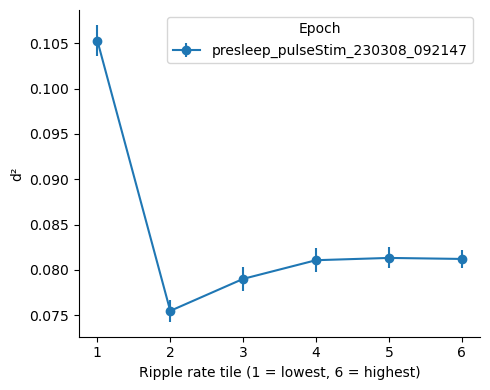

C:\Users\Cornell\AppData\Local\Temp\ipykernel_23228\4156693574.py:139: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'presleep_pulseStim_230308_092147' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- helpers ----------

def get_ripple_times(ripple_epochs):
    """
    ripple_epochs['data'] can be:
    - (n_events,) array of event times, or
    - (n_events, 2) array of [start, stop] -> we take centers.
    Returns 1D np.array of ripple times (seconds).
    """
    data = ripple_epochs.data
    if data.ndim == 2 and data.shape[1] == 2:    # start/stop
        return data.mean(axis=1)
    return data.ravel()


def add_ripple_rate(df, ripple_times, window=10.0):
    """
    For each center_s in df, count ripples in +-window/2 and
    compute rate (Hz). Adds column 'ripple_rate'.
    """
    centers = df["center_s"].to_numpy(float)
    ripple_times = np.sort(np.asarray(ripple_times, float))

    rates = np.zeros_like(centers, dtype=float)
    half = window / 2.0
    j0 = 0
    n = ripple_times.size

    for i, c in enumerate(centers):
        t0, t1 = c - half, c + half
        # advance left index
        while j0 < n and ripple_times[j0] < t0:
            j0 += 1
        j = j0
        cnt = 0
        while j < n and ripple_times[j] <= t1:
            cnt += 1
            j += 1
        rates[i] = cnt / window   # Hz

    out = df.copy()
    out["ripple_rate"] = rates
    return out


def aggregate_tiles_epoch(df_epoch, ntiles=6, value_col="d2", rate_col="ripple_rate"):
    """
    Given df restricted to one epoch, FORCE 6 tiles on ripple_rate and
    return a dataframe with tile index, mean and sem of value_col.
    """
    df_epoch = df_epoch.copy()

    # need non-NaN rates
    ok = df_epoch[rate_col].notna()
    if ok.sum() < ntiles:
        return pd.DataFrame(columns=["tile", "mean", "sem"])

    # ---- FORCE 6 tiles using rank transform ----
    # ranking ensures monotonic order but no collisions
    ranks = df_epoch.loc[ok, rate_col].rank(method="first")
    df_epoch.loc[ok, "tile"] = pd.qcut(
        ranks,
        q=ntiles,
        labels=False
    )

    # ---- aggregate ----
    g = df_epoch.groupby("tile")[value_col]
    agg = g.agg(["mean", "count", "std"]).reset_index()
    agg["sem"] = agg["std"] / np.sqrt(agg["count"].clip(lower=1))

    # ensure tiles appear sorted 0..5
    return agg.sort_values("tile")[["tile", "mean", "sem"]]


# ---------- main pipeline ----------
ca1_complete_df=out_df
# 1) ripple times from ripple_epochs
ripple_times = get_ripple_times(ripple_epochs)

# 2) add ripple rate per row to ca1_complete_df
ca1_with_rate = add_ripple_rate(ca1_complete_df, ripple_times, window=30.0)

# 3) process epoch 0 and 1 separately
epoch_ids = [7,0]
results = {}

for idx in epoch_ids:
    row = epoch_df.loc[idx]
    t0, t1 = float(row["startTime"]), float(row["stopTime"])

    df_ep = ca1_with_rate[
        (ca1_with_rate["center_s"] >= t0) &
        (ca1_with_rate["center_s"] <= t1)
    ].copy()

    res = aggregate_tiles_epoch(df_ep, ntiles=6, value_col="d2", rate_col="ripple_rate")
    results[idx] = (row["name"], res)

# 4) plot both epochs on the same subplot
fig, ax = plt.subplots(figsize=(5, 4))

for idx, (label, df_tiles) in results.items():
    if df_tiles.empty:
        continue
    x = df_tiles["tile"].to_numpy() + 1  # make tiles 1..6
    y = df_tiles["mean"].to_numpy()
    yerr = df_tiles["sem"].to_numpy()
    ax.errorbar(x, y, yerr=yerr, marker="o", linestyle="-", label=label)

ax.set_xlabel("Ripple rate tile (1 = lowest, 6 = highest)")
ax.set_ylabel("d²")
ax.set_xticks(range(1, 7))
ax.legend(title="Epoch")
# style: no grid, hide top/right spines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
# Make a copy so we don't overwrite original
ca1_with_rate = ca1_with_rate.copy()
ca1_with_rate["sleep_epoch"] = np.nan  # default

for idx in [0, 1]:    # or use epoch_ids variable
    row = epoch_df.loc[idx]
    t0, t1 = float(row["startTime"]), float(row["stopTime"])
    name = row["name"]

    # boolean mask for rows inside this epoch
    mask = (ca1_with_rate["center_s"] >= t0) & (ca1_with_rate["center_s"] <= t1)

    # assign epoch name
    ca1_with_rate.loc[mask, "sleep_epoch"] = name


In [ ]:
ca1_with_rate

,center_s,d2,d2_err,state,isi_entropy,n_spikes,ripple_rate,barrage_rate,sleep_epoch
0,531.0,0.130875,NaN,NREM,4.672515,1520,0.566667,0.000000,preSleep_220520_093731
1,906.0,0.117431,NaN,NREM,4.735006,1119,0.700000,0.000000,preSleep_220520_093731
2,908.0,0.111252,NaN,NREM,4.743293,1091,0.633333,0.000000,preSleep_220520_093731
3,910.0,0.117201,NaN,NREM,4.735423,1080,0.666667,0.000000,preSleep_220520_093731
4,912.0,0.136512,NaN,NREM,4.972276,1037,0.633333,0.000000,preSleep_220520_093731
...,...,...,...,...,...,...,...,...,...
6304,28406.0,0.098055,NaN,NREM,4.641524,934,0.400000,0.033333,NaN
6305,28408.0,0.097240,NaN,NREM,4.648294,942,0.400000,0.033333,NaN
6306,28410.0,0.102554,NaN,NREM,4.660061,908,0.333333,0.033333,NaN
6307,28412.0,0.117801,NaN,NREM,4.564813,864,0.300000,0.033333,NaN


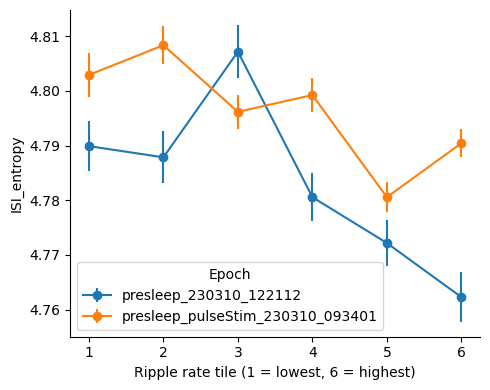

C:\Users\Cornell\AppData\Local\Temp\ipykernel_10988\754842864.py:48: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'presleep_pulseStim_230310_093401' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.


In [8]:
for idx in epoch_ids:
    row = epoch_df.loc[idx]
    t0, t1 = float(row["startTime"]), float(row["stopTime"])

    df_ep = ca1_with_rate[
        (ca1_with_rate["center_s"] >= t0) &
        (ca1_with_rate["center_s"] <= t1)
    ].copy()

    res = aggregate_tiles_epoch(df_ep, ntiles=6, value_col="isi_entropy", rate_col="ripple_rate")
    results[idx] = (row["name"], res)

# 4) plot both epochs on the same subplot
fig, ax = plt.subplots(figsize=(5, 4))

for idx, (label, df_tiles) in results.items():
    if df_tiles.empty:
        continue
    x = df_tiles["tile"].to_numpy() + 1  # make tiles 1..6
    y = df_tiles["mean"].to_numpy()
    yerr = df_tiles["sem"].to_numpy()
    ax.errorbar(x, y, yerr=yerr, marker="o", linestyle="-", label=label)

ax.set_xlabel("Ripple rate tile (1 = lowest, 6 = highest)")
ax.set_ylabel("ISI_entropy")
ax.set_xticks(range(1, 7))
ax.legend(title="Epoch")
# style: no grid, hide top/right spines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
# Make a copy so we don't overwrite original
ca1_with_rate = ca1_with_rate.copy()
ca1_with_rate["sleep_epoch"] = np.nan  # default

for idx in [0, 1]:    # or use epoch_ids variable
    row = epoch_df.loc[idx]
    t0, t1 = float(row["startTime"]), float(row["stopTime"])
    name = row["name"]

    # boolean mask for rows inside this epoch
    mask = (ca1_with_rate["center_s"] >= t0) & (ca1_with_rate["center_s"] <= t1)

    # assign epoch name
    ca1_with_rate.loc[mask, "sleep_epoch"] = name


In [ ]:
# import pickle
# out_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\background_uled"
# os.makedirs(out_dir, exist_ok=True)
# filename = f"{animal_name}_{day}.pkl"
# out_path = os.path.join(out_dir, filename)

# with open(out_path, "wb") as f:
#     pickle.dump(ca1_with_rate, f)
#     print(f"Saved: {out_path}")

Saved: D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\background_uled\NN2_day17.pkl


novel and familiar memory

In [ ]:
epoch_df

,name,startTime,stopTime,behavioralParadigm,environment,stimuli,notes,manipulation,basepath
0,presleep_220812_095335,0.0000,45.92940,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
1,presleep_stim_220812_095335,45.9294,14525.77915,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
2,training1_220812_140102,14525.7792,14902.66235,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
3,training2_220812_141229,14902.6624,15249.27355,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
4,training3_220812_142215,15249.2736,15585.80475,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
5,postsleep_220812_143800,15585.8048,30069.37595,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
6,test_220812_184448,30069.3760,30723.82715,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17


In [ ]:
# simplest: replace the substring anywhere in the name
# epoch_df["name"] = epoch_df["name"].str.replace("midseelp", "midsleep", regex=False)


In [ ]:
epoch_df

,name,startTime,stopTime,behavioralParadigm,environment,stimuli,notes,manipulation,basepath
0,presleep_220812_095335,0.0000,45.92940,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
1,presleep_stim_220812_095335,45.9294,14525.77915,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
2,training1_220812_140102,14525.7792,14902.66235,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
3,training2_220812_141229,14902.6624,15249.27355,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
4,training3_220812_142215,15249.2736,15585.80475,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17
5,postsleep_220812_143800,15585.8048,30069.37595,sleep,sleep,10uA uLED,first half,NaN,X:\data\Barrage\NN2\day17
6,test_220812_184448,30069.3760,30723.82715,Object Displacement,box,NaN,NaN,NaN,X:\data\Barrage\NN2\day17


In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# import re

# def label_epoch_from_name(name: str) -> str:
#     s = (str(name) or "").lower()

#     if "presleep" in s:  return "presleep"
#     if "midsleep"  in s: return "midsleep"
#     if "postsleep" in s: return "postsleep"

#     # --- task / T-maze markers ---
#     # match 't_' or 't1_' / 't2_' / ... anywhere (word-like), plus common aliases
#     if (re.search(r'(?:^|[^a-z])t(?:_|[0-9])', s)          # t_ or t#_
#         or "tmaze" in s or "t-maze" in s
#         or "freet" in s or "force" in s
#         or "task" in s):
#         return "task"

#     return "other"

# # --- normalize possible Data Wrangler column names ---
# def _normalize_epoch_columns(df: pd.DataFrame) -> pd.DataFrame:
#     tmp = df.copy()
#     # strip spaces and leading '#' from column names
#     tmp.columns = [c.strip().lstrip("#").strip() for c in tmp.columns]
#     # make sure required columns exist (startTime/stopTime/name)
#     rename_map = {}
#     for c in tmp.columns:
#         cl = c.lower()
#         if cl == "starttime": rename_map[c] = "startTime"
#         if cl == "stoptime":  rename_map[c] = "stopTime"
#         if cl == "name":      rename_map[c] = "name"
#     if rename_map:
#         tmp = tmp.rename(columns=rename_map)
#     missing = [c for c in ("name", "startTime", "stopTime") if c not in tmp.columns]
#     if missing:
#         raise KeyError(f"epoch_df missing required columns: {missing}")
#     return tmp

# def annotate_epochs(ca_df: pd.DataFrame, epoch_df: pd.DataFrame,
#                     enumerate_labels=("postsleeppp",),  # labels to number by order
#                     max_tasks=3):
#     tmp = _normalize_epoch_columns(epoch_df)[["name","startTime","stopTime"]].copy()
#     tmp["epoch_group"] = [label_epoch_from_name(n) for n in tmp["name"]]
#     tmp = tmp.dropna(subset=["startTime","stopTime"])
#     tmp = tmp[tmp["startTime"] < tmp["stopTime"]].copy()
#     tmp = tmp.sort_values("startTime").reset_index(drop=True)

#     # number selected labels (e.g., midsleep1, midsleep2, ...)
#     for lab in enumerate_labels:
#         m = tmp["epoch_group"].eq(lab)
#         if m.any():
#             idxs = tmp.index[m].tolist()
#             for k, i in enumerate(idxs, start=1):
#                 tmp.loc[i, "epoch_group"] = f"{lab}{k}"

#     # number first few task blocks as before
#     m_task = tmp["epoch_group"].eq("task")
#     if m_task.any():
#         task_order = tmp.index[m_task].tolist()
#         for i, idx in enumerate(task_order[:max_tasks], start=1):
#             tmp.loc[idx, "epoch_group"] = f"task{i}"

#     intervals = pd.IntervalIndex.from_arrays(tmp["startTime"].to_numpy(),
#                                              tmp["stopTime"].to_numpy(),
#                                              closed="left")
#     tmp = tmp.set_index(intervals)

#     ca = ca_df.copy()
#     centers = ca["center_s"].to_numpy()
#     idx = tmp.index.get_indexer(centers)
#     ca["epoch_group"] = np.where(idx >= 0, tmp.iloc[idx]["epoch_group"].to_numpy(), np.nan)
#     return ca


# # -------- 1) annotate ca1_complete_df with epoch_group --------
# ca_annot = annotate_epochs(ca1_complete_df, epoch_df)

# # -------- 2) filter to groups & make boxplots --------
# wanted_groups = ["presleep", "midsleep", "postsleep"]  # add "task" if you want a 4th box

# def plot_box_for_state(df_annot, state_label, groups=wanted_groups, title=None):
#     d = (df_annot
#          .loc[(df_annot["state"].astype(str).str.upper()==state_label.upper())
#               & (df_annot["epoch_group"].isin(groups))]
#          .copy())
#     if d.empty:
#         print(f"No rows for state={state_label}")
#         return

#     # order & tidy
#     d["epoch_group"] = pd.Categorical(d["epoch_group"], categories=groups, ordered=True)

#     # --- boxplot (matplotlib) ---
#     fig, ax = plt.subplots(figsize=(5.2,4.2))
#     data = [d.loc[d["epoch_group"]==g, "d2"].dropna().values for g in groups]
#     ax.boxplot(data, labels=[g.replace("sleep"," sleep") for g in groups],
#                showfliers=False, widths=0.6)
#     ax.set_xlabel("Epoch")
#     ax.set_ylabel("D²")
#     ax.set_title(title or f"{state_label}: D² by epoch")
#     for s in ("top","right"): ax.spines[s].set_visible(False)
#     plt.tight_layout()
#     plt.show()

#     # optional: quick stats readout (Kruskal–Wallis + pairwise Wilcoxon, paired only if the same file/session needed)
#     try:
#         from scipy.stats import kruskal, mannwhitneyu
#         stats_groups = [g for g in data if len(g) >= 5]
#         if len(stats_groups) >= 2:
#             H, p = kruskal(*stats_groups)
#             print(f"[{state_label}] Kruskal–Wallis across groups: H={H:.2f}, p={p:.3e}")
#         # pairwise (unpaired) Mann–Whitney as a lightweight summary
#         for i in range(len(groups)):
#             for j in range(i+1, len(groups)):
#                 gi, gj = data[i], data[j]
#                 if len(gi)>=5 and len(gj)>=5:
#                     U, p = mannwhitneyu(gi, gj, alternative="two-sided")
#                     print(f"  {groups[i]} vs {groups[j]}: U={U:.0f}, p={p:.3e}")
#     except Exception as e:
#         print("Stats skipped:", e)

# # NREM: compare pre/mid/post sleep
# ca_annot = annotate_epochs(ca1_complete_df, epoch_df)
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# # ---------- build normalized df ----------
# def first_n_per_epoch(df, n=1200):
#     """Return first n rows per epoch_group after sorting by center_s."""
#     return (df.sort_values("center_s")
#               .groupby("epoch_group", group_keys=False, observed=True)
#               .head(n))

# sleep_groups = ["presleep", "midsleep", "postsleep"]

# # 1) NREM only, sleep epochs only
# d = ca_annot.copy()
# d["state"] = d["state"].astype(str).str.upper()
# d = d[(d["state"] == "NREM") & (d["epoch_group"].isin(sleep_groups))].copy()

# # 2) take first 1200 rows per epoch
# d = first_n_per_epoch(d, n=1200)

# # 3) presleep mean
# pre = d[d["epoch_group"] == "presleep"]["d2"].dropna().to_numpy()
# if pre.size == 0:
#     raise ValueError("No presleep NREM rows found (first 1200).")
# m_pre = float(np.nanmean(pre))

# # safety for zero (very unlikely, but guard anyway)
# eps = 1e-12 if m_pre == 0 else 0.0

# # 4) normalize midsleep & postsleep
# d2_rel = d[d["epoch_group"].isin(["midsleep", "postsleep"])].copy()
# d2_rel["d2_rel"] = (d2_rel["d2"] - m_pre) / (d2_rel["d2"] + m_pre + eps)
# d2_rel["epoch_group"] = pd.Categorical(
#     d2_rel["epoch_group"], categories=["midsleep", "postsleep"], ordered=True
# )

# # ---------- plot (only midsleep & postsleep) ----------
# plt.figure(figsize=(5.4, 4.0))
# sns.boxplot(data=d2_rel, x="epoch_group", y="d2_rel", showfliers=False, width=0.6)
# sns.stripplot(data=d2_rel, x="epoch_group", y="d2_rel",
#               color="k", alpha=0.25, size=2, linewidth=0, dodge=False)
# plt.axhline(0, lw=1, ls="--", color="gray")  # zero = equal to presleep mean
# plt.xlabel("")
# plt.ylabel(r"(sleep − presleep) / (sleep + presleep)")
# plt.title("NREM (first 1200 rows): midsleep & postsleep vs presleep baseline")
# ax = plt.gca()
# ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
# plt.tight_layout(); plt.show()

# # (optional) quick text readout
# print(f"Presleep mean D² (NREM, first 1200 rows): {m_pre:.4g}")
# for g in ["midsleep", "postsleep"]:
#     vals = d2_rel.loc[d2_rel["epoch_group"]==g, "d2_rel"].dropna().to_numpy()
#     if vals.size:
#         print(f"{g}: n={vals.size}, median={np.median(vals):.3f}, mean={np.mean(vals):.3f}")


In [ ]:
# from pathlib import Path
# out_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\novel_familiar\novel"
# # --- save d2_rel ---
# Path(out_dir).mkdir(parents=True, exist_ok=True)
# save_path = Path(out_dir) / f"{animal_name}_{day}.pkl"
# d2_rel.to_pickle(save_path)
# print(f"Saved: {save_path}")


In [ ]:
# import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# # --- trials -> IntervalIndex (handles ragged shapes) ---
# def trials_interval_index(trials, closed="left"):
#     a = np.asarray(trials, float)
#     a = a.reshape(-1, 2)                      # (N,2)
#     ok = np.isfinite(a).all(1) & (a[:,1] > a[:,0])
#     a = a[ok]
#     return pd.IntervalIndex.from_arrays(a[:,0], a[:,1], closed=closed)

# import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# # --- helpers ---
# def trials_interval_index(trials, closed="left"):
#     a = np.asarray(trials, float).reshape(-1, 2)
#     ok = np.isfinite(a).all(1) & (a[:,1] > a[:,0])
#     a = a[ok]
#     return pd.IntervalIndex.from_arrays(a[:,0], a[:,1], closed=closed)

# def epoch_bounds(epoch_df):
#     """Return dict: {'task1': (start, stop), 'task2': ..., ...}"""
#     tmp = epoch_df.copy()
#     cols = {c.lower(): c for c in tmp.columns}
#     sC, eC, nC = cols['starttime'], cols['stoptime'], cols['name']
#     # label + number tasks in time order
#     lab = tmp[nC].astype(str).str.lower()
#     is_task = (lab.str.contains(r'(?:^|[^a-z])t(?:_|[0-9])')) | lab.str.contains('tmaze|t-maze|task|freet|forcet')
#     order = tmp[is_task].sort_values(sC).index.tolist()
#     out = {}
#     for i, idx in enumerate(order[:3], start=1):
#         out[f"task{i}"] = (float(tmp.at[idx, sC]), float(tmp.at[idx, eC]))
#     return out

# def select_first10_in_and_out(d_epoch, trial_iv_epoch, n_out=5):
#     """Rows inside first-10 trials + first-10 out-of-trial samples by time."""
#     # in-trial membership
#     loc = trial_iv_epoch.get_indexer(d_epoch["center_s"].to_numpy(float))
#     in_mask = (loc >= 0)

#     # keep *all* rows that fall in those selected trials
#     d_in  = d_epoch.loc[in_mask].copy()

#     # among out-of-trial rows, keep the *earliest* n_out by time
#     d_out = d_epoch.loc[~in_mask].sort_values("center_s").head(n_out).copy()
#     d_in["trial_bin"]  = "in-trial"
#     d_out["trial_bin"] = "out-of-trial"
#     return pd.concat([d_in, d_out], ignore_index=True)

# # --- build objects ---
# trial_iv_all = trials_interval_index(trials)
# epoch_iv = epoch_bounds(epoch_df)  # needs epoch_df with startTime/stopTime/name

# # base WAKE dataframe limited to task epochs we care about
# wake_groups = ["task1","task2","task3"]
# d0 = ca_annot[(ca_annot["state"].astype(str).str.upper()=="WAKE") &
#               (ca_annot["epoch_group"].isin(wake_groups))].copy()

# parts = []
# for g in wake_groups:
#     if g not in epoch_iv:  # skip if this task doesn't exist
#         continue
#     s, e = epoch_iv[g]

#     # rows of this epoch
#     de = d0[d0["epoch_group"].eq(g)].copy()
#     if de.empty:
#         continue

#     # trials that start within this epoch → first 10
#     ta = np.asarray(trials, float).reshape(-1, 2)
#     ok = np.isfinite(ta).all(1) & (ta[:,1] > ta[:,0])
#     ta = ta[ok]
#     t_in_epoch = ta[(ta[:,0] >= s) & (ta[:,0] < e)]
#     t_in_epoch = t_in_epoch[:10] if len(t_in_epoch) > 10 else t_in_epoch
#     if t_in_epoch.size == 0:
#         # no trials found → just take the first 10 out-of-trial samples
#         parts.append(de.sort_values("center_s").head(10).assign(trial_bin="out-of-trial"))
#         continue

#     trial_iv_epoch = pd.IntervalIndex.from_arrays(t_in_epoch[:,0], t_in_epoch[:,1], closed="left")

#     parts.append(select_first10_in_and_out(de, trial_iv_epoch, n_out=10))

# d = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
# if d.empty:
#     print("No data after selection.")
# else:
#     d["epoch_group"] = pd.Categorical(d["epoch_group"], categories=wake_groups, ordered=True)
#     d["trial_bin"]   = pd.Categorical(d["trial_bin"],   categories=["in-trial","out-of-trial"], ordered=True)

#     # --- plot ---
#     plt.figure(figsize=(6.2,4.2))
#     sns.boxplot(data=d, x="epoch_group", y="d2", hue="trial_bin",
#                 order=wake_groups, hue_order=["in-trial","out-of-trial"],
#                 showfliers=False)
#     sns.stripplot(data=d, x="epoch_group", y="d2", hue="trial_bin",
#                   order=wake_groups, hue_order=["in-trial","out-of-trial"],
#                   dodge=True, color="k", alpha=0.2, size=2, linewidth=0)
#     plt.xlabel("Task epoch")
#     plt.ylabel("D²")
#     plt.title("WAKE: D² (first 10 trials) vs first 10 out-of-trial samples")
#     plt.legend(title="", frameon=False)
#     ax = plt.gca(); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
#     plt.tight_layout(); plt.show()


In [ ]:
# import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# # ===================== PARAMS =====================
# running_thresh = 2.5      # speed threshold (units of your speed)
# smooth_window_s = 0.5      # smoothing window (s) for speed
# min_bout_s = 1           # remove running/quiescent bouts shorter than this
# wake_only = True            # if ca_annot has 'state', limit to WAKE
# use_first10_trials_per_task = True
# wake_groups = ["task1","task2","task3"]
# # =================================================

# # ---------- helpers ----------
# def trials_interval_index(trials, closed="left"):
#     a = np.asarray(trials, float).reshape(-1, 2)
#     ok = np.isfinite(a).all(1) & (a[:,1] > a[:,0])
#     a = a[ok]
#     return pd.IntervalIndex.from_arrays(a[:,0], a[:,1], closed=closed)

# def epoch_bounds(epoch_df):
#     """Return dict: {'task1': (start, stop), ...} by start time order."""
#     tmp = epoch_df.copy()
#     cols = {c.lower(): c for c in tmp.columns}
#     sC, eC, nC = cols['starttime'], cols['stoptime'], cols['name']
#     lab = tmp[nC].astype(str).str.lower()
#     is_task = (lab.str.contains(r'(?:^|[^a-z])t(?:_|[0-9])')) | lab.str.contains('tmaze|t-maze|task|freet|forcet')
#     order = tmp[is_task].sort_values(sC).index.tolist()
#     out = {}
#     for i, idx in enumerate(order[:3], start=1):
#         out[f"task{i}"] = (float(tmp.at[idx, sC]), float(tmp.at[idx, eC]))
#     return out

# def moving_average_uniform(x, win):
#     if win <= 1: return x.copy()
#     w = np.ones(int(win), float) / int(win)
#     return np.convolve(x, w, mode="same")

# def enforce_min_bout(mask_bool, t, min_len_s):
#     m = mask_bool.astype(bool).copy()
#     idx = np.flatnonzero(np.r_[True, m[1:] != m[:-1], True])
#     for i in range(len(idx)-1):
#         s, e = idx[i], idx[i+1]
#         dur = t[e-1] - t[s] if e > s else 0.0
#         if dur < min_len_s:
#             val = m[s-1] if s > 0 else (m[e] if e < m.size else m[s])
#             m[s:e] = val
#     return m

# def running_label_at_times(speed, center_times, *, thr, smooth_s, min_bout_s):
#     """Return array of 'running'/'quiescence' at each center time."""
#     t = np.asarray(speed[:,0], float)
#     v = np.asarray(speed[:,1], float)
#     order = np.argsort(t)
#     t = t[order]; v = v[order]
#     dt = np.median(np.diff(t[np.isfinite(t)]))
#     win = max(1, int(round(smooth_s / dt)))
#     v_sm = moving_average_uniform(v, win)
#     run_mask = enforce_min_bout(v_sm >= thr, t, min_bout_s)

#     # sample the boolean mask at each center time by “last known value” (left-closed)
#     idx = np.searchsorted(t, np.asarray(center_times, float), side="right") - 1
#     idx = np.clip(idx, 0, len(t)-1)
#     return np.where(run_mask[idx], "running", "quiescence")

# # ---------- build selection (first-10 trials in each task; keep same as your code) ----------
# trial_iv_all = trials_interval_index(trials)
# epoch_iv = epoch_bounds(epoch_df)

# d0 = ca_annot.copy()
# if 'state' in d0.columns and wake_only:
#     d0 = d0[d0['state'].astype(str).str.upper() == 'WAKE'].copy()
# if 'epoch_group' in d0.columns:
#     d0 = d0[d0['epoch_group'].isin(wake_groups)].copy()

# if use_first10_trials_per_task and 'epoch_group' in d0.columns:
#     parts = []
#     ta_all = np.asarray(trials, float).reshape(-1, 2)
#     ok = np.isfinite(ta_all).all(1) & (ta_all[:,1] > ta_all[:,0])
#     ta_all = ta_all[ok]

#     for g in wake_groups:
#         if g not in epoch_iv: 
#             continue
#         s, e = epoch_iv[g]
#         de = d0[d0['epoch_group'].eq(g)].copy()
#         if de.empty: 
#             continue
#         t_in_epoch = ta_all[(ta_all[:,0] >= s) & (ta_all[:,0] < e)]
#         t_in_epoch = t_in_epoch[:10] if len(t_in_epoch) > 10 else t_in_epoch

#         if t_in_epoch.size == 0:
#             parts.append(de.sort_values('center_s').head(10).assign(in_out='out-of-trial'))
#             continue

#         trial_iv_epoch = pd.IntervalIndex.from_arrays(t_in_epoch[:,0], t_in_epoch[:,1], closed="left")
#         loc = trial_iv_epoch.get_indexer(de['center_s'].to_numpy(float))
#         de['in_out'] = np.where(loc >= 0, 'in-trial', 'out-of-trial')
#         # keep all in-trial rows + earliest 10 out-of-trial
#         de_in  = de[de['in_out'] == 'in-trial'].copy()
#         de_out = de[de['in_out'] == 'out-of-trial'].sort_values('center_s').head(10).copy()
#         parts.append(pd.concat([de_in, de_out], ignore_index=True))

#     d = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
# else:
#     # simpler path: use all rows and mark in/out from *all* trials
#     d = d0.copy()
#     if not d.empty:
#         loc = trial_iv_all.get_indexer(d['center_s'].to_numpy(float))
#         d['in_out'] = np.where(loc >= 0, 'in-trial', 'out-of-trial')

# if d.empty:
#     print("No data after selection.")
# else:
#     # ---------- add running/quiescence at each center_s ----------
#     d['run_bin'] = running_label_at_times(
#         speed, d['center_s'].to_numpy(float),
#         thr=running_thresh, smooth_s=smooth_window_s, min_bout_s=min_bout_s
#     )

#     # tidy categories
#     d['in_out'] = pd.Categorical(d['in_out'], categories=['in-trial','out-of-trial'], ordered=True)
#     d['run_bin'] = pd.Categorical(d['run_bin'], categories=['quiescence','running'], ordered=True)

#     # ---------- PLOTS ----------
#     # A) Box/strip of D² by in/out with hue=running
#     plt.figure(figsize=(6.8, 4.2))
#     sns.boxplot(data=d, x='in_out', y='d2', hue='run_bin', showfliers=False)
#     sns.stripplot(data=d, x='in_out', y='d2', hue='run_bin',
#                   dodge=True, color='k', alpha=0.25, size=2, linewidth=0)
#     plt.xlabel("")
#     plt.ylabel("D²")
#     plt.title("D² at center_s: in-trial vs out-of-trial × running state")
#     # de-duplicate legends from double plotting
#     handles, labels = plt.gca().get_legend_handles_labels()
#     bylab = dict(zip(labels, handles))
#     plt.legend(bylab.values(), bylab.keys(), frameon=False, title="")
#     ax = plt.gca(); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
#     plt.tight_layout(); plt.show()

#     # (optional) If you also want per-task panels when epoch_group exists:
#     if 'epoch_group' in d.columns:
#         d['epoch_group'] = pd.Categorical(d['epoch_group'], categories=wake_groups, ordered=True)
#         g = sns.catplot(
#             data=d, x='in_out', y='d2', hue='run_bin',
#             col='epoch_group', kind='box', sharey=True, showfliers=False,
#             height=3.2, aspect=0.9
#         )
#         g.set_axis_labels("", "D²")
#         g.fig.set_size_inches(12, 6)   # total W×H for the whole figure
#         g.fig.subplots_adjust(top=0.82)
#         g.fig.suptitle("D² by in/out × running state (per task)")
#         for ax in g.axes.flatten():
#             ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
#         plt.show()


ISI entropy

In [ ]:
# out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats")
# out_dir.mkdir(parents=True, exist_ok=True)

# fname = f"{animal_name}_{day}_{brain_region}.pkl"
# save_path = out_dir / fname

# ca1_complete_df.to_pickle(save_path)
# print(f"Saved to: {save_path}")

In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from typing import Iterable

# # =========================
# # ISI entropy
# # =========================
# def isi_entropy(spike_times, n_bins=20):
#     """
#     Shannon entropy (bits) of log10(ISI) distribution.
#     Returns NaN if fewer than 2 ISIs (i.e., <3 spikes).
#     """
#     st = np.asarray(spike_times, float)
#     st = st[np.isfinite(st)]
#     st = np.unique(np.sort(st))
#     if st.size < 3:
#         return np.nan
#     isis = np.diff(st)
#     isis = isis[np.isfinite(isis) & (isis > 0)]
#     if isis.size < 2:
#         return np.nan
#     x = np.log10(isis)
#     hist, _ = np.histogram(x, bins=n_bins)
#     N = hist.sum()
#     if N <= 0:
#         return np.nan
#     p = hist.astype(float) / N
#     p = p[p > 0]
#     return float(-np.sum(p * np.log2(p)))  # bits

# # =========================
# # Utilities
# # =========================
# def _flatten_spikes(spike_times):
#     """Pool spike times across inputs and return sorted unique float seconds."""
#     if isinstance(spike_times, dict):
#         parts = [np.asarray(v, float).ravel() for v in spike_times.values()]
#         x = np.concatenate([p[np.isfinite(p)] for p in parts]) if parts else np.array([], float)
#     else:
#         arr = np.asarray(spike_times, dtype=object)
#         if arr.dtype == object:
#             parts = []
#             for it in arr:
#                 if it is None:
#                     continue
#                 v = np.asarray(it, float).ravel()
#                 v = v[np.isfinite(v)]
#                 if v.size:
#                     parts.append(v)
#             if parts:
#                 x = np.concatenate(parts)
#             else:
#                 try:
#                     x = np.asarray(spike_times, float).ravel()
#                 except (TypeError, ValueError):
#                     x = np.array([], float)
#         else:
#             x = arr.astype(float).ravel()
#     x = x[np.isfinite(x)]
#     return np.sort(np.unique(x))

# def _coerce_epochs(ep):
#     """Coerce many epoch formats to a sorted list[(start, stop)]. Accepts ep, or ep.data with ≥2 columns."""
#     # Try .data first (Epoch-like objects)
#     if hasattr(ep, "data"):
#         vals = getattr(ep, "data")
#         try:
#             if isinstance(vals, pd.DataFrame) and vals.shape[1] >= 2:
#                 a = vals.iloc[:, 0].astype(float).to_numpy()
#                 b = vals.iloc[:, 1].astype(float).to_numpy()
#                 out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
#                 out.sort(key=lambda t: t[0]); return out
#             vals = np.asarray(vals)
#             if vals.ndim == 2 and vals.shape[1] >= 2:
#                 a = vals[:, 0].astype(float); b = vals[:, 1].astype(float)
#                 out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
#                 out.sort(key=lambda t: t[0]); return out
#         except Exception:
#             pass

#     # DataFrame
#     if isinstance(ep, pd.DataFrame):
#         if {'start','stop'}.issubset(ep.columns):
#             a = ep['start'].astype(float).to_numpy()
#             b = ep['stop'].astype(float).to_numpy()
#         elif {'startTime','stopTime'}.issubset(ep.columns):
#             a = ep['startTime'].astype(float).to_numpy()
#             b = ep['stopTime'].astype(float).to_numpy()
#         else:
#             a = ep.iloc[:,0].astype(float).to_numpy()
#             b = ep.iloc[:,1].astype(float).to_numpy()
#         out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
#         out.sort(key=lambda t: t[0]); return out

#     # Iterable of pairs
#     if isinstance(ep, Iterable):
#         out = []
#         for item in ep:
#             try:
#                 s, e = item
#                 s, e = float(s), float(e)
#                 if np.isfinite(s) and np.isfinite(e) and e > s:
#                     out.append((s, e))
#             except Exception:
#                 pass
#         out.sort(key=lambda t: t[0]); return out

#     return []

# def _count_events(event_epochs, a, b):
#     """Count events whose mid-point falls in [a,b)."""
#     c = 0
#     for s, e in event_epochs:
#         if not np.isfinite(s) or not np.isfinite(e) or e <= s:
#             continue
#         mid = 0.5 * (s + e)
#         if a <= mid < b:
#             c += 1
#     return c

# # =========================
# # Core: ISI entropy per window + ripple/barrage rates
# # =========================
# def isi_entropy_windows_with_tiles(
#     spike_times,
#     centers_df,                 # must have columns: center_s, state
#     ripple_epochs,
#     barrage_epochs,
#     state_filter="NREM",
#     window=10.0,                # seconds (±15s)
#     min_spikes=3,               # require ≥3 spikes in window to form ≥2 ISIs
#     n_bins_isi=20               # histogram bins for log10(ISI)
# ):
#     st = _flatten_spikes(spike_times)
#     out_cols = ["center_s","state","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
#     if st.size == 0:
#         return pd.DataFrame(columns=out_cols)

#     # centers (NREM only by default)
#     # centers (NREM only by default)
#     if "state" in centers_df.columns:
#         sel = centers_df["state"].astype(str).str.upper() == str(state_filter).upper()
#         cdf = centers_df.loc[sel & centers_df["center_s"].notna()].copy()
#     else:
#         cdf = centers_df.loc[centers_df["center_s"].notna()].copy()
#         cdf["state"] = state_filter

#     if centers.size == 0:
#         return pd.DataFrame(columns=out_cols)

#     rip = _coerce_epochs(ripple_epochs)
#     bar = _coerce_epochs(barrage_epochs)

#     half = window/2.0
#     rows = []
#     for i, (c, s) in enumerate(zip(
#         cdf["center_s"].to_numpy(float),
#         cdf["state"].astype(str).to_numpy()
#     )):
#         a, b = c - half, c + half
#         # spikes in window
#         wst = st[(st >= a) & (st < b)]
#         nsp = int(wst.size)

#         if nsp >= min_spikes:
#             H = isi_entropy(wst, n_bins=n_bins_isi)
#         else:
#             H = np.nan

#         dur = b - a
#         if dur > 0:
#             rr = _count_events(rip, a, b) / dur
#             br = _count_events(bar, a, b) / dur
#         else:
#             rr = np.nan; br = np.nan

#         # start with all original metadata from centers_df (current row index)
#         row_dict = cdf.iloc[i].to_dict()

#         # add new fields
#         row_dict.update({
#             "isi_entropy": H,
#             "n_spikes": nsp,
#             "ripple_rate": rr,
#             "barrage_rate": br
#         })

#         rows.append(row_dict)

#     out = pd.DataFrame(rows).sort_values("center_s").reset_index(drop=True)
#     print(out.head())
#     return out

# # =========================
# # Tile aggregation (6 tiles) and plotting
# # =========================
# def _make_tiles(series, k=6):
#     """Return categorical Q1..Qk for the given series using quantiles; robust to ties."""
#     v = pd.Series(series.to_numpy(float))
#     ok = np.isfinite(v)
#     if ok.sum() == 0:
#         return pd.Categorical([np.nan] * len(v), categories=[f"Q{i}" for i in range(1, k+1)], ordered=True)
#     try:
#         # Use up to k quantiles, but not more than unique values
#         q = min(k, max(1, v[ok].nunique()))
#         labels = [f"Q{i}" for i in range(1, q+1)]
#         lab = pd.qcut(v[ok], q=q, labels=labels, duplicates="drop")
#     except ValueError:
#         # Fallback to rank-based tiling
#         r = v[ok].rank(method="first")
#         q = min(k, max(1, r.nunique()))
#         if q == 1:
#             lab = pd.Categorical(['Q1']*ok.sum(), categories=['Q1'], ordered=True)
#         else:
#             labels = [f"Q{i}" for i in range(1, q+1)]
#             lab = pd.qcut(r, q=q, labels=labels, duplicates='drop')

#     # place back with full set Q1..Qk (even if some are empty)
#     out_cats = [f"Q{i}" for i in range(1, k+1)]
#     out = pd.Series(pd.Categorical([np.nan]*len(v), categories=out_cats, ordered=True))
#     out.loc[v.index[ok]] = lab
#     return out

# def aggregate_tiles(df, by="ripple", value_col="isi_entropy", k=6):
#     """
#     Aggregate 'value_col' by k quantile tiles of 'ripple_rate' or 'barrage_rate'.
#     Returns a tidy DataFrame with mean, SEM, and n per tile.
#     """
#     assert by in ("ripple", "barrage")
#     rate_col = "ripple_rate" if by == "ripple" else "barrage_rate"
#     tile_col = "tile_ripple" if by == "ripple" else "tile_barrage"

#     dd = df.dropna(subset=[value_col, rate_col]).copy()
#     if dd.empty:
#         cats = [f"Q{i}" for i in range(1, k+1)]
#         return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
#                              f"{value_col}_mean": pd.Series([], dtype=float),
#                              f"{value_col}_sem": pd.Series([], dtype=float),
#                              "n": pd.Series([], dtype=int)})

#     dd[tile_col] = _make_tiles(dd[rate_col], k=k)
#     if dd[tile_col].isna().all():
#         cats = [f"Q{i}" for i in range(1, k+1)]
#         return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
#                              f"{value_col}_mean": pd.Series([], dtype=float),
#                              f"{value_col}_sem": pd.Series([], dtype=float),
#                              "n": pd.Series([], dtype=int)})

#     g = dd.groupby(tile_col, observed=False)
#     res = g.agg(**{
#         f"{value_col}_mean": (value_col, "mean"),
#         f"{value_col}_sem":  (value_col, lambda x: x.std(ddof=1) / np.sqrt(max(1, x.count()))),
#         "n":                 (value_col, "count")
#     }).reset_index()

#     cats = dd[tile_col].cat.categories
#     res[tile_col] = pd.Categorical(res[tile_col], categories=cats, ordered=True)
#     res = res.set_index(tile_col).reindex(cats).reset_index()
#     res['n'] = res['n'].fillna(0).astype(int)
#     return res

# def _style(ax):
#     ax.grid(False)
#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)

# def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
#                     suptitle="ISI entropy vs ripple/barrage rate tiles"):
#     fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
#     y_label = "ISI entropy (bits)"

#     panels = [
#         (axes[0], tiles_ripple, "tile_ripple",  "Ripple rate quantiles"),
#         (axes[1], tiles_barrage,"tile_barrage", "Barrage rate quantiles")
#     ]
#     for ax, tiles, lab, title in panels:
#         if tiles is None or tiles.empty or (lab not in tiles.columns) or (f"{value_col}_mean" not in tiles.columns):
#             ax.text(0.5, 0.5, "No data", ha="center", va="center"); _style(ax); ax.set_title(title); continue
#         tp = tiles.dropna(subset=[f"{value_col}_mean"]).copy()
#         if tp.empty:
#             ax.text(0.5, 0.5, "No valid data", ha="center", va="center"); _style(ax); ax.set_title(title); continue

#         x = np.arange(len(tp))
#         y = tp[f"{value_col}_mean"].to_numpy(float)
#         yerr = tp[f"{value_col}_sem"].fillna(0).to_numpy(float)
#         ax.errorbar(x, y, yerr=yerr, fmt="-o", lw=1.8, ms=5, capsize=3, elinewidth=1.2)
#         xt = [f"{lvl} (n={int(n)})" for lvl, n in zip(tp[lab].astype(str), tp["n"].to_numpy())]
#         ax.set_xticks(x); ax.set_xticklabels(xt, rotation=30, ha='right')
#         ax.set_xlabel("Quantile tile"); ax.set_ylabel(y_label + " (mean ± SEM)")
#         ax.set_title(title); _style(ax)

#     fig.suptitle(suptitle, y=1.05); fig.tight_layout(rect=[0, 0.03, 1, 0.95])
#     return fig

# # =========================
# # Example usage (adapt to your data)
# # =========================
# # Required inputs you already have in your workspace:
# #   - spike_times: array/list/dict of spike timestamps (sec)
# #   - ca1_complete_df: DataFrame with ['center_s','state']
# #   - ripple_epochs, barrage_epochs: epoch objects (with .data), DataFrames, or list[(start,stop)]
# #
# centers_df = ca1_complete_df
# out_df = isi_entropy_windows_with_tiles(
#     spike_times=spike_times,
#     centers_df=centers_df,
#     ripple_epochs=ripple_epochs,       # pass the objects; the function will read .data if present
#     barrage_epochs=barrage_epochs,
#     state_filter="NREM",
#     window=30.0,                       # ±15 s
#     min_spikes=3,                      # need ≥3 spikes in window
#     n_bins_isi=40
# )




In [ ]:
# # Make 6-quantile tiles by ripple/barrage rate and plot
# tiles_rip = aggregate_tiles(out_df, by="ripple",  value_col="isi_entropy", k=6)
# tiles_rip = tiles_rip.reset_index().rename(columns={'index': 'tile_ripple'})

# tiles_rip_d2 = aggregate_tiles(out_df, by="ripple",  value_col="d2", k=6)
# tiles_rip_d2 = tiles_rip_d2.reset_index().rename(columns={'index': 'tile_ripple'})
# plt.show()

# fig = plot_tiles_line(tiles_rip, None, value_col="isi_entropy",
#                       suptitle="NREM ISI entropy vs ripple/barrage tiles")
# fig=plot_tiles_line(tiles_rip_d2, None, value_col="d2",
#                       suptitle="NREM D² vs ripple tiles")   

# plt.show()

In [ ]:
# import pickle
# save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats"  # <-- your target folder
# os.makedirs(save_dir, exist_ok=True)

# # build filename and save
# fname = f"{animal_name}_{day}.pkl"
# save_path = os.path.join(save_dir, fname)

# with open(save_path, "wb") as f:
#     pickle.dump({"per_center": out_df,
#                  "animal_name": animal_name,
#                  "day": day}, f)

# print(f"✅ Saved {save_path}")


In [ ]:
# # Make 6-quantile tiles by ripple/barrage rate and plot
# tiles_rip = aggregate_tiles(out_df, by="ripple",  value_col="isi_entropy", k=6)
# tiles_rip = tiles_rip.reset_index().rename(columns={'index': 'tile_ripple'})

# tiles_rip_d2 = aggregate_tiles(out_df, by="ripple",  value_col="d2", k=6)
# tiles_rip_d2 = tiles_rip_d2.reset_index().rename(columns={'index': 'tile_ripple'})
# plt.show()

# fig = plot_tiles_line(tiles_rip, None, value_col="isi_entropy",
#                       suptitle="NREM ISI entropy vs ripple/barrage tiles")
# fig=plot_tiles_line(tiles_rip_d2, None, value_col="d2",
#                       suptitle="NREM D² vs ripple tiles")   

# plt.show()

NREM timecourse

In [ ]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from scipy.stats import sem

# # ----------------------------------------------------
# # 1) Filter NREM + desired sleep epochs
# # ----------------------------------------------------
# df = ca1_complete_df.copy()

# # If your annotate function made column "sleep_epoch"
# # with values: "presleep", "midsleep", "postsleep"
# keep_epochs = ["presleep", "midsleep", "postsleep"]

# df_nrem = df[
#     (df["state"] == "NREM") &
#     (df["sleep_epoch"].isin(keep_epochs))
# ].copy()

# # Drop NaN d2
# df_nrem = df_nrem[df_nrem["d2"].notna()]


# # ----------------------------------------------------
# # 2) Bin time into 10-min windows
# # ----------------------------------------------------
# BIN = 600.0  # 10 minutes in seconds
# df_nrem["bin"] = (df_nrem["center_s"] // BIN).astype(int)


# # ----------------------------------------------------
# # 3) Compute mean and SEM per epoch × bin
# # ----------------------------------------------------
# grouped = (
#     df_nrem.groupby(["sleep_epoch", "bin"])
#     .agg(
#         d2_mean=("d2", "mean"),
#         d2_sem=("d2", sem),
#         t_center=("center_s", "mean")  # for plotting x-axis in seconds
#     )
#     .reset_index()
# )

# # Convert t_center into hours for nicer plotting
# grouped["t_hr"] = grouped["t_center"] / 3600.0


# # ----------------------------------------------------
# # 4) Plot timecourse: presleep / midsleep / postsleep
# # ----------------------------------------------------
# plt.figure(figsize=(10,5))

# epoch_colors = {
#     "presleep": "#1f77b4",
#     "midsleep": "#2ca02c",
#     "postsleep": "#d62728"
# }

# for ep in keep_epochs:
#     sub = grouped[grouped["sleep_epoch"] == ep]
#     plt.errorbar(
#         sub["t_hr"], sub["d2_mean"],
#         yerr=sub["d2_sem"],
#         marker="o", capsize=3,
#         label=ep,
#         color=epoch_colors.get(ep, None)
#     )

# plt.xlabel("Time (hr)")
# plt.ylabel("d²")
# plt.title("d² timecourse (10-min bins) across sleep epochs")
# plt.legend()
# plt.tight_layout()
# plt.show()
